<div align="center">

**REACH FOR CHANGE GROUP PROJECT**
<br>
<br>
DATA SCIENCE AND MACHINE LEARNING
<br>
<br>
**NOVA IMS – INFORMATION MANAGEMENT SCHOOL**
<br>
<br>
POST-GRADUATE PROGRAM IN ENTERPRISE DATA SCIENCE AND ANALYTICS
<br>
<br>
GROUP ELEMENTS<br>
Beatriz Farreca      20250984 <br>
João Carvalho         20250977 <br>
Ricardo Barracho     20250986 <br>
Tomás Valverde        20250983 <br>


</div>

<br>

----

<div align="center">

  ## TABLE OF CONTENTS

</div>

1. [Introduction](#introduction)
2. [Initial Setup and Imports](#initial-setup-and-imports)
3. [Exploratory Data Analysis (EDA)](#exploratory-data-analysis-eda)
4. [Data Preparation](#data-preparation)
    * 4.1. [Preprocessing Data](#preprocessing-data)
    * 4.2. [Data Cleaning](#data-cleaning)
    * 4.3. [Feature Engineering](#feature-engineering)
      * 4.3.1. [Donation_Behaviour](#donation-behavior)
      * 4.3.2. [Donation Engagement](#donation-engagement)
5. [Modelling](#modeling)
    * 5.1. [Donation Behavior (Clustering)](#donation-behavior-1)
    * 5.2. [Donation Engagement (Clustering)](#donation-engagement-1)
6. [Action Plan](#conclusions)

<br>

----


# 1. Introduction <a name="introduction"></a>

<div align="justify">

In recent years, non-profit organizations have faced an unexpected challenge: while causes grow the donor tolerance for generic approaches is decreasing. The repeated solicitations has led to lower engagement and long-term disengagement from the supporters and left a feeling of overwhelmness in potential supporters.

The Civic Support Alliance (CSA) has decided to modernize how outreach campaigns are conducted, by abandoning the mass contact strategy in favor of a personalized approach focused on donors characteristics. Their hope is to surpass this challenge that has been arising.

**Purpose:** Our primary focus relies on performing a deep exploratory data analysis to segmentate the CSA database. The goal is to create meaningful ways of identifying who the donors are, how they behave and how they naturally group together.
To achieve this, the project has a focus on how the data was prepared, implemented and optimized to undergo in algorithms of Unsupervised Learning.


</div>

---

# 2. Initial Setup and Imports


In [ ]:
path="path"

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.impute import KNNImputer
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster import hierarchy
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score

In [3]:
def plot_corr_num(subset, title):
  """ This function receives a df subset and creates a heatmap of the correlation matrix """
  df_num = subset.select_dtypes(include=["number"])
  corr = df_num.corr(method='spearman')
  plt.figure(figsize=(15, 10))
  sns.heatmap(corr, annot=True, cmap='coolwarm', center=0, linewidths=.5)
  plt.title(title)
  plt.tight_layout()
  plt.show()

In [4]:
def boxplot_hist(data_frame, name_col, color_name = 'b'):
  fig, (ax1,ax2) = plt.subplots(1,2 , figsize = (16,4))
  sns.histplot(ax = ax1, data = data_frame[name_col], color = color_name)
  sns.boxplot(ax=ax2, data = data_frame, x = name_col)
  plt.show()

In [5]:
def box_plot(col_name):
  fig, axes = plt.subplots(1, 2, figsize=(14,5))
  sns.boxplot(x=df[col_name.upper()], ax=axes[0], color='green')
  axes[0].set_title("Pre-Processing")
  axes[0].set_xlabel(f"{col_name}")
  sns.boxplot(x=df_copy[col_name], ax=axes[1], color='royalblue')
  axes[1].set_title("Post-Processing")
  axes[1].set_xlabel(f"{col_name}")
  plt.suptitle(f"Visual Validation: {col_name} Processing")
  plt.tight_layout()
  plt.show()

In [6]:
def hist_plot(col_name):
  fig, axes = plt.subplots(1, 2, figsize=(14,5))
  sns.histplot(x=df[col_name.upper()], ax=axes[0], color='green')
  axes[0].set_title("Pre-Processing")
  axes[0].set_xlabel(f"{col_name}")
  sns.histplot(x=df_copy[col_name], ax=axes[1], color='royalblue')
  axes[1].set_title("Post-Processing")
  axes[1].set_xlabel(f"{col_name}")
  plt.suptitle(f"Visual Validation: {col_name} Processing")
  plt.tight_layout()
  plt.show()

In [7]:
def count_plot(col_name, order_name=None):
  fig, axes = plt.subplots(1, 2, figsize=(14,5))
  sns.countplot(x=df[col_name.upper()], order=order_name,ax=axes[0], color='green')
  axes[0].set_title("Pre-Processing")
  axes[0].set_xlabel(f"{col_name}")
  sns.countplot(x=df_copy[col_name], order=order_name, ax=axes[1], color='royalblue')
  axes[1].set_title("Post-Processing")
  axes[1].set_xlabel(f"{col_name}")
  plt.suptitle(f"Visual Validation: {col_name} Processing")
  plt.tight_layout()
  plt.show()

In [8]:
def clusters_elbow_method(fam, n_clusters, cluster_algorithm, n_runs = 5):
  ks = range(1, n_clusters+1)
  inertias = []
  for k in ks:
    model = cluster_algorithm(n_clusters = k, n_init = n_runs, random_state = 42, verbose=False)
    model.fit_predict(fam)
    inertias.append(model.inertia_)
  plt.plot(ks, inertias)
  plt.xlabel('number of clusters')
  plt.ylabel('inertias')
  plt.xticks(ks)
  plt.show()

In [9]:
def dendogram(fam, n_sample):
  fam_sample = fam.sample(n = n_sample, random_state = 42)
  clusters = hierarchy.linkage(fam_sample, method = 'ward')
  plt.figure(figsize = (16,6))
  dendrogram = hierarchy.dendrogram(clusters)

In [10]:
def model_criation(fam, n_clusters, cluster_algorithm, n_runs=5):
    data = fam.copy()
    model_kp = cluster_algorithm(n_clusters = n_clusters, n_init = n_runs, random_state = 42, verbose=False)
    model_kp.fit_predict(data)
    labels = model_kp.labels_
    centroids = model_kp.cluster_centers_
    order = np.argsort(centroids[:, 0])
    mapping = {old: new for new, old in enumerate(order)}
    new_labels = np.vectorize(mapping.get)(labels)
    data["label"] = new_labels
    return data, model_kp

In [11]:
def clusters_silhouette_method(fam, n_clusters, cluster_algorithm, score_function):
  ks = [i for i in range(2, n_clusters+1)]
  scores = []
  for k in ks:
    clusterer = cluster_algorithm(n_clusters=k)
    cluster_labels = clusterer.fit_predict(fam)
    score_avg = score_function(fam, cluster_labels)
    scores.append(score_avg)
    print("For n_clusters =", k, "The average", score_function.__name__, "is :", score_avg)
  return scores

In [12]:
def draw_scores(scores):
    plt.figure(figsize=(5, 5))
    plt.plot(range(2, len(scores) + 2), scores,c="#008fd5",label="Silhouette Coefficient")
    plt.title('K-Means Silhouette Score')
    plt.xlabel('Clusters')
    plt.ylabel('Silhouette Score')

---
# 3. Exploratory Data Analysis (EDA) <a name="exploratory-data-analysis-eda"></a>

In [13]:
df = pd.read_csv(path)

In [14]:
df.columns

Index(['CONTROL_NUMBER', 'CARD_PROM_12', 'CHILDREN', 'DONOR_AGE',
       'DONOR_GENDER', 'FILE_CARD_GIFT', 'FREQUENCY_STATUS_97NK', 'HOME_OWNER',
       'INCOME_GROUP', 'LAST_GIFT_AMT', 'LIFETIME_CARD_PROM',
       'LIFETIME_GIFT_AMOUNT', 'LIFETIME_GIFT_COUNT', 'LIFETIME_MAX_GIFT_AMT',
       'LIFETIME_MIN_GIFT_AMT', 'LIFETIME_PROM', 'MEDIAN_HOME_VALUE',
       'MEDIAN_HOUSEHOLD_INCOME', 'MONTHS_SINCE_FIRST_GIFT',
       'MONTHS_SINCE_LAST_GIFT', 'MONTHS_SINCE_LAST_PROM_RESP',
       'NUMBER_PROM_12', 'PCT_ATTRIBUTE1', 'PCT_ATTRIBUTE2', 'PCT_ATTRIBUTE3',
       'PCT_ATTRIBUTE4', 'PCT_OWNER_OCCUPIED', 'PEP_STAR', 'PER_CAPITA_INCOME',
       'RECENCY_STATUS_96NK', 'RECENT_AVG_CARD_GIFT_AMT',
       'RECENT_AVG_GIFT_AMT', 'RECENT_CARD_RESPONSE_COUNT',
       'RECENT_CARD_RESPONSE_PROP', 'RECENT_RESPONSE_COUNT',
       'RECENT_RESPONSE_PROP', 'RECENT_STAR_STATUS', 'SES', 'URBANICITY',
       'WEALTH_RATING'],
      dtype='object')

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13560 entries, 0 to 13559
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CONTROL_NUMBER               13560 non-null  int64  
 1   CARD_PROM_12                 13297 non-null  float64
 2   CHILDREN                     13289 non-null  float64
 3   DONOR_AGE                    9970 non-null   float64
 4   DONOR_GENDER                 13303 non-null  object 
 5   FILE_CARD_GIFT               13292 non-null  float64
 6   FREQUENCY_STATUS_97NK        13296 non-null  float64
 7   HOME_OWNER                   13292 non-null  object 
 8   INCOME_GROUP                 10273 non-null  float64
 9   LAST_GIFT_AMT                13296 non-null  float64
 10  LIFETIME_CARD_PROM           13289 non-null  float64
 11  LIFETIME_GIFT_AMOUNT         13288 non-null  float64
 12  LIFETIME_GIFT_COUNT          13304 non-null  float64
 13  LIFETIME_MAX_GIF

In [16]:
df.shape

(13560, 40)

In [17]:
df.head()

,CONTROL_NUMBER,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING
0,61745,4.0,2.000000,33.0,M,0.0,1.0,H,5.0,20.0,...,0.00,17.50,0.0,0.000,2.0,0.154,0.0,2,T,NaN
1,112703,3.0,-2.341107,NaN,F,1.0,1.0,U,NaN,15.0,...,15.00,15.00,1.0,0.250,1.0,0.100,0.0,3,R,NaN
2,166437,4.0,0.000000,74.0,F,7.0,3.0,H,4.0,10.0,...,0.00,10.67,0.0,0.000,3.0,0.231,1.0,1,U,NaN
3,170621,4.0,4.000000,61.0,M,13.0,1.0,H,6.0,11.0,...,10.00,10.00,2.0,0.286,2.0,0.111,0.0,1,U,NaN
4,44428,6.0,3.000000,75.0,M,3.0,4.0,H,3.0,7.0,...,5.67,5.40,3.0,0.600,5.0,0.500,0.0,2,C,NaN


In [18]:
df[df.duplicated()]

,CONTROL_NUMBER,CARD_PROM_12,CHILDREN,DONOR_AGE,DONOR_GENDER,FILE_CARD_GIFT,FREQUENCY_STATUS_97NK,HOME_OWNER,INCOME_GROUP,LAST_GIFT_AMT,...,RECENT_AVG_CARD_GIFT_AMT,RECENT_AVG_GIFT_AMT,RECENT_CARD_RESPONSE_COUNT,RECENT_CARD_RESPONSE_PROP,RECENT_RESPONSE_COUNT,RECENT_RESPONSE_PROP,RECENT_STAR_STATUS,SES,URBANICITY,WEALTH_RATING


In [19]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CONTROL_NUMBER,13560.0,96433.007743,55926.026991,5.000000,47975.250,97023.000,145252.750,191775.000000
CARD_PROM_12,13297.0,5.381058,1.313753,1.000000,5.000,6.000,6.000,17.000000
CHILDREN,13289.0,2.004998,1.473369,-2.341107,1.000,2.000,3.000,6.264709
DONOR_AGE,9970.0,58.870864,17.572796,0.000000,46.000,60.000,73.000,108.934261
FILE_CARD_GIFT,13292.0,5.253405,4.812068,-10.100341,2.000,4.000,8.000,32.000000
FREQUENCY_STATUS_97NK,13296.0,1.990869,1.145976,-1.365242,1.000,2.000,3.000,5.283869
INCOME_GROUP,10273.0,3.922943,1.950277,-1.728999,2.000,4.000,5.000,9.490799
LAST_GIFT_AMT,13296.0,16.622972,12.930434,-21.718664,10.000,15.000,20.000,450.000000
LIFETIME_CARD_PROM,13289.0,18.641620,8.895656,-7.188999,11.000,18.000,26.000,55.000000
LIFETIME_GIFT_AMOUNT,13288.0,105.010105,112.318930,-245.473199,41.000,80.000,133.000,3775.000000


In [20]:
df.isnull().sum()

CONTROL_NUMBER                    0
CARD_PROM_12                    263
CHILDREN                        271
DONOR_AGE                      3590
DONOR_GENDER                    257
FILE_CARD_GIFT                  268
FREQUENCY_STATUS_97NK           264
HOME_OWNER                      268
INCOME_GROUP                   3287
LAST_GIFT_AMT                   264
LIFETIME_CARD_PROM              271
LIFETIME_GIFT_AMOUNT            272
LIFETIME_GIFT_COUNT             256
LIFETIME_MAX_GIFT_AMT           276
LIFETIME_MIN_GIFT_AMT           263
LIFETIME_PROM                   274
MEDIAN_HOME_VALUE               255
MEDIAN_HOUSEHOLD_INCOME         251
MONTHS_SINCE_FIRST_GIFT         278
MONTHS_SINCE_LAST_GIFT          275
MONTHS_SINCE_LAST_PROM_RESP     430
NUMBER_PROM_12                  272
PCT_ATTRIBUTE1                  276
PCT_ATTRIBUTE2                  256
PCT_ATTRIBUTE3                  282
PCT_ATTRIBUTE4                  267
PCT_OWNER_OCCUPIED              263
PEP_STAR                    

In [21]:
df.describe(include=['O']).T

,count,unique,top,freq
DONOR_GENDER,13303,3,F,7222
HOME_OWNER,13292,2,H,7251
RECENCY_STATUS_96NK,13294,6,A,8202
SES,13274,5,2,6365
URBANICITY,13282,6,S,3103


Our initial exploration shows a dataset of **13,560 entries**. Among the **40 available features**, we identified a set of 35 numerical and 5 categorical features. Although the data is **free of duplicates**, there are null values that require attention during our data cleaning strategy.

In [22]:
df['HOME_OWNER'].value_counts()

HOME_OWNER
H    7251
U    6041
Name: count, dtype: int64

In [23]:
df['DONOR_GENDER'].value_counts()

DONOR_GENDER
F    7222
M    5376
U     705
Name: count, dtype: int64

In [24]:
df['SES'].value_counts()

SES
2    6365
1    4091
3    2277
?     292
4     249
Name: count, dtype: int64

In [25]:
df['URBANICITY'].value_counts()

URBANICITY
S    3103
C    2741
T    2734
R    2732
U    1677
?     295
Name: count, dtype: int64

In [26]:
df['RECENCY_STATUS_96NK'].value_counts()

RECENCY_STATUS_96NK
A    8202
S    2877
F    1048
N     825
E     283
L      59
Name: count, dtype: int64

In [27]:
# The features were divided into four groups accordingly to their meaning in order to check for correlations
DEMOGRAPHIC = ["DONOR_AGE","DONOR_GENDER","CHILDREN","SES","INCOME_GROUP","WEALTH_RATING","HOME_OWNER"]
GEOGRAPHIC = ["URBANICITY","MEDIAN_HOME_VALUE","MEDIAN_HOUSEHOLD_INCOME","PER_CAPITA_INCOME","PCT_OWNER_OCCUPIED","PCT_ATTRIBUTE1","PCT_ATTRIBUTE2","PCT_ATTRIBUTE3","PCT_ATTRIBUTE4"]
DONATION_BEHAVIOUR = ["RECENT_AVG_GIFT_AMT","FILE_CARD_GIFT","LIFETIME_GIFT_AMOUNT","LIFETIME_GIFT_COUNT","LIFETIME_MAX_GIFT_AMT","LIFETIME_MIN_GIFT_AMT","LAST_GIFT_AMT","RECENT_AVG_CARD_GIFT_AMT"]
DONATION_ENGAGEMENT = ["PEP_STAR","RECENT_STAR_STATUS","RECENCY_STATUS_96NK","FREQUENCY_STATUS_97NK","RECENT_RESPONSE_PROP","RECENT_CARD_RESPONSE_PROP","RECENT_RESPONSE_COUNT","RECENT_CARD_RESPONSE_COUNT","MONTHS_SINCE_LAST_PROM_RESP","LIFETIME_CARD_PROM","LIFETIME_PROM","CARD_PROM_12","NUMBER_PROM_12","MONTHS_SINCE_LAST_GIFT","MONTHS_SINCE_FIRST_GIFT"]

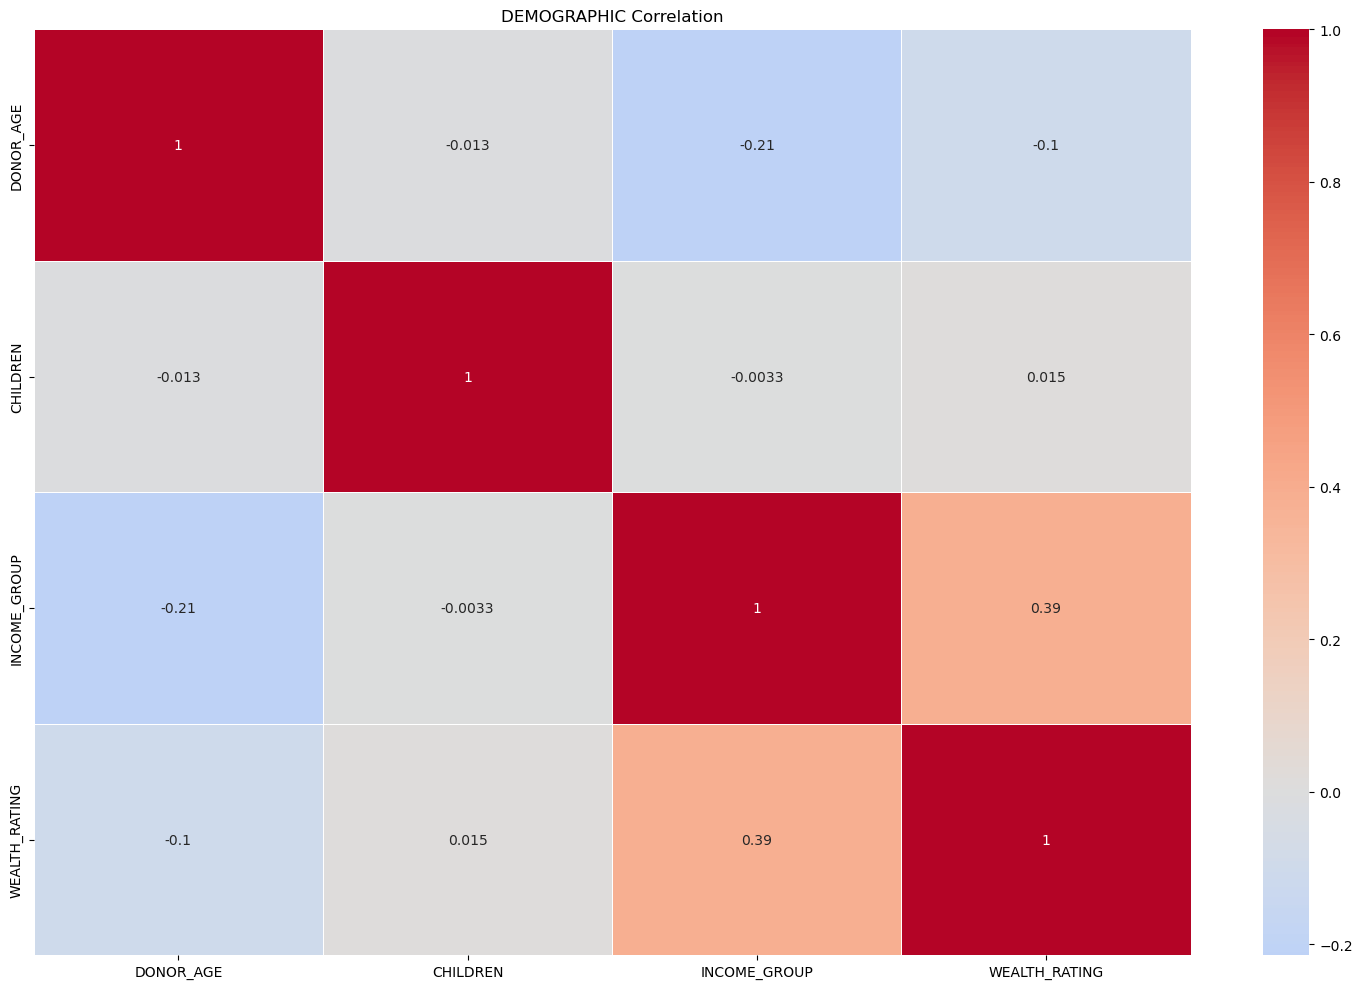

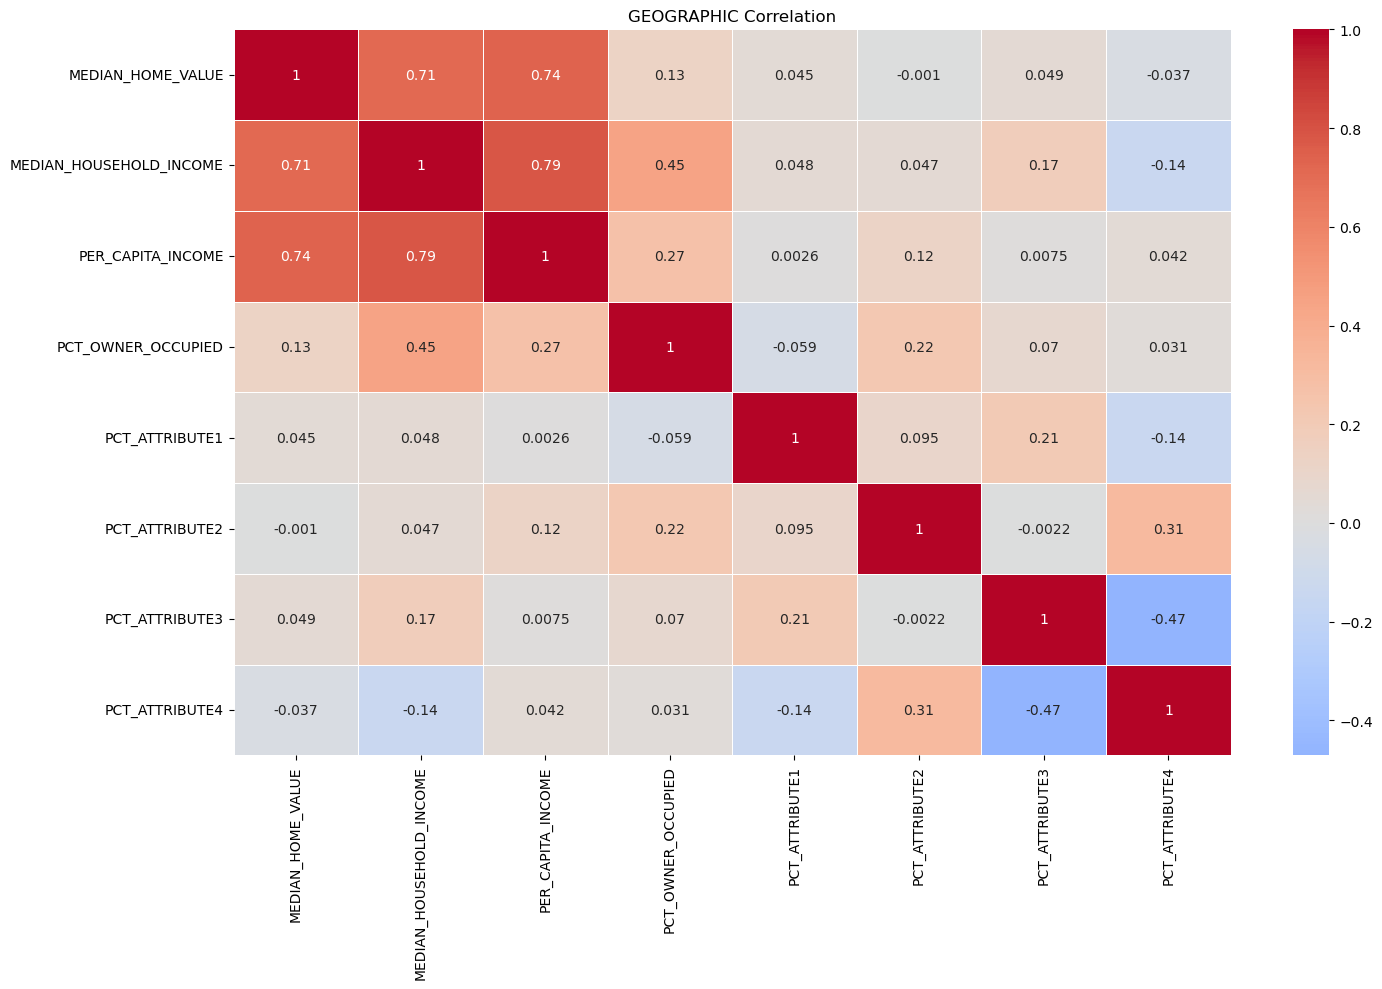

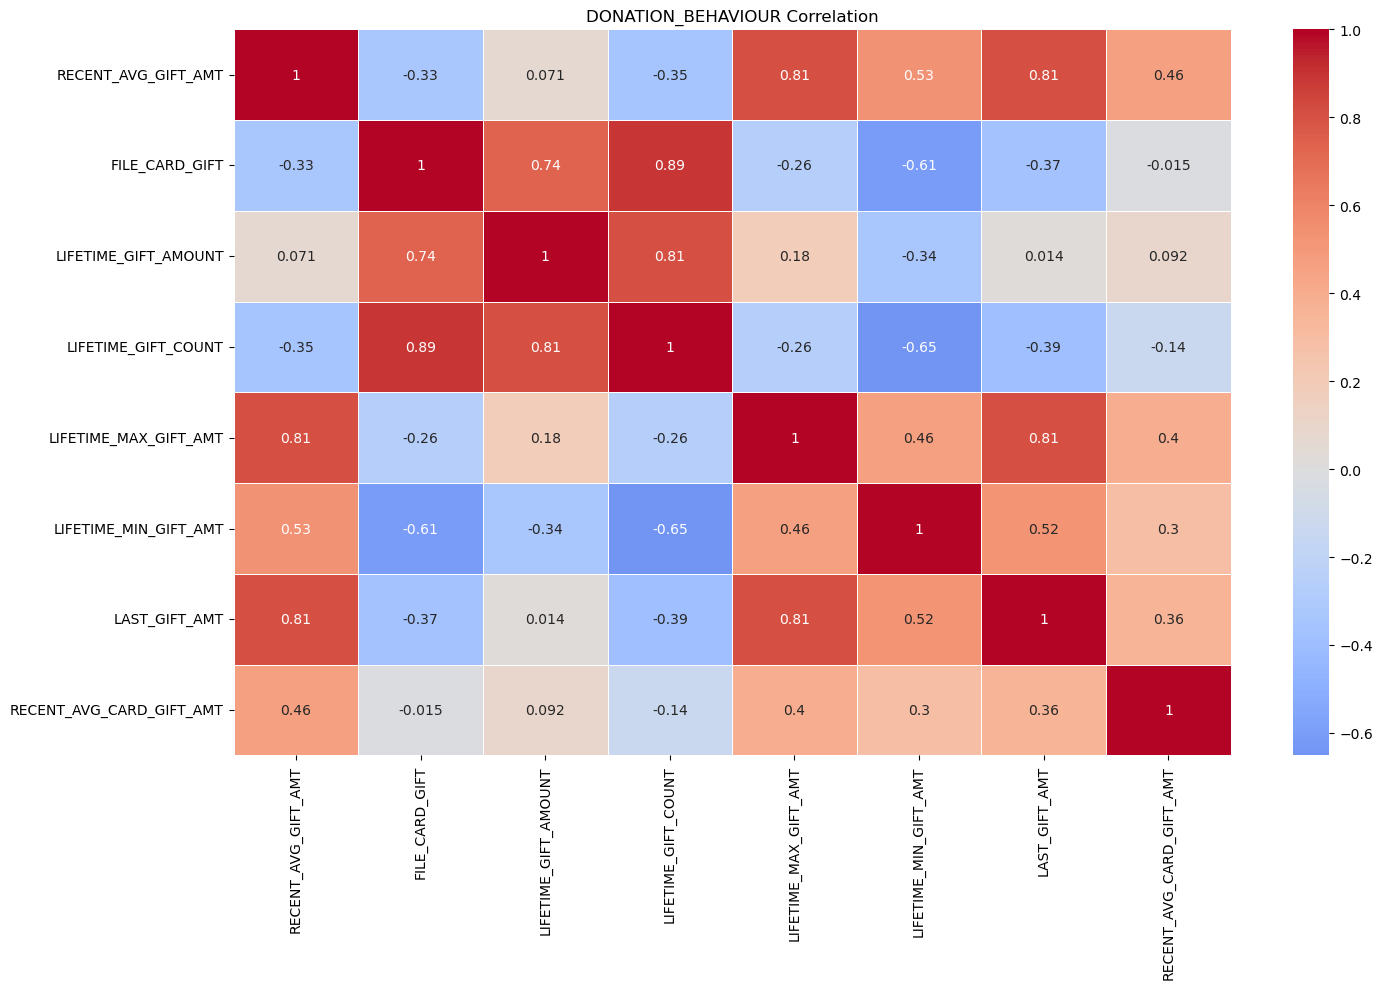

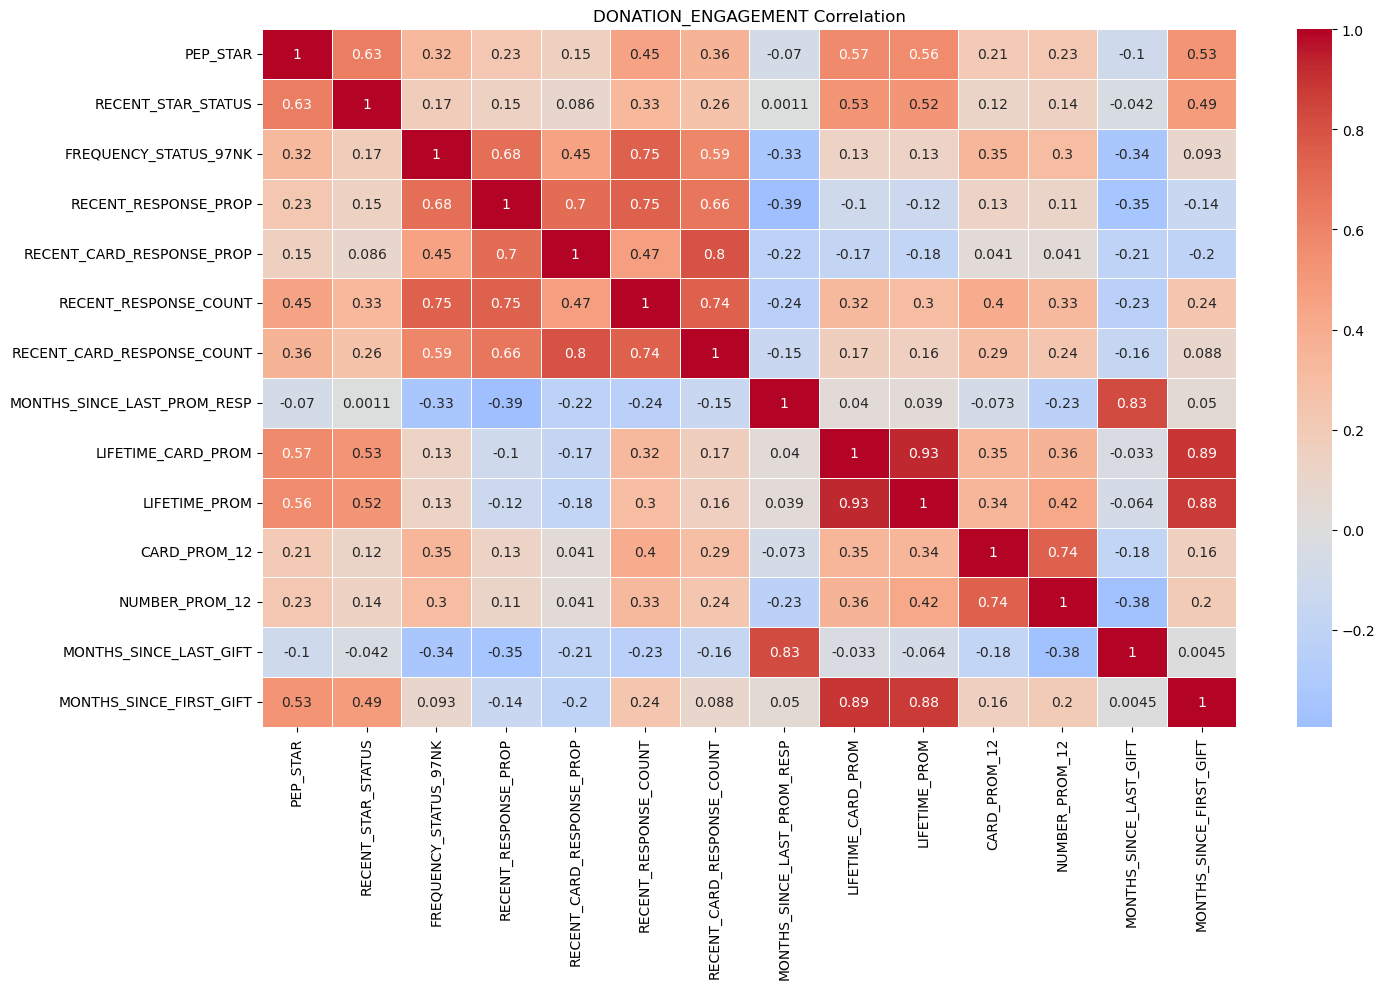

In [28]:
families = {
    "DEMOGRAPHIC": DEMOGRAPHIC,
    "GEOGRAPHIC": GEOGRAPHIC,
    "DONATION_BEHAVIOUR": DONATION_BEHAVIOUR,
    "DONATION_ENGAGEMENT": DONATION_ENGAGEMENT
}

for name, cols in families.items():
    plot_corr_num(df[cols], f"{name} Correlation")

# Demographic: this group doesn't show any relevant correlation between its features
# Geographic: this group shows some relevant correlation between a few of its features with a score in [0.4,0.8]
# Donation_behaviour: this group shows some relevant correlation between a few of its features with a score in [0.4,0.8]
# Donation_engagement: this group shows some relevant correlation between a few of its features with a score in [0.4,0.8]

---
# 4. Data Preparation <a name="data-preparation"></a>


---
## 4.1. Preprocessing Data  <a name="preprocessing-data"></a>


In [29]:
df_copy = df.copy()

In [30]:
df_copy.columns = df_copy.columns.str.lower()
# The feature 'CONTROL_NUMBER' was set as index
if 'control_number' in df_copy.columns:
    df_copy.set_index('control_number', inplace=True)

---
## 4.2. Data Cleaning <a name="data-cleaning"></a>



In [31]:
# Months_since_last_prom_resp
#df_copy['months_since_last_prom_resp'].describe()
# This feature must be > 0
df_copy.loc[df_copy['months_since_last_prom_resp'] < 0, 'months_since_last_prom_resp'] = np.nan
# Null values were assumed as donors that have never responded - a flag was created to identify which donors responded (0) and those who didn't (1)
df_copy['no_response_flag'] = df_copy['months_since_last_prom_resp'].isna().astype(int)
# Null values were filled with the maximum value
max_months = df_copy['months_since_last_prom_resp'].max()
df_copy['months_since_last_prom_resp'] = df_copy['months_since_last_prom_resp'].fillna(max_months)
# Assure feature consistency
df_copy['months_since_last_prom_resp'] = df_copy['months_since_last_prom_resp'].round(0).astype(int)

C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\2809170992.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='no_response_flag', data=df_copy, palette='pink', ax=axes[2])
C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\2809170992.py:12: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  axes[2].set_xticklabels(['Has answered (0)', 'Never answered (1)'])


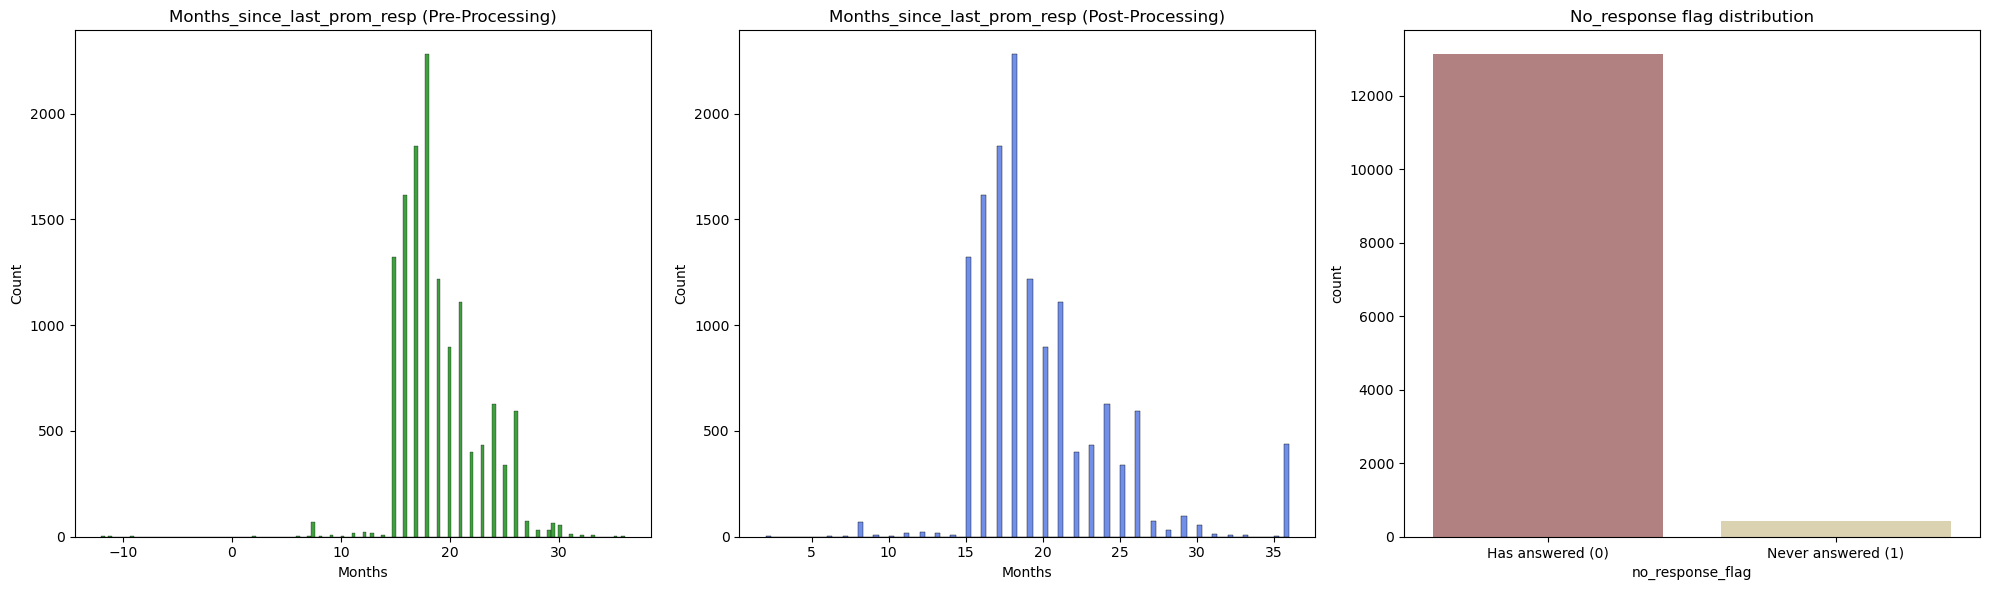

In [32]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
sns.histplot(df['MONTHS_SINCE_LAST_PROM_RESP'], color='green', ax=axes[0])
axes[0].set_title('Months_since_last_prom_resp (Pre-Processing)')
axes[0].set_xlabel('Months')

sns.histplot(df_copy['months_since_last_prom_resp'], color='royalblue', ax=axes[1])
axes[1].set_title('Months_since_last_prom_resp (Post-Processing)')
axes[1].set_xlabel('Months')

sns.countplot(x='no_response_flag', data=df_copy, palette='pink', ax=axes[2])
axes[2].set_title('No_response flag distribution')
axes[2].set_xticklabels(['Has answered (0)', 'Never answered (1)'])
plt.tight_layout()
plt.show()

In [33]:
# Recent_response_count, Recent_card_response_count
# Recent_reponse_prop, Recent_card_response_prop
# This features must be > 0
# The features that are proportions also can't have values > 1
recent_count = ['recent_response_count','recent_card_response_count']
recent_prop = ['recent_response_prop','recent_card_response_prop']
#df_copy[recent_count + recent_prop].describe()
# Where no_response_flag = 1 we filled the null values with 0 - if our individual has not responded it can't have a response count/prop
for col in recent_count + recent_prop:
    df_copy.loc[df_copy[col] < 0, col] = np.nan
    df_copy.loc[df_copy['no_response_flag'] == 1, col] = 0
# Where no_response_flag = 0 we filled the null values with the median of the respective columns
for col in recent_count + recent_prop:
    med_actives = df_copy.loc[df_copy['no_response_flag'] == 0, col].median()
    df_copy[col] = df_copy[col].fillna(med_actives)
# Here we ensure that recent_card_response_count is never > than recent_response_count
# When that happens we substitute the recent_respose_count for the respective recent_card_response_count
df_copy['recent_response_count'] = np.where(df_copy['recent_response_count'] < df_copy['recent_card_response_count'],
                                            df_copy['recent_card_response_count'],
                                            df_copy['recent_response_count'])
# Here we ensure that the features that are proportions are never superior than 1
df_copy[recent_prop] = df_copy[recent_prop].clip(0, 1)
# Assure feature consistency
df_copy[recent_count] = df_copy[recent_count].round(0).astype(int)

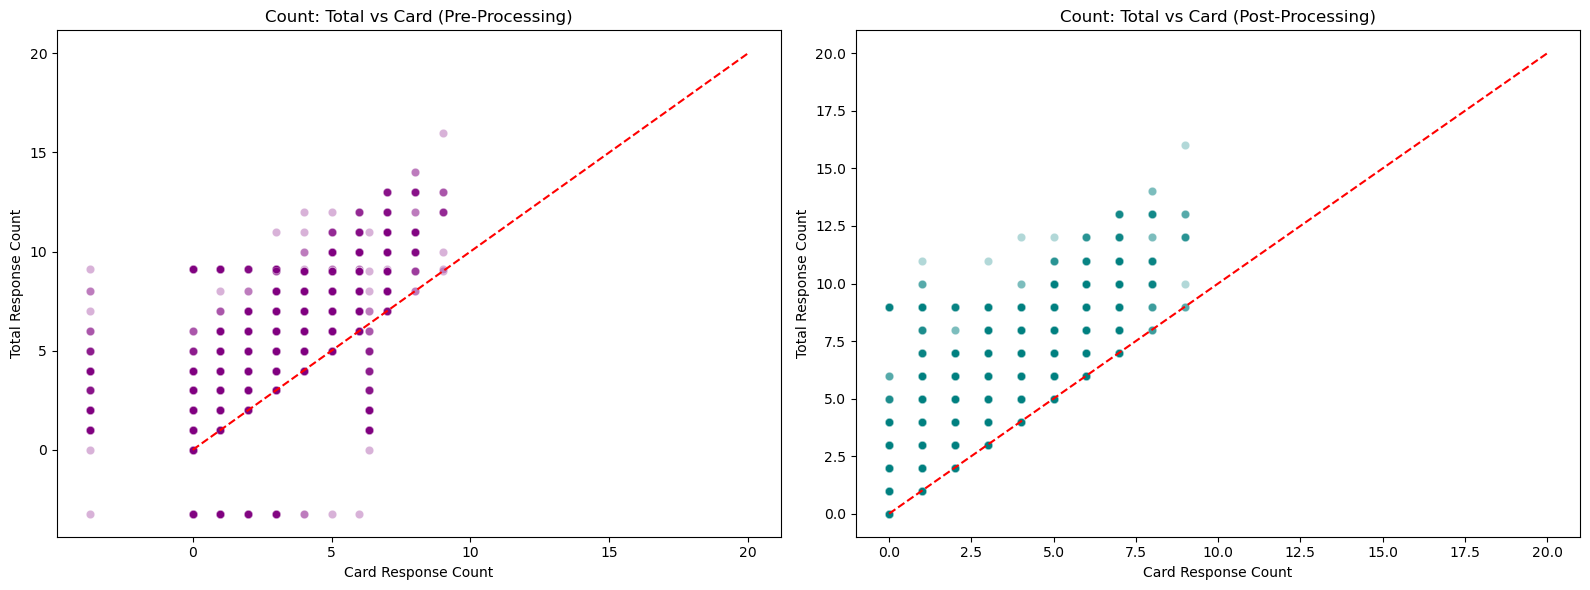

In [34]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x='RECENT_CARD_RESPONSE_COUNT', y='RECENT_RESPONSE_COUNT', data=df, alpha=0.3, color='purple')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')
plt.title('Count: Total vs Card (Pre-Processing)')
plt.xlabel('Card Response Count')
plt.ylabel('Total Response Count')
plt.subplot(1, 2, 2)
sns.scatterplot(x='recent_card_response_count', y='recent_response_count', data=df_copy, alpha=0.3, color='teal')
plt.plot([0, 20], [0, 20], color='red', linestyle='--')
plt.title('Count: Total vs Card (Post-Processing)')
plt.xlabel('Card Response Count')
plt.ylabel('Total Response Count')
plt.tight_layout()
plt.show()
# On these plots we verify if the rule (recent_card_response_count <= recent_response_count) applied to our data and if it had any affect on the distribution of the data
# The expected outcome is the points being distributed on top on the line or above it

In [35]:
# Lifetime_prom
#df_copy['lifetime_prom'].describe()
# This feature must be > 0
df_copy.loc[df_copy['lifetime_prom'] < 0, 'lifetime_prom'] = np.nan
# This feature is count-based; Null values were filled with the median
df_copy['lifetime_prom'] = df_copy['lifetime_prom'].fillna(df_copy['lifetime_prom'].median())
# Assure feature consistency
df_copy['lifetime_prom'] = df_copy['lifetime_prom'].abs().round(0).astype(int)

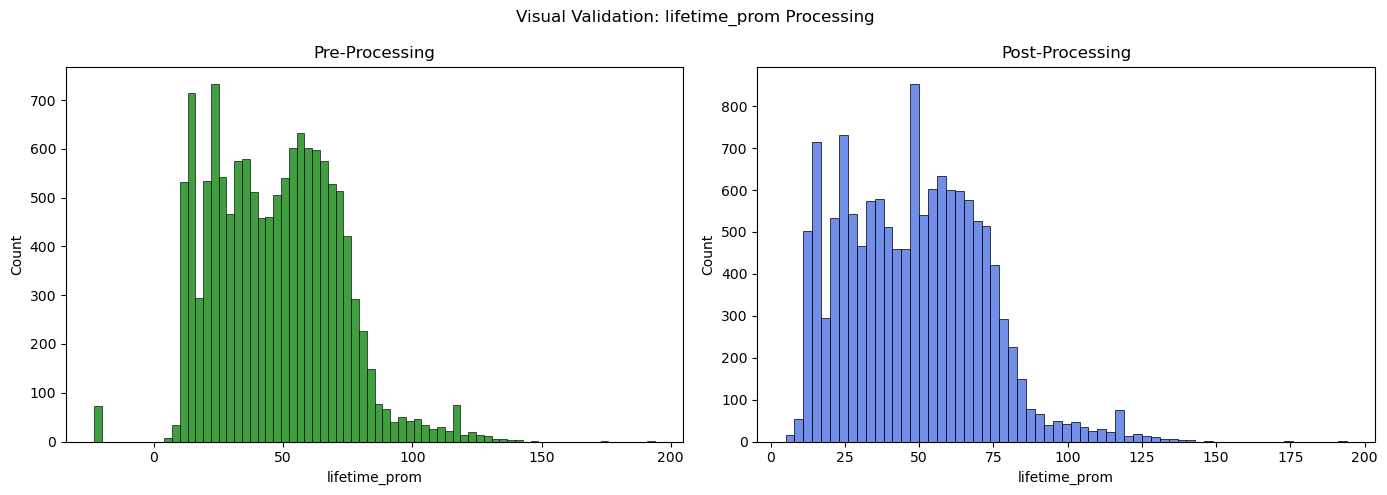

In [36]:
hist_plot('lifetime_prom')

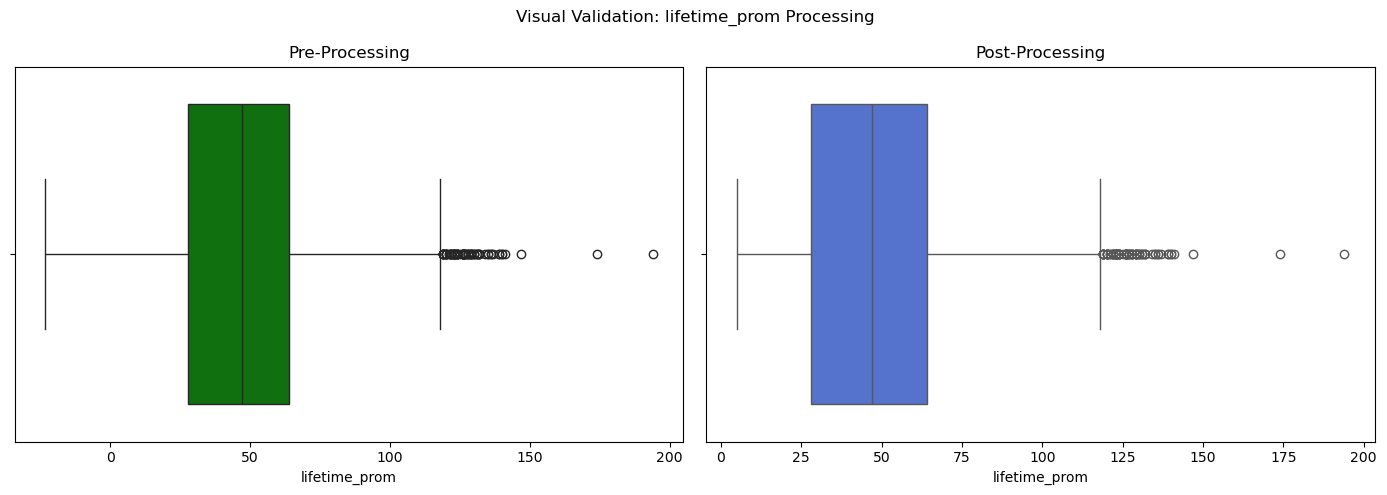

In [37]:
box_plot('lifetime_prom')

In [38]:
# Lifetime_card_prom
#df_copy['lifetime_card_prom'].describe()
# This feature must be > 0
df_copy.loc[df_copy['lifetime_card_prom'] < 0, 'lifetime_card_prom'] = np.nan
# Calculate the card ratio that consists in the average proportion of card-based promotions relative to all promotions
# We filter for donors with lifetime_prom > 0 to prevent division by zero
card_ratio = (df_copy['lifetime_card_prom'] / df_copy.loc[df_copy['lifetime_prom'] >0 ,'lifetime_prom']).mean()
# Null values were filled by multiplying the total promotions by the card ratio
# This ensures that the value is logically scaled to each individuals history
df_copy['lifetime_card_prom'] = df_copy['lifetime_card_prom'].fillna(df_copy['lifetime_prom'] * card_ratio)
# Here we ensure that lifetime_card_prom is never > than lifetime_prom
# When that happens we substitute the lifetime_prom for the lifetime_card_prom
df_copy['lifetime_card_prom'] = np.where(df_copy['lifetime_card_prom'] > df_copy['lifetime_prom'], df_copy['lifetime_prom'], df_copy['lifetime_card_prom'])
# Assure feature consistency
df_copy['lifetime_card_prom'] = df_copy['lifetime_card_prom'].abs().round(0).astype(int)

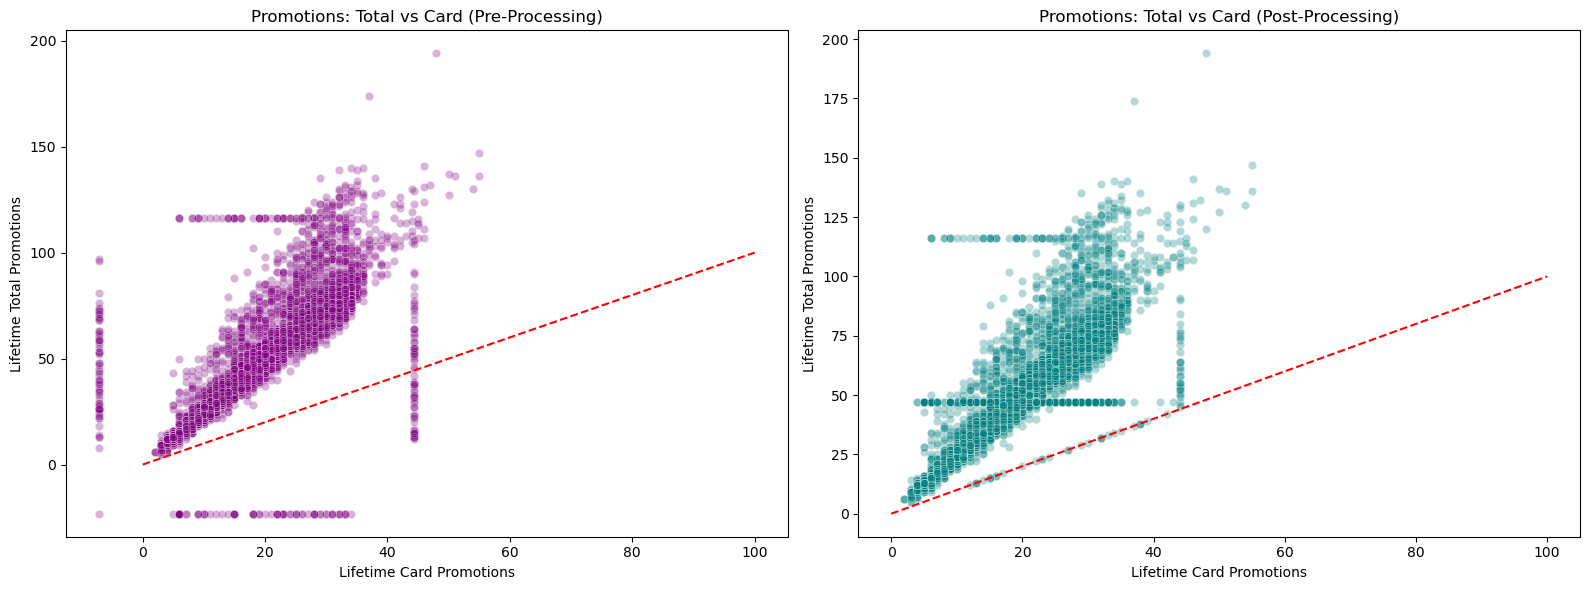

In [39]:
plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
sns.scatterplot(x='LIFETIME_CARD_PROM', y='LIFETIME_PROM', data=df, alpha=0.3, color='purple')
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.title('Promotions: Total vs Card (Pre-Processing)')
plt.xlabel('Lifetime Card Promotions')
plt.ylabel('Lifetime Total Promotions')
plt.subplot(1, 2, 2)
sns.scatterplot(x='lifetime_card_prom', y='lifetime_prom', data=df_copy, alpha=0.3, color='teal')
plt.plot([0, 100], [0, 100], color='red', linestyle='--')
plt.title('Promotions: Total vs Card (Post-Processing)')
plt.xlabel('Lifetime Card Promotions')
plt.ylabel('Lifetime Total Promotions')
plt.tight_layout()
plt.show()
# On these plots we verify if the rule (lifetime_card_prom <= lifetime_prom) applied to our data and if it had any affect on the distribution of the data
# The expected outcome is the points being distributed on top on the line or above it

In [40]:
# Number_prom_12, Card_prom_12
# These features must be > 0
cols = ['number_prom_12', 'card_prom_12']
df_copy[cols] = df_copy[cols].mask(df_copy[cols] < 0)
# What we do is, if card_prom_12 is not null we input with the value from that column, else with 0
df_copy['number_prom_12'] = df_copy['number_prom_12'].fillna(df_copy['card_prom_12']).fillna(0)
# Here we ensure that card_prom_12 is never > than number_prom_12
# When that happens we substitute the number_prom_12 for the card_prom_12
df_copy.loc[df_copy['number_prom_12']<df_copy['card_prom_12'], 'card_prom_12']= df_copy.loc[df_copy['number_prom_12']<df_copy['card_prom_12'], 'number_prom_12']
# Here we assume that if card_prom_12 is null - most likely it was supposed to be 0
df_copy['card_prom_12'] = df_copy['card_prom_12'].fillna(0)
# Assure feature consistency
df_copy[cols] = df_copy[cols].abs().round().astype(int)
# cols = ['card_prom_12', 'number_prom_12']
# for col in cols:
#   print(df_copy[col].describe())

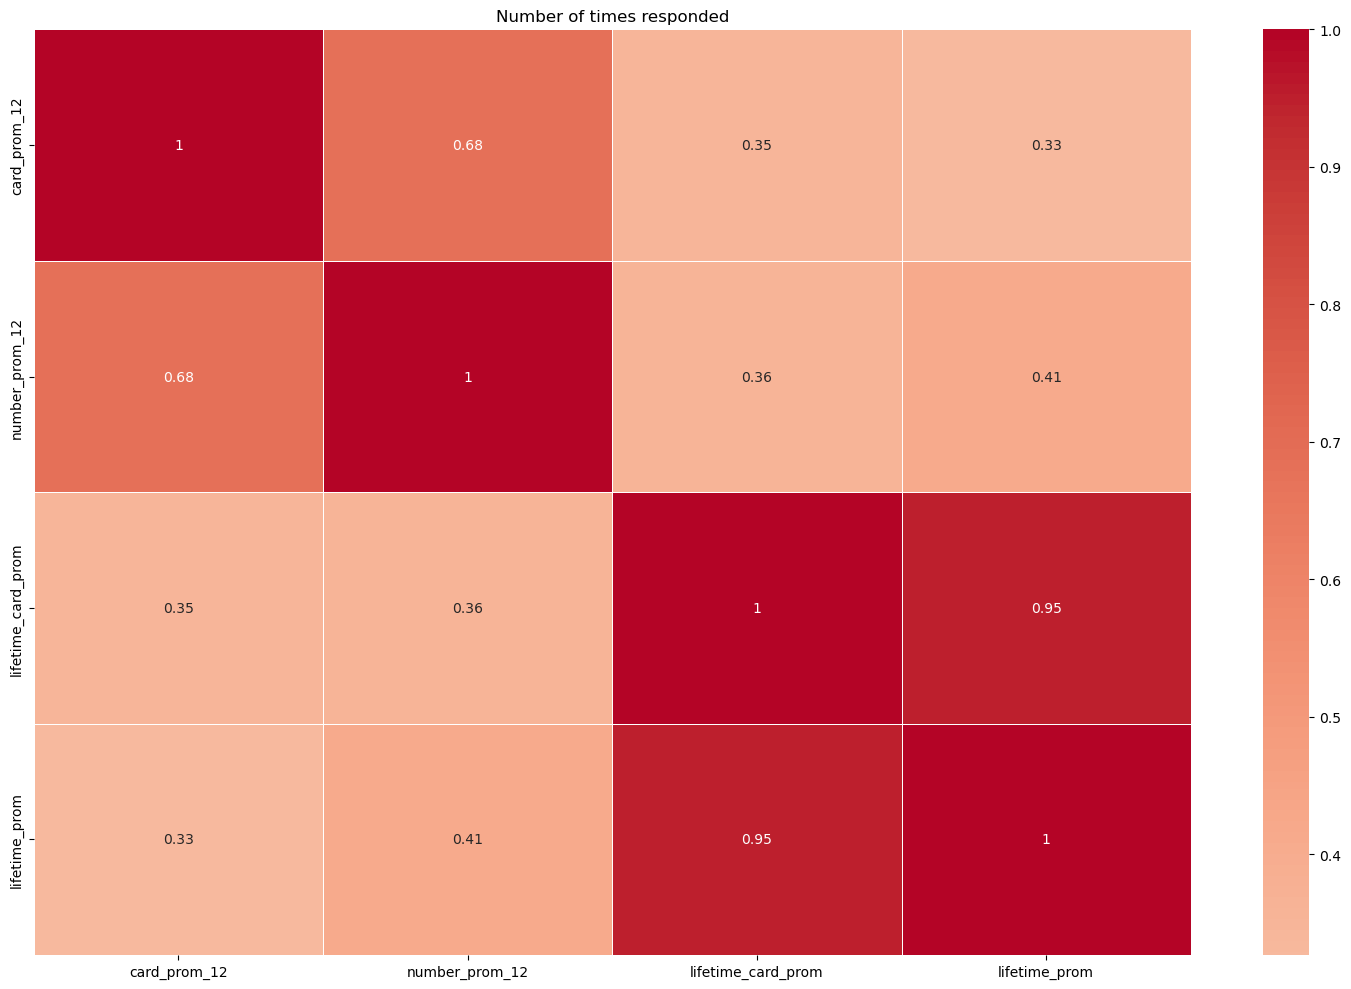

In [41]:
subset = ['card_prom_12', 'number_prom_12','lifetime_card_prom', 'lifetime_prom']
plot_corr_num(df_copy[subset], "Number of times responded")

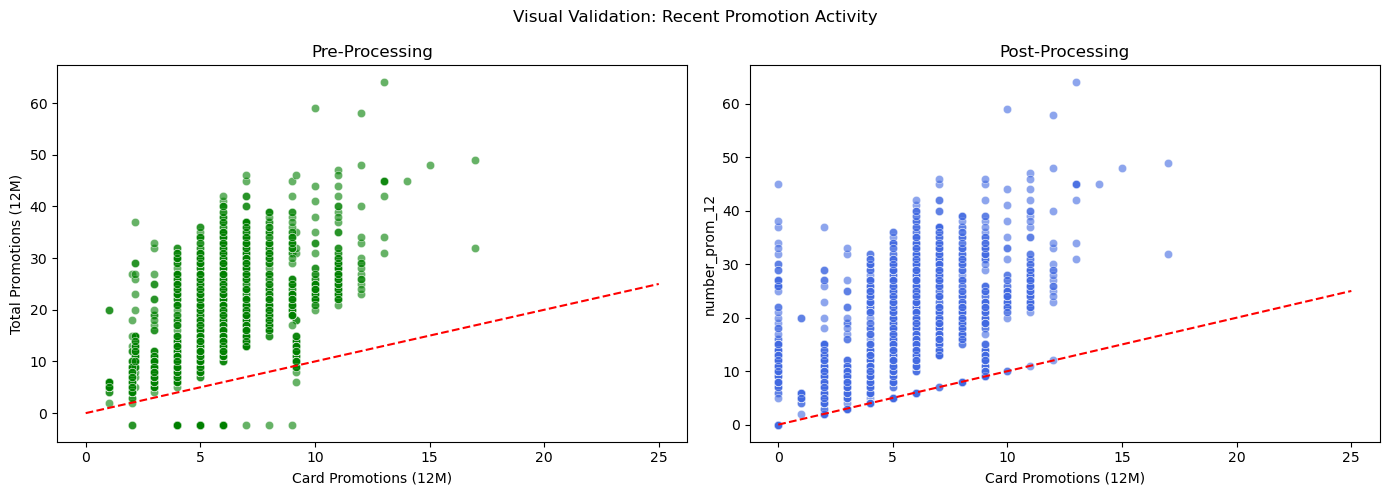

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(x=df['CARD_PROM_12'], y=df['NUMBER_PROM_12'], ax=axes[0], color='green', alpha=0.6)
axes[0].plot([0, 25], [0, 25], linestyle='--', color='red')
axes[0].set_title("Pre-Processing")
axes[0].set_xlabel("Card Promotions (12M)")
axes[0].set_ylabel("Total Promotions (12M)")
sns.scatterplot(x=df_copy['card_prom_12'], y=df_copy['number_prom_12'], ax=axes[1], color='royalblue', alpha=0.6)
axes[1].plot([0, 25], [0, 25], linestyle='--', color='red')
axes[1].set_title("Post-Processing")
axes[1].set_xlabel("Card Promotions (12M)")
plt.suptitle("Visual Validation: Recent Promotion Activity")
plt.tight_layout()
plt.show()
# On these plots we verify if the rule (card_prom_12 <= number_prom_12) applied to our data and if it had any affect on the distribution of the data
# The expected outcome is the points being distributed on top on the line or above it

In [43]:
# Donor_gender
#df_copy['donor_gender'].describe()
# We identified a third category 'U' that we assumed to be 'Unknown'
# Null values were filled with that category
df_copy['donor_gender'] = df_copy['donor_gender'].fillna('U')

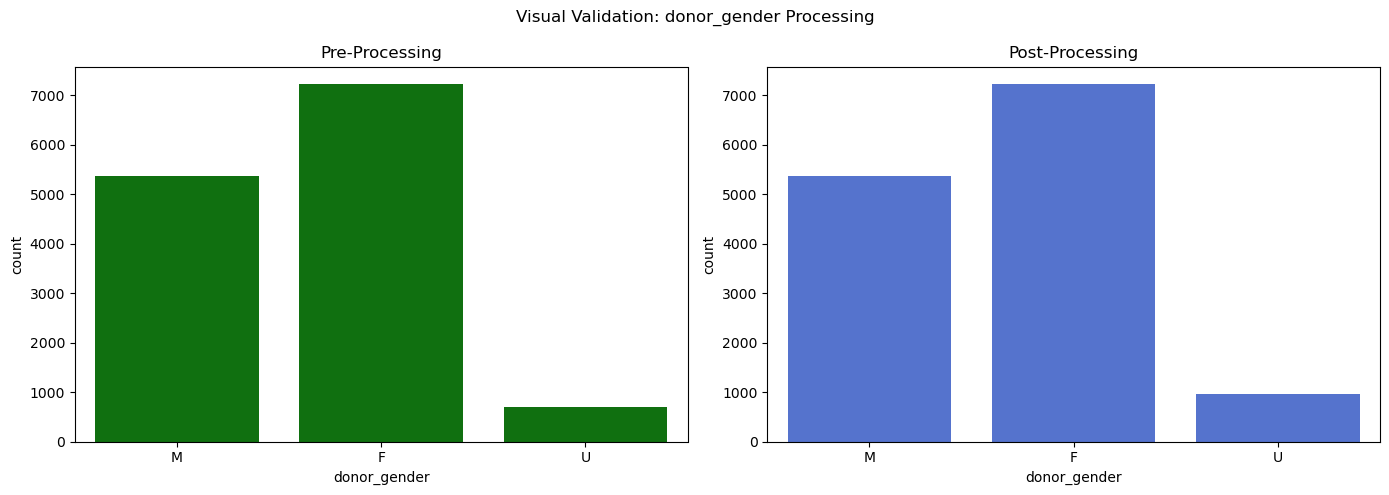

In [44]:
count_plot('donor_gender')

In [45]:
# Children
#df_copy['children'].describe()
# This feature must be > 0
df_copy.loc[df_copy['children'] < 0, 'children'] = np.nan
# Null values were filled with the median preserving data integrity
df_copy['children'] = df_copy['children'].fillna(df_copy['children'].median())
# Assure feature consistency
df_copy['children'] = df_copy['children'].round(0).astype(int)

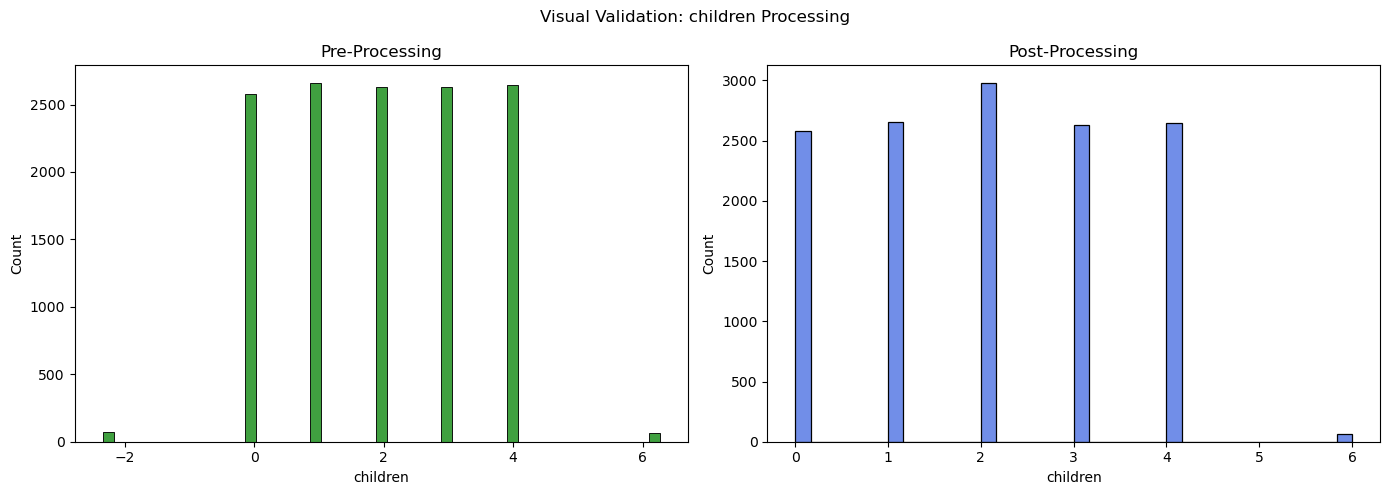

In [46]:
hist_plot('children')

In [47]:
# Home_owner
#df_copy['home_owner'].describe()
# This feature has a third category 'U' - 'Unknown'
# Null values were filled with that category
df_copy['home_owner'] = df_copy['home_owner'].fillna('U')

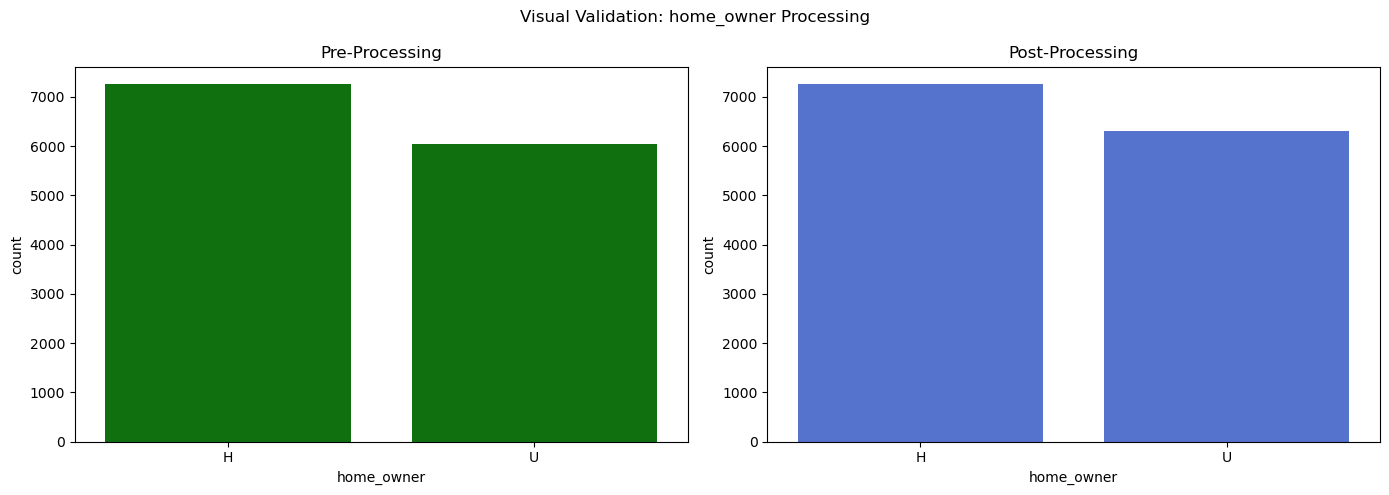

In [48]:
count_plot('home_owner')

In [49]:
# Pct_owner_occupied
#df_copy['pct_owner_occupied'].describe()
# This feature must be < 100
df_copy.loc[df_copy['pct_owner_occupied'] > 100, 'pct_owner_occupied'] = np.nan
# Null values were filled with the median preserving data integrity
df_copy['pct_owner_occupied'] = df_copy['pct_owner_occupied'].fillna(df_copy['pct_owner_occupied'].median())
# Assure feature consistency
df_copy['pct_owner_occupied'] = df_copy['pct_owner_occupied'].round(2)

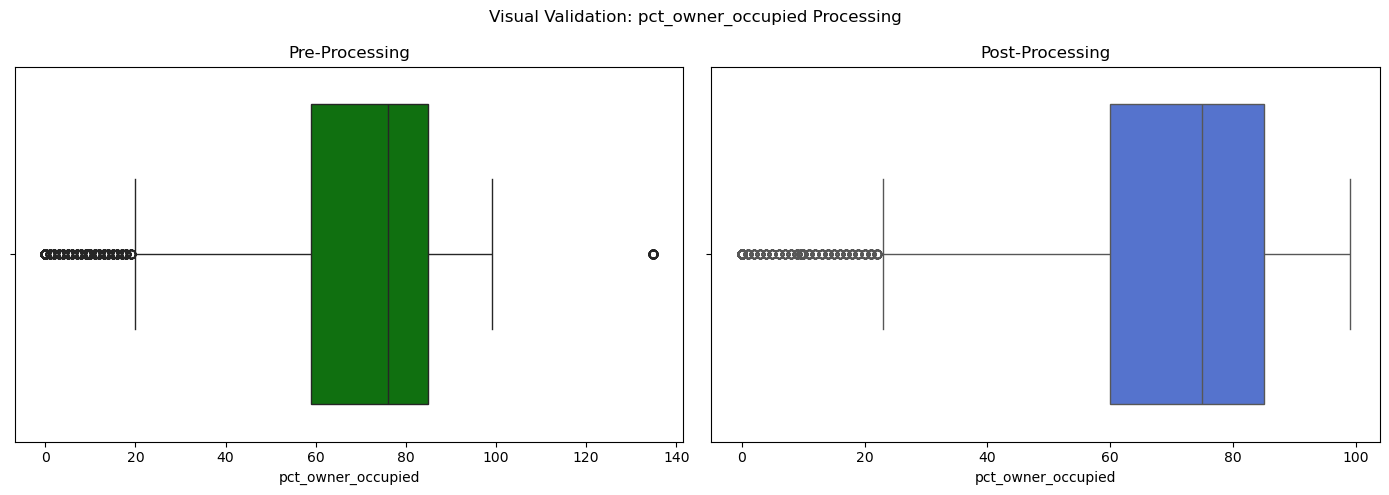

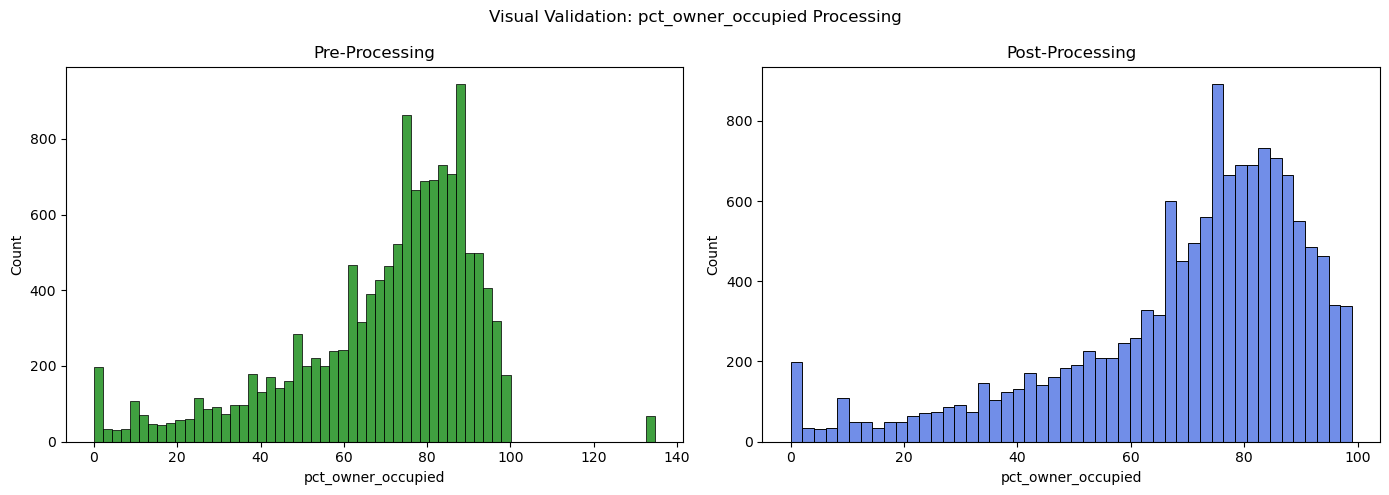

In [50]:
box_plot('pct_owner_occupied')
hist_plot('pct_owner_occupied')

In [51]:
# Pct_attribute 1, 2, 3 and 4
# These features must be > 0
pct_cols = ['pct_attribute1', 'pct_attribute2', 'pct_attribute3', 'pct_attribute4']
#df_copy[pct_cols].describe()
for col in pct_cols:
    df_copy.loc[df_copy[col] < 0, col] = np.nan
    # Null values were filled with the median preserving data integrity
    df_copy[col] = df_copy[col].fillna(df_copy[col].median())
# Assure feature consistency
df_copy[pct_cols] = df_copy[pct_cols].round(2)

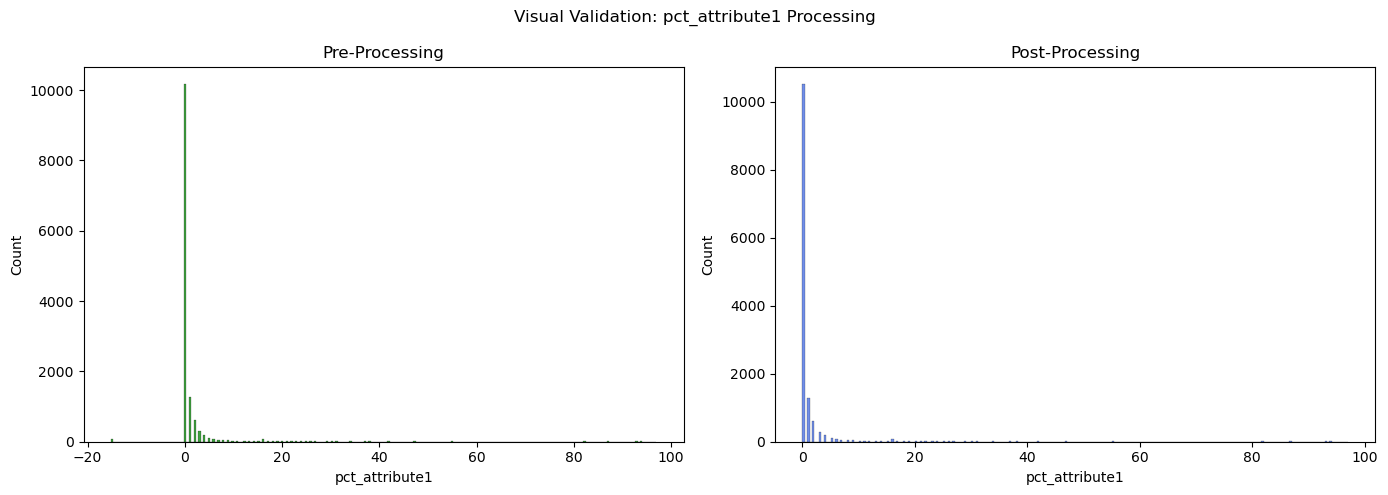

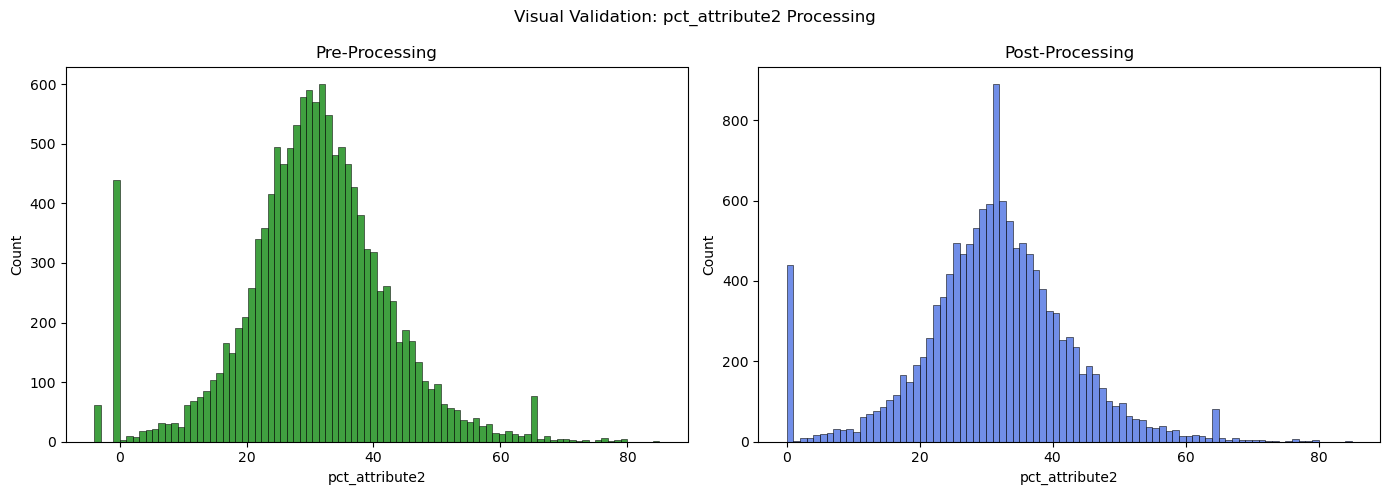

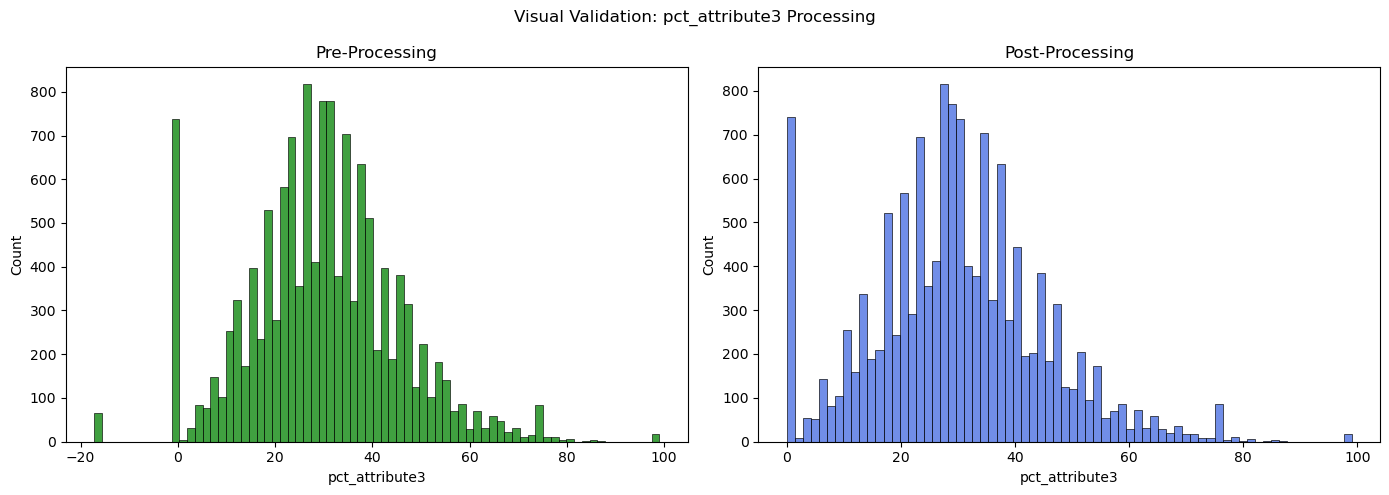

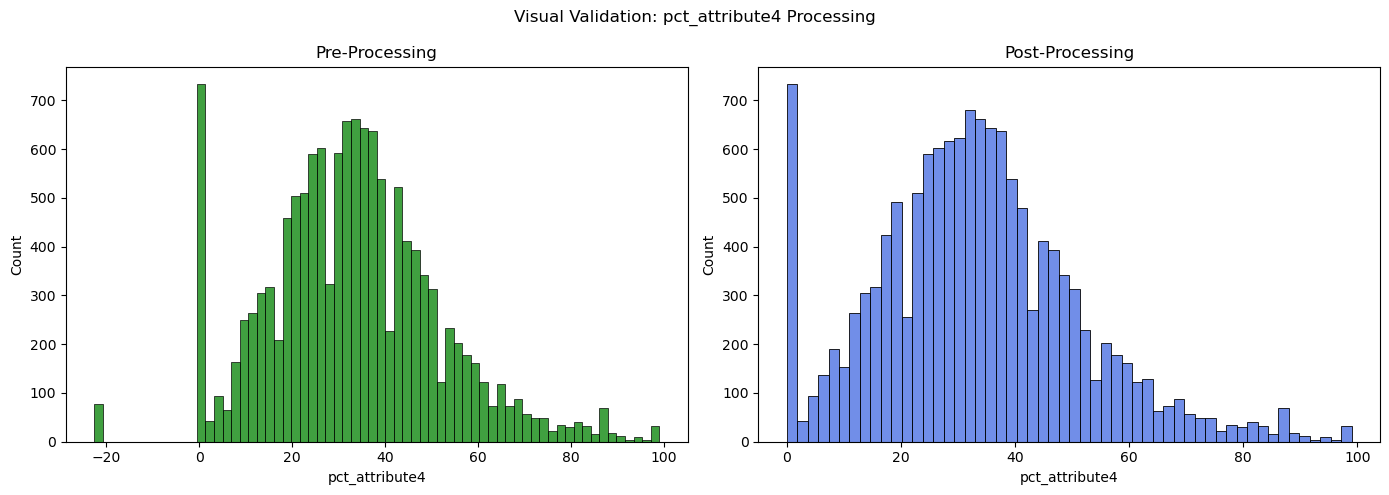

In [52]:
for col in pct_cols:
  hist_plot(col)

In [53]:
# Urbanicity
# Correct inconsistencies by removing whitespaces and converting to string
df_copy['urbanicity'] = df_copy['urbanicity'].astype(str).str.strip()
# Replace '?' and possible string 'nan' with actual null values
df_copy['urbanicity'] = df_copy['urbanicity'].replace(['?','nan'], np.nan)
# Null values were filled with the mode
df_copy['urbanicity'] = df_copy['urbanicity'].fillna(df_copy['urbanicity'].mode()[0])

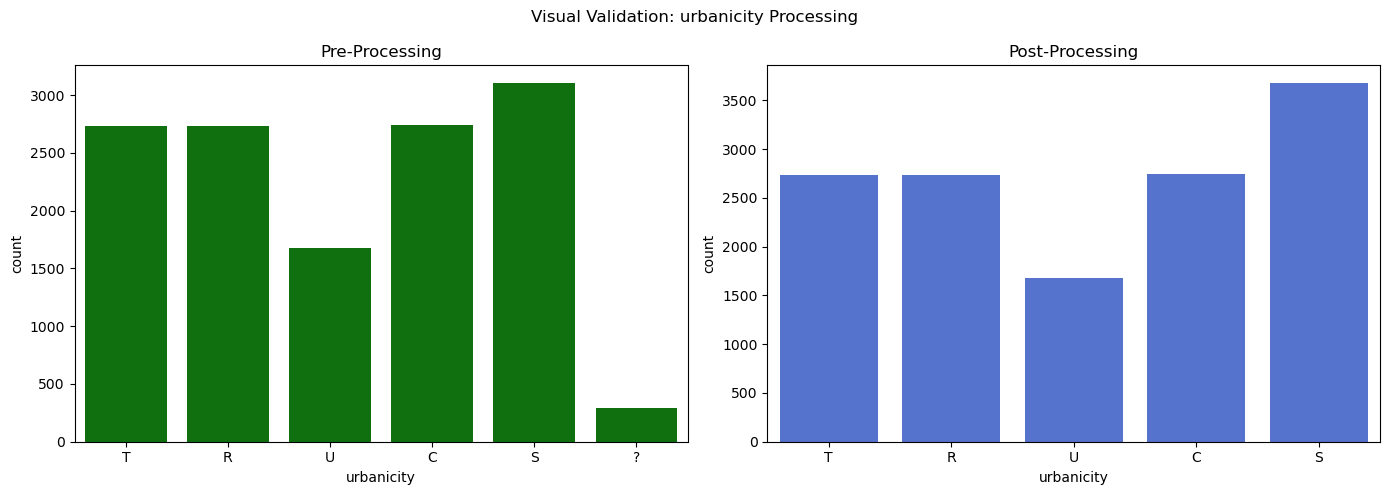

In [54]:
count_plot('urbanicity')

In [55]:
# SES
# Correct inconsistencies by removing whitespaces and converting to string
df_copy['ses'] = df_copy['ses'].astype(str).str.strip().replace('?', np.nan)
df_copy['ses'] = pd.to_numeric(df_copy['ses'], errors='coerce')
# Null values were filled based on the donors 'Urbanicity'
# We selected the mode of 'ses' within each 'urbanicity' group
df_copy['ses'] = df_copy['ses'].fillna(df_copy.groupby('urbanicity')['ses'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan))
# Assure feature consistency
df_copy['ses'] = df_copy['ses'].astype(int)

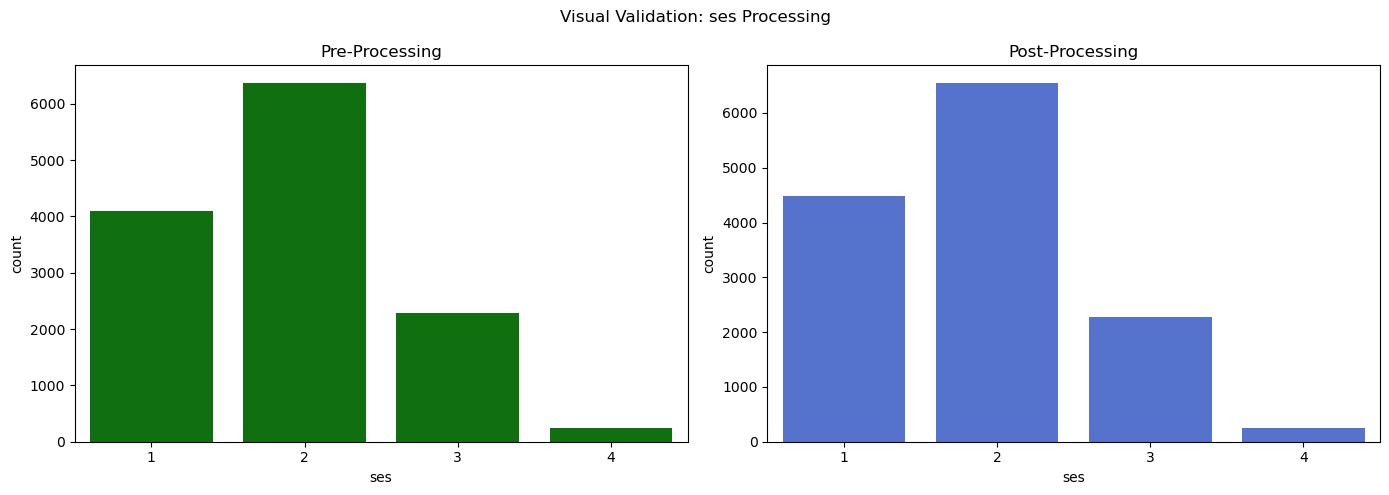

In [56]:
order_ses = [1,2,3,4]
count_plot('ses', order_name=order_ses)

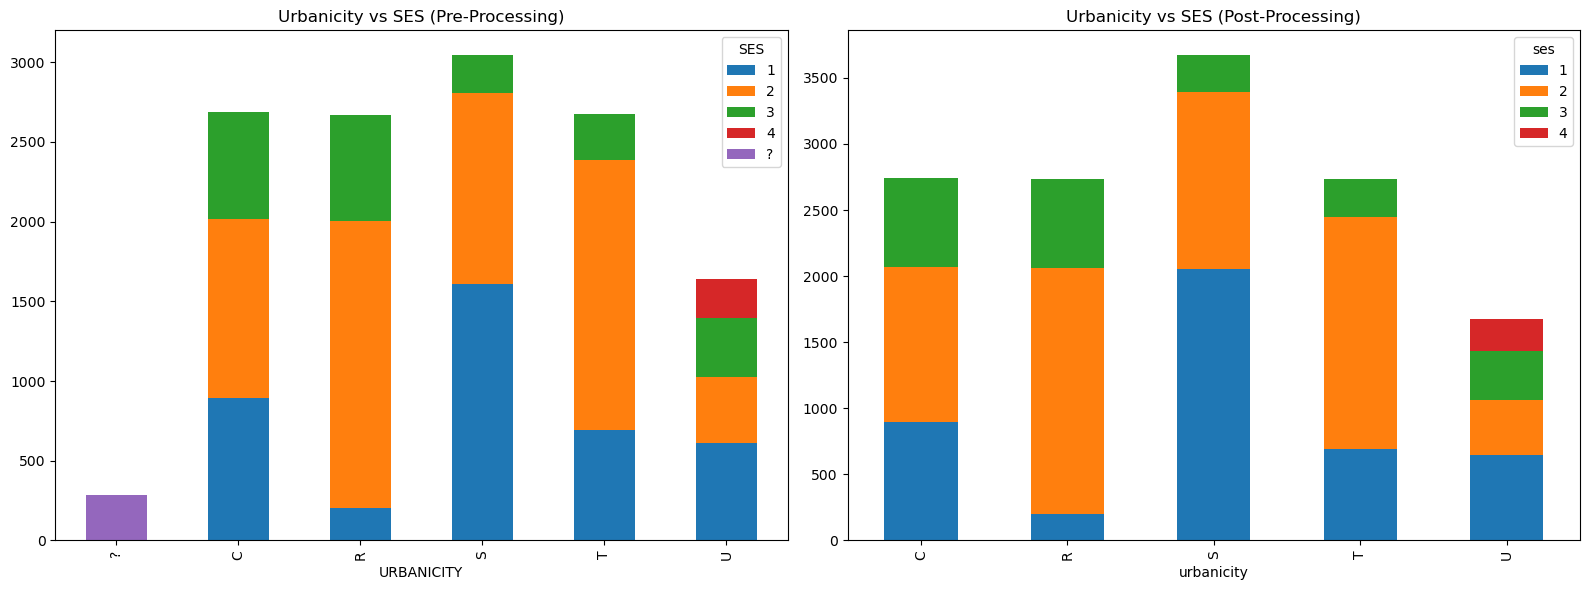

In [57]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
pd.crosstab(df['URBANICITY'], df['SES']).plot(kind='bar', stacked=True, ax=ax[0])
ax[0].set_title('Urbanicity vs SES (Pre-Processing)')
pd.crosstab(df_copy['urbanicity'], df_copy['ses']).plot(kind='bar', stacked=True, ax=ax[1])
ax[1].set_title('Urbanicity vs SES (Post-Processing)')
plt.tight_layout()
plt.show()
# Through this plots we can observe that the socioeconomic status ('ses') is linked to where a donor lives
# By filling the null values based on Urbanicity we respected the natural patterns observed

In [58]:
# Per_capita_income
# This feature must be > 0
#df_copy['per_capita_income'].describe()
df_copy.loc[df_copy['per_capita_income'] < 0, 'per_capita_income'] = np.nan
# Null values were filled with the median preserving data integrity
df_copy['per_capita_income'] = df_copy['per_capita_income'].fillna(df_copy['per_capita_income'].median())
# Assure feature consistency
df_copy['per_capita_income'] = df_copy['per_capita_income'].round(0).astype(int)

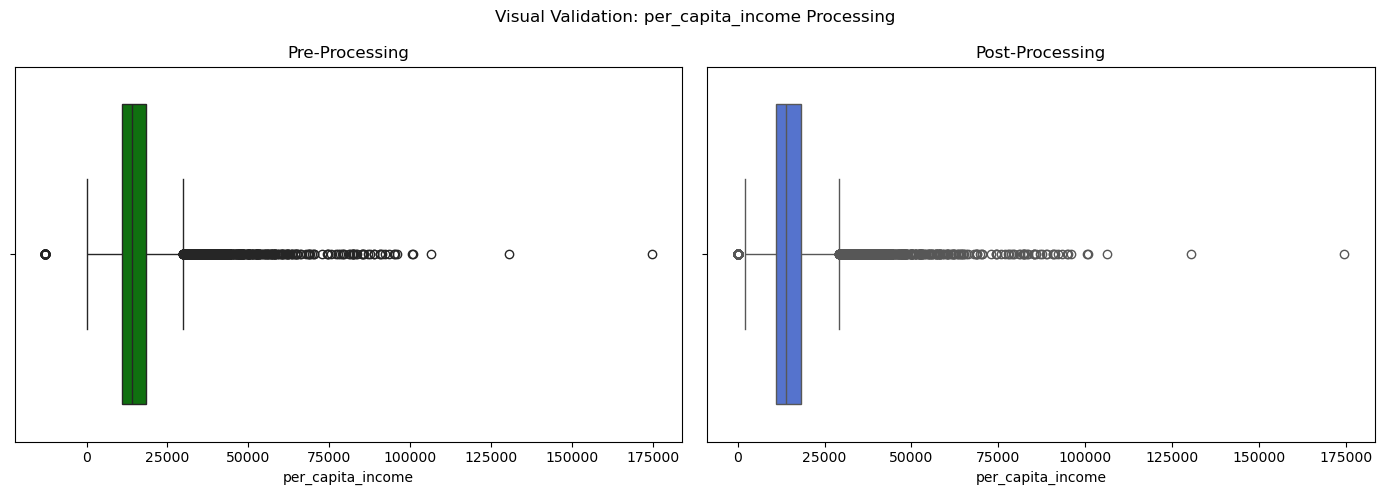

In [59]:
box_plot('per_capita_income')

In [60]:
# Income_group
# This feature must be between 1 and 7
# df_copy['income_group'].describe()
df_copy.loc[(df_copy['income_group'] <= 0) | (df_copy['income_group'] > 7), 'income_group'] = np.nan
# Null values were filled based on the donors 'Urbanicity'
# We selected the mode of 'income_group' within each 'urbanicity' group
df_copy['income_group'] = df_copy['income_group'].fillna(
    df_copy.groupby('urbanicity')['income_group'].transform(lambda x: x.mode()[0]))
# Assure feature consistency
df_copy['income_group'] = df_copy['income_group'].astype(int)

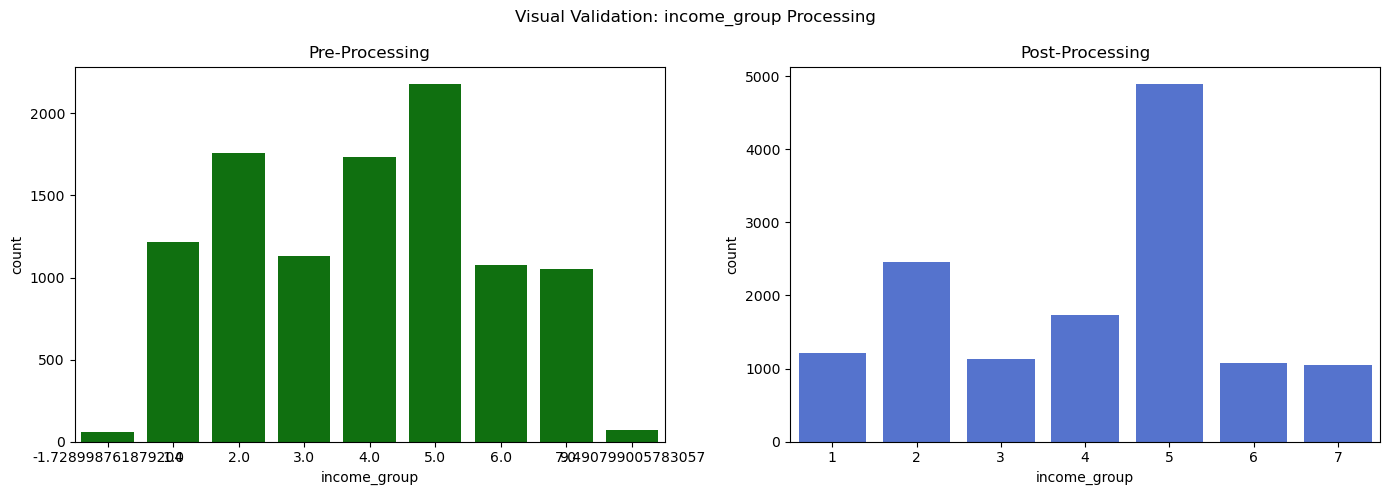

In [61]:
count_plot('income_group')

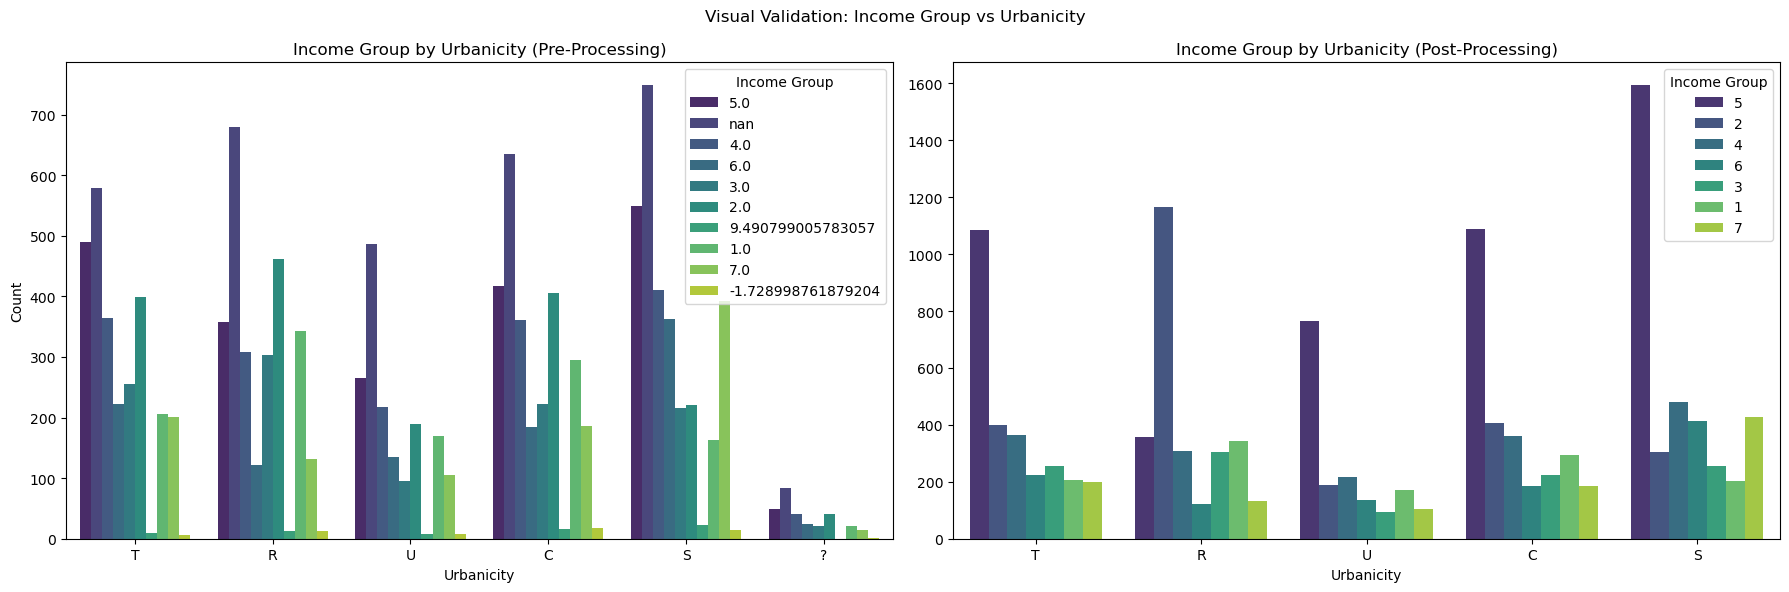

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
sns.countplot(x='URBANICITY', hue=df['INCOME_GROUP'].astype(str), data=df, palette='viridis', ax=axes[0])
axes[0].set_title('Income Group by Urbanicity (Pre-Processing)')
axes[0].set_xlabel('Urbanicity')
axes[0].set_ylabel('Count')
axes[0].legend(title='Income Group')
sns.countplot(x='urbanicity', hue=df_copy['income_group'].astype(str), data=df_copy, palette='viridis', ax=axes[1])
axes[1].set_title('Income Group by Urbanicity (Post-Processing)')
axes[1].set_xlabel('Urbanicity')
axes[1].set_ylabel('')
axes[1].legend(title='Income Group')
plt.suptitle('Visual Validation: Income Group vs Urbanicity')
plt.tight_layout()
plt.show()
# Through this plots we can see that Income_group follows geographic patterns
# The method choosen for processing this feature ensures that we preserve the distribution on each area

In [63]:
# Median_home_value
# df_copy['median_home_value'].describe()
# This feature must be > 0
df_copy.loc[df_copy['median_home_value'] < 0, 'median_home_value'] = np.nan
# Null values were filled based on the individuals 'Urbanicity'
# We selected the median of 'median_home_value' within each 'urbanicity' group
df_copy['median_home_value'] = df_copy['median_home_value'].fillna(df_copy.groupby('urbanicity')['median_home_value'].transform('median'))
# Assure feature consistency
df_copy['median_home_value'] = df_copy['median_home_value'].round(0).astype(int)

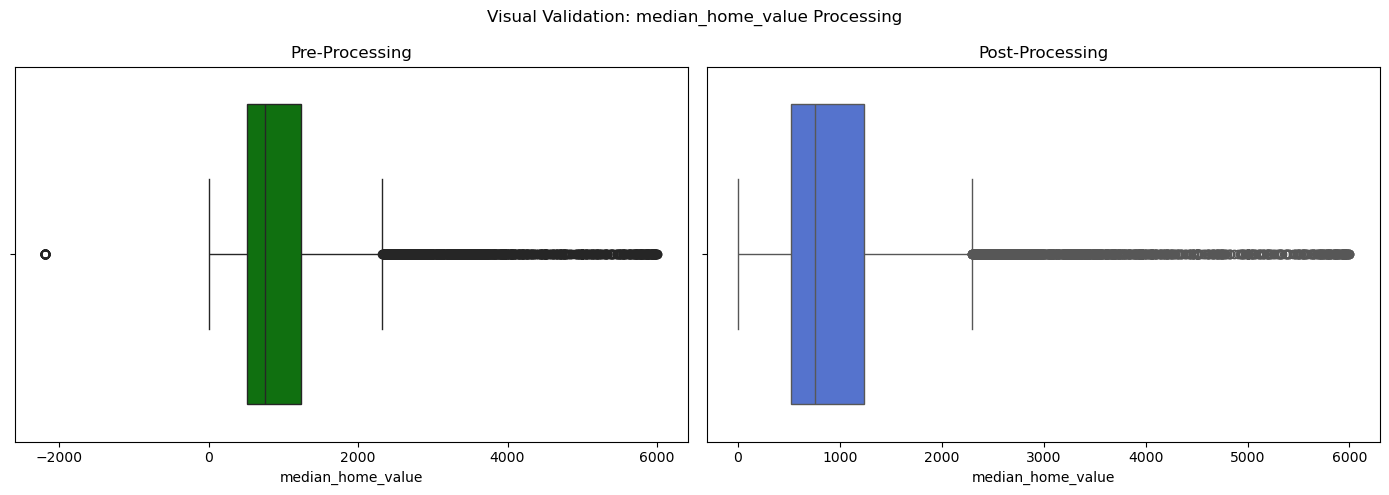

In [64]:
box_plot('median_home_value')

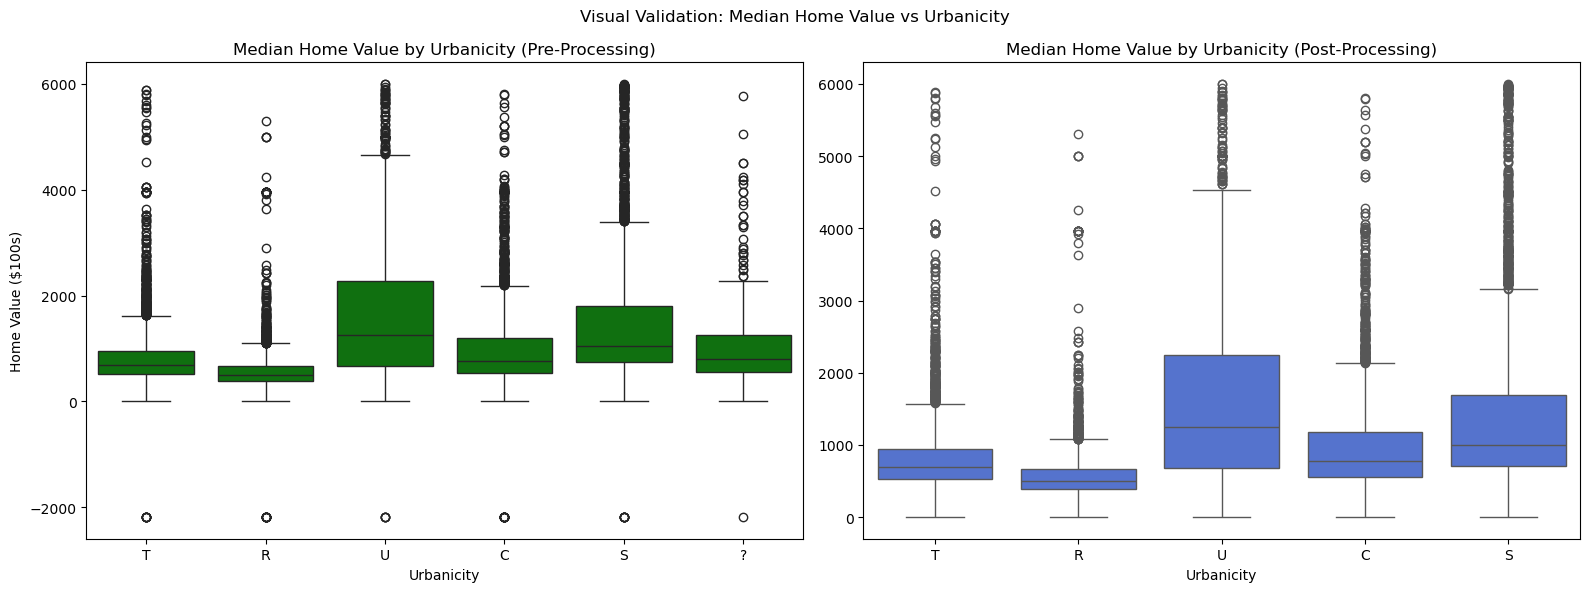

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(x='URBANICITY', y='MEDIAN_HOME_VALUE', data=df, ax=axes[0], color='green')
axes[0].set_title('Median Home Value by Urbanicity (Pre-Processing)')
axes[0].set_xlabel('Urbanicity')
axes[0].set_ylabel('Home Value ($100s)')
sns.boxplot(x='urbanicity', y='median_home_value', data=df_copy, ax=axes[1], color='royalblue')
axes[1].set_title('Median Home Value by Urbanicity (Post-Processing)')
axes[1].set_xlabel('Urbanicity')
axes[1].set_ylabel('')
plt.suptitle('Visual Validation: Median Home Value vs Urbanicity')
plt.tight_layout()
plt.show()
# Through this plots we can verify that the processing respected the natural distribution of the data

In [66]:
# Media_household_income
# df_copy['median_household_income'].describe()
# This feature must be > 0
df_copy.loc[df_copy['median_household_income'] < 0, 'median_household_income'] = np.nan
# Null values were filled based on the individuals 'ses'
# We selected the median of 'median_household_income' within each 'ses' group
df_copy['median_household_income'] = df_copy['median_household_income'].fillna(df_copy.groupby('ses')['median_household_income'].transform('median'))
# Assure feature consistency
df_copy['median_household_income'] = df_copy['median_household_income'].round(0).astype(int)

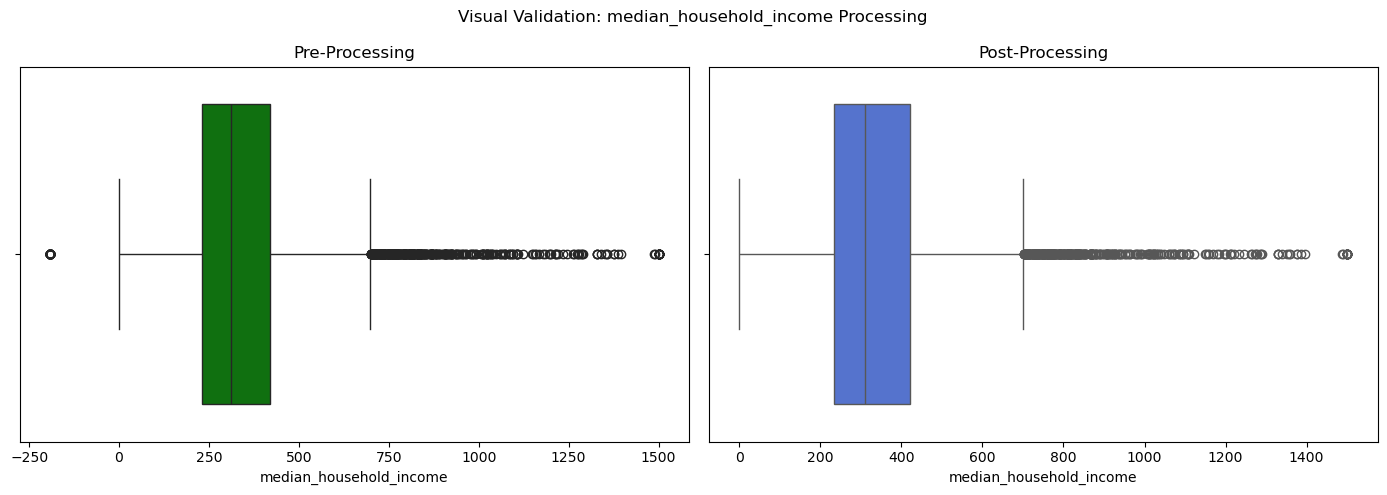

In [67]:
box_plot('median_household_income')

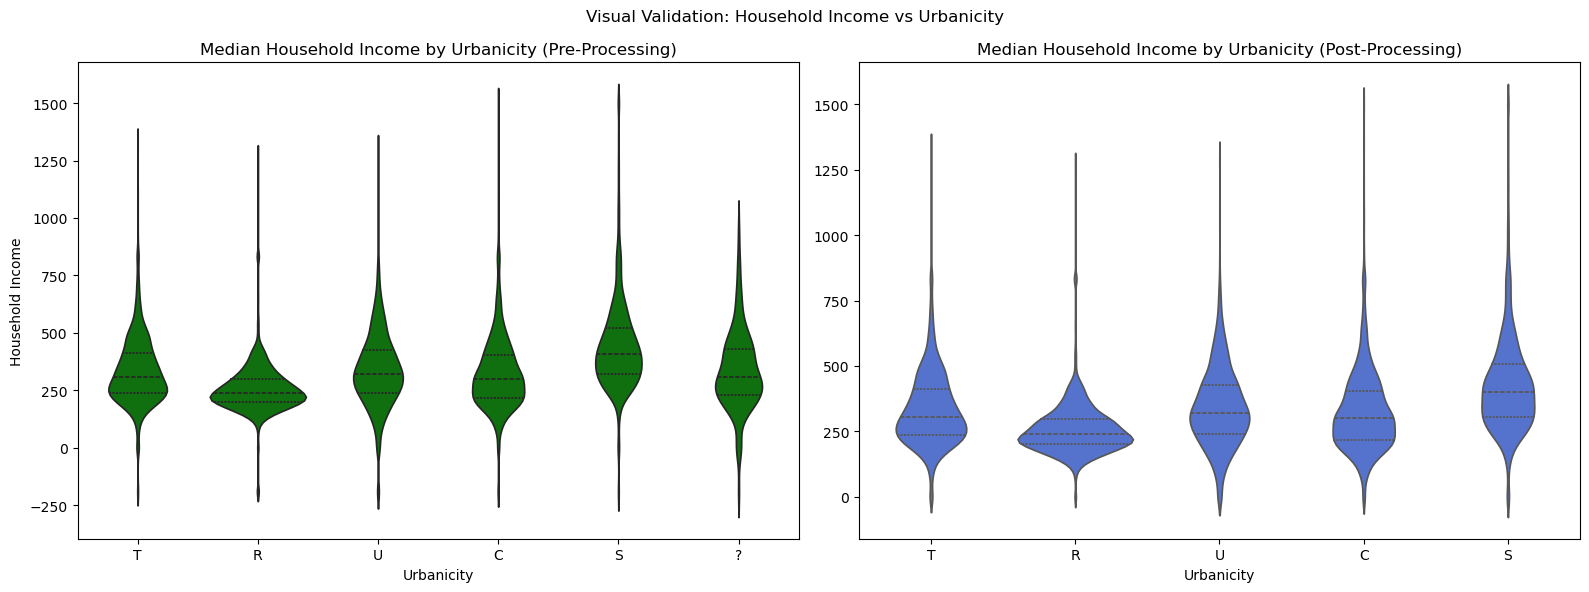

In [68]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.violinplot(x='URBANICITY', y='MEDIAN_HOUSEHOLD_INCOME', data=df, inner="quartile", ax=axes[0], color='green')
axes[0].set_title('Median Household Income by Urbanicity (Pre-Processing)')
axes[0].set_xlabel('Urbanicity')
axes[0].set_ylabel('Household Income')
sns.violinplot(x='urbanicity', y='median_household_income', data=df_copy, inner="quartile", ax=axes[1], color='royalblue')
axes[1].set_title('Median Household Income by Urbanicity (Post-Processing)')
axes[1].set_xlabel('Urbanicity')
axes[1].set_ylabel('')
plt.suptitle('Visual Validation: Household Income vs Urbanicity')
plt.tight_layout()
plt.show()
# Through this plots we can verify that the processing respected the natural distribution of the data

C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\2523933698.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax[1].legend()


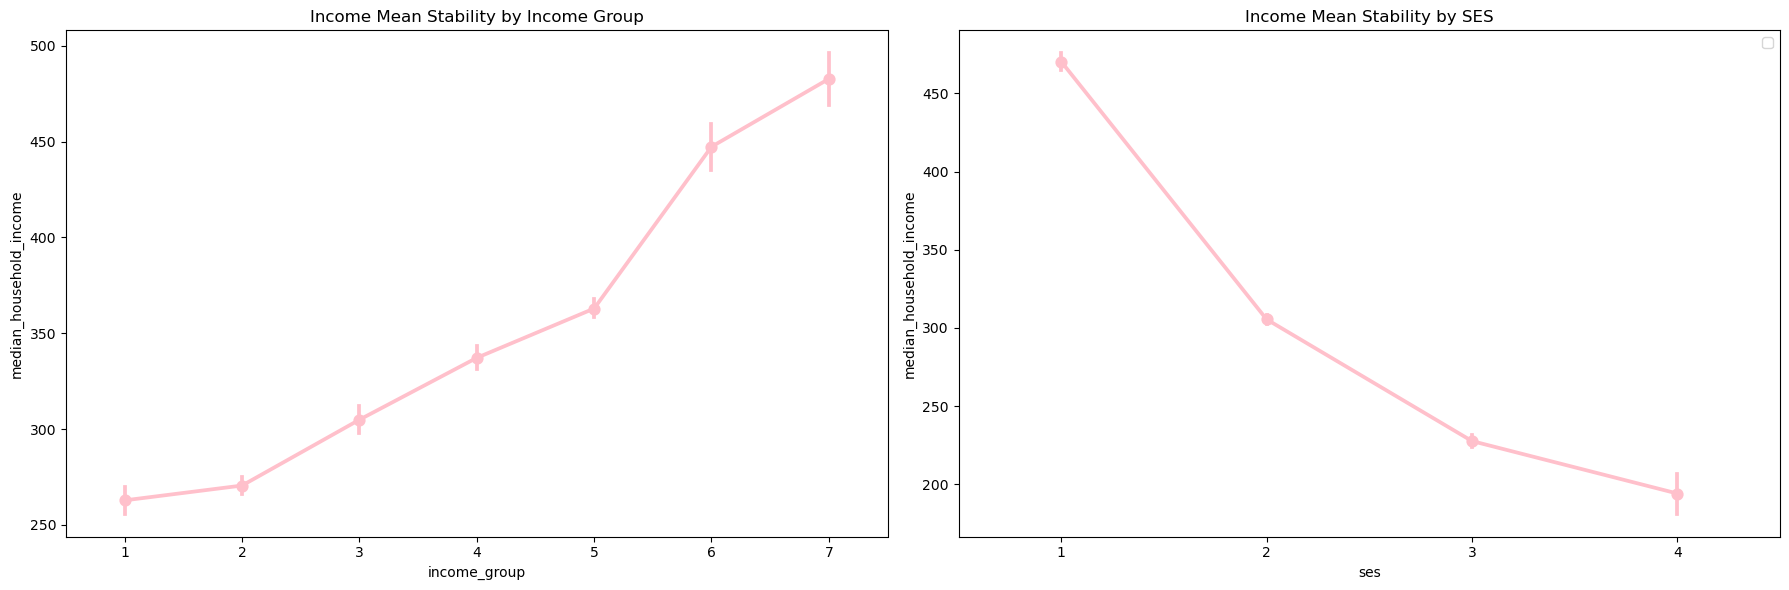

In [69]:
fig, ax = plt.subplots(1, 2, figsize=(18, 6))
sns.pointplot(x='income_group', y='median_household_income', data=df_copy, color='pink', ax=ax[0])
ax[0].set_title('Income Mean Stability by Income Group')
sns.pointplot(x='ses', y='median_household_income', data=df_copy, order=order_ses, color='pink', ax=ax[1])
ax[1].set_title('Income Mean Stability by SES')
ax[1].legend()
plt.tight_layout()
plt.show()
# Through this plots we can understand the order of these ordinal categorical features

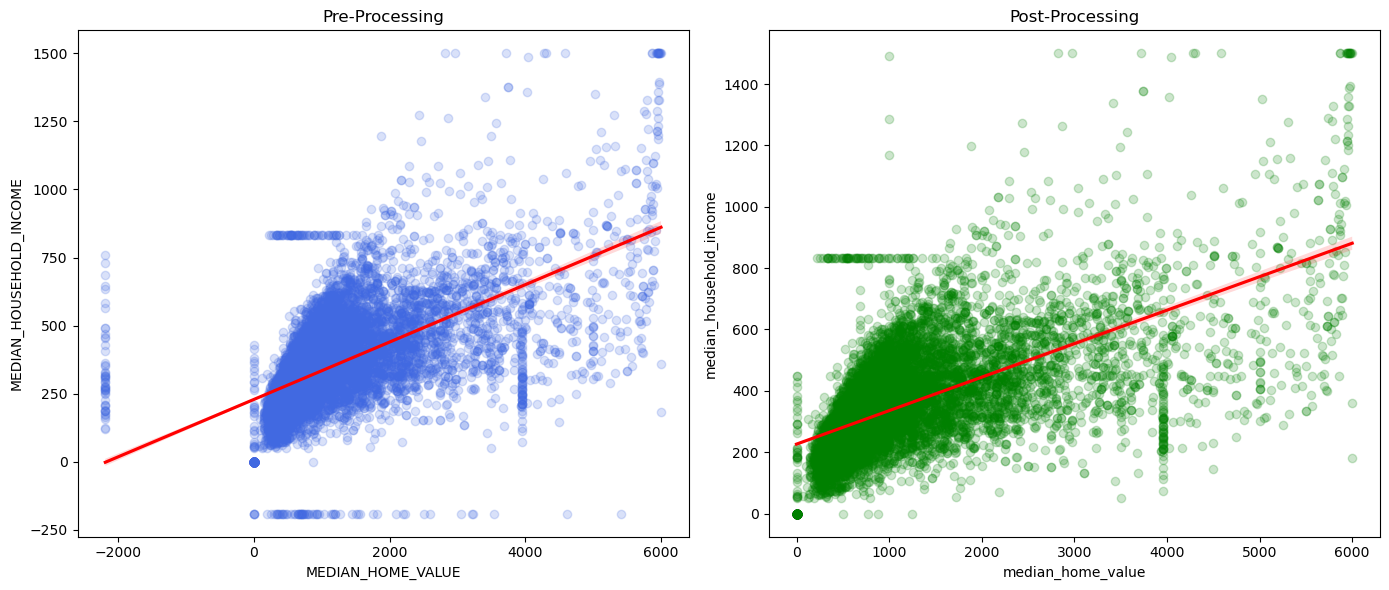

In [70]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.regplot(x='MEDIAN_HOME_VALUE', y='MEDIAN_HOUSEHOLD_INCOME', data=df, scatter_kws={'alpha': 0.2, 'color': 'royalblue'}, line_kws={'color': 'red'}, ax=axes[0])
axes[0].set_title('Pre-Processing')
sns.regplot(x='median_home_value', y='median_household_income', data=df_copy, scatter_kws={'alpha': 0.2, 'color': 'green'}, line_kws={'color': 'red'}, ax=axes[1])
axes[1].set_title('Post-Processing')
plt.tight_layout()
plt.show()
# Through this plots we can verify if the processing respected the natural distribution of the data; plus, the regression line maintains its slope

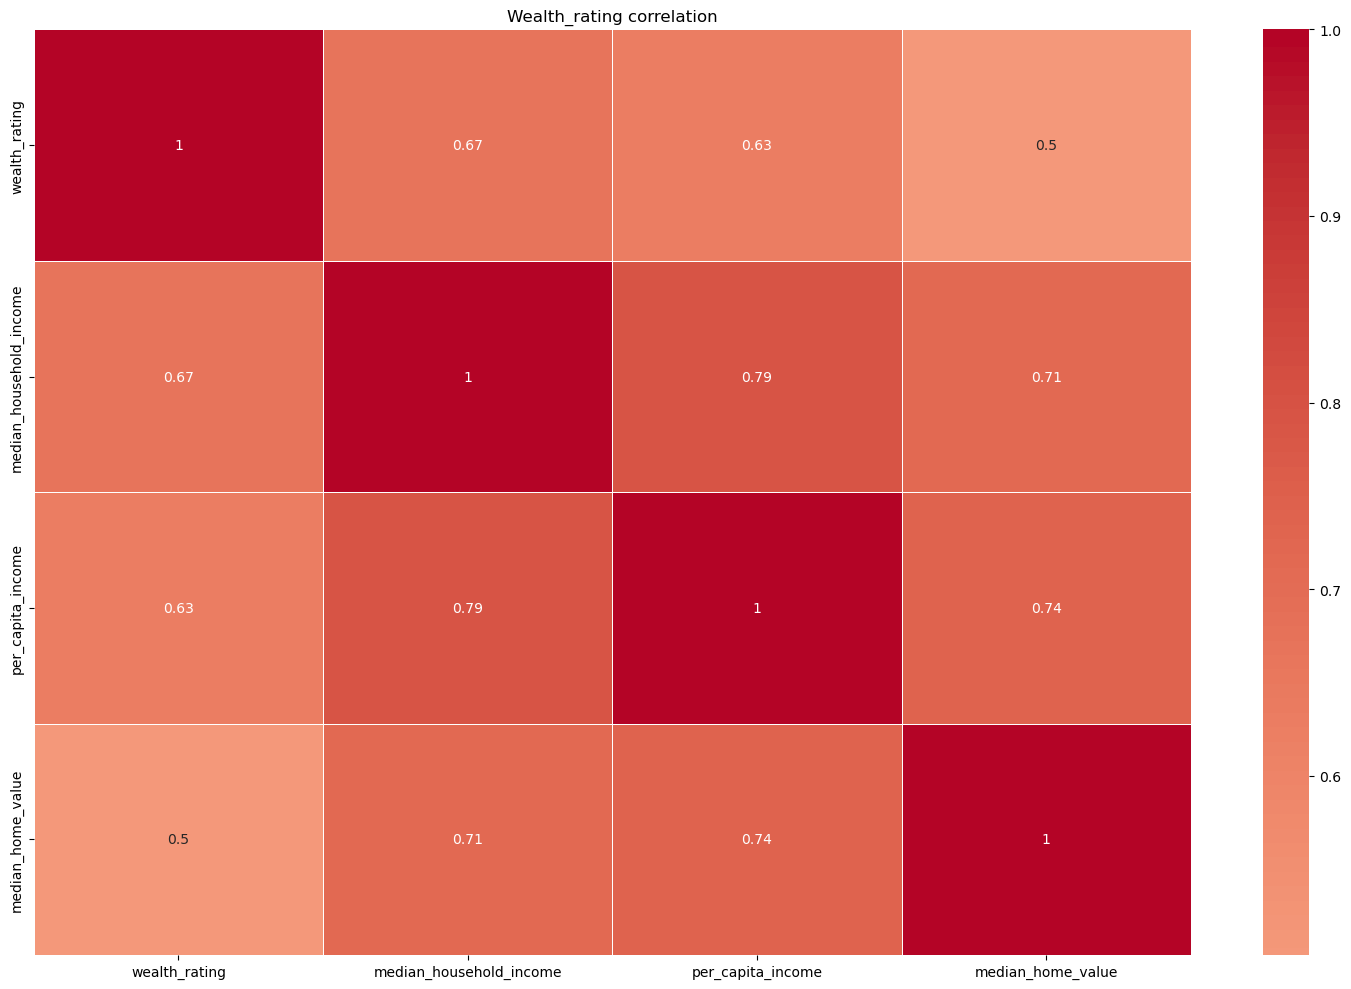

In [71]:
# Wealth Rating
# This feature must be >0
df_copy.loc[(df_copy['wealth_rating']<0) | (df_copy['wealth_rating']>9), 'wealth_rating'] = np.nan
# print(df_copy['wealth_rating'].value_counts())
# print(df_copy['wealth_rating'].isnull().sum())
# When a variable has to many null values like this one, imputing them with the mean, meadian, or other methods, is going to introduce a big bias to it
# In this case we use knn to estimate values by considering the values of the closest data points of the features that are the most correlated
subset = ['wealth_rating','median_household_income', 'per_capita_income', 'median_home_value']
plot_corr_num(df_copy[subset], 'Wealth_rating correlation')
df_wealth = df_copy[subset]
imputer = KNNImputer(n_neighbors=3)
df_imputed = pd.DataFrame(imputer.fit_transform(df_wealth), columns=subset, index=df_copy.index)
df_copy['wealth_rating'] = df_imputed['wealth_rating'].round().clip(0,9).astype('Int64')
#print(df_copy['wealth_rating'].value_counts())
#print(df_copy['wealth_rating'].isnull().sum())

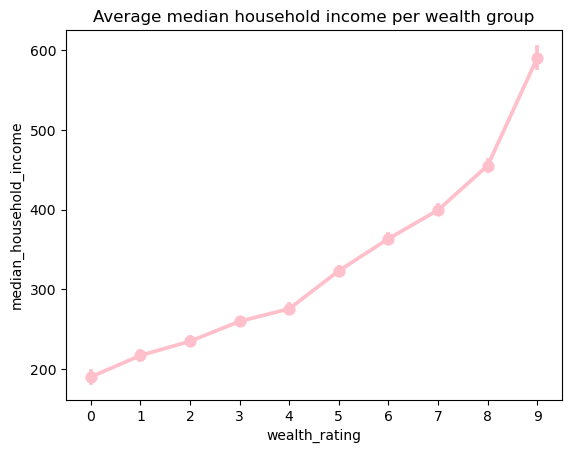

In [72]:
sns.pointplot(x='wealth_rating', y='median_household_income', data=df_copy, color='pink')
plt.title('Average median household income per wealth group')
plt.show()
# Through this plots we can understand the order of these ordinal feature

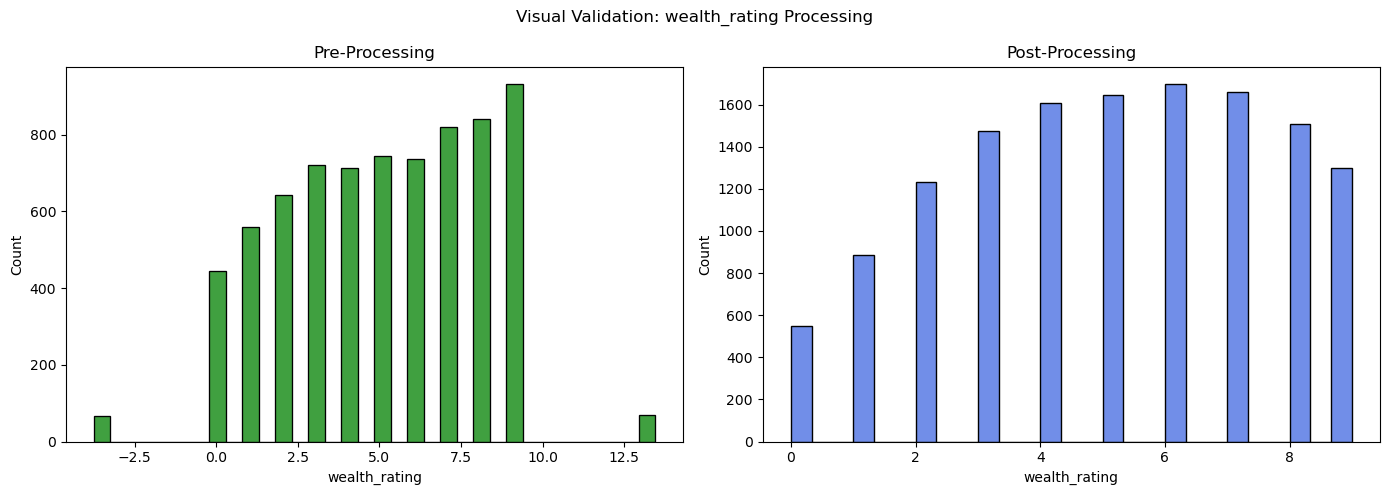

In [73]:
hist_plot('wealth_rating')

In [74]:
# Donor_age
# df_copy['donor_age'].isnull().sum()
# df_copy['donor_age'].describe()
# This feature must be >= 18
df_copy.loc[(df_copy['donor_age'] < 18), 'donor_age'] = np.nan
# Null values were filled with the median preserving data integrity
df_copy['donor_age'] = df_copy['donor_age'].fillna(df_copy['donor_age'].median())
# Assure feature consistency
df_copy['donor_age'] = df_copy['donor_age'].round(0).astype(int)

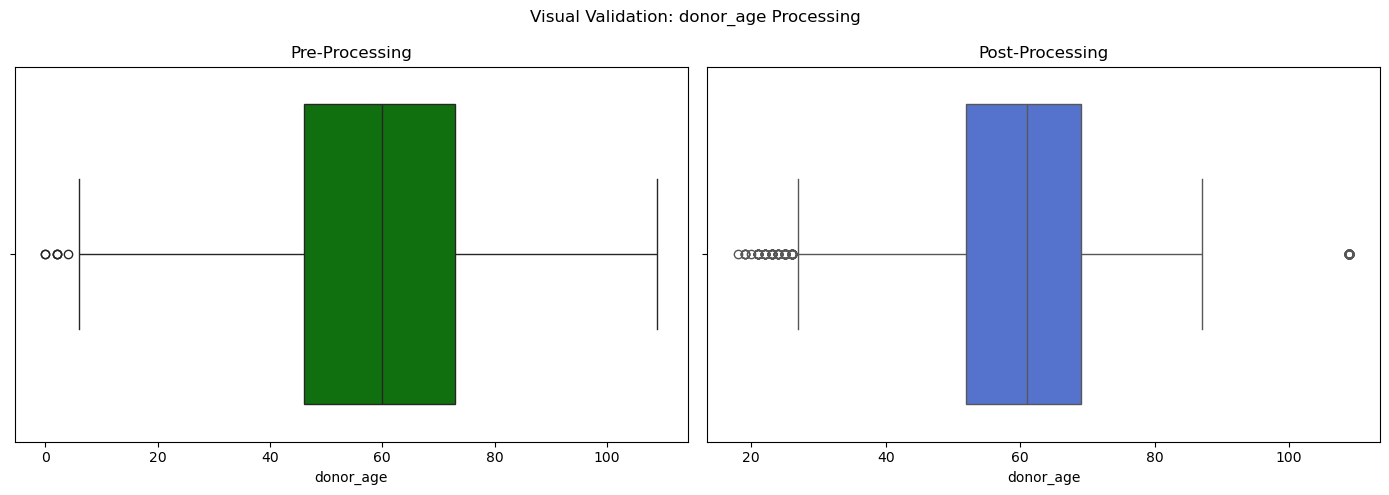

In [75]:
box_plot('donor_age')

In [76]:
# lifetime_gift_count and lifetime_gift_amount
# Both variables can not have negative values
cols = ['lifetime_gift_count','lifetime_gift_amount']
df_copy[cols] = df_copy[cols].mask(df_copy[cols] < 0)
# To impute the nulls on these variables we took into consideration two rules
# If we have an amount described - count has to be at least 1
df_copy.loc[(df_copy['lifetime_gift_amount'] > 0) & (df_copy['lifetime_gift_count'].isnull()), 'lifetime_gift_count'] = 1
# If we have a count then the amount must be the median for that count
df_copy['lifetime_gift_amount'] = (df_copy.groupby('lifetime_gift_count')['lifetime_gift_amount'].transform(lambda x: x.fillna(x.median())))
# The rest of the nulls is where both count and amount are null so both go to 0
df_copy['lifetime_gift_amount'].fillna(0, inplace=True)
df_copy['lifetime_gift_count'].fillna(0,inplace=True)
# print(df_copy['lifetime_gift_amount'].isnull().sum())
# print(df_copy['lifetime_gift_count'].isnull().sum())
# Even though there are outliers they aren't necessarly wrong. To make sure they are considered but do not impact to much the cluster we put a cap in both count and amount
df_copy.loc[df_copy['lifetime_gift_count']>df_copy['lifetime_gift_count'].quantile(0.99),'lifetime_gift_count'] = df_copy['lifetime_gift_count'].quantile(0.99)
df_copy.loc[df_copy['lifetime_gift_amount']>df_copy['lifetime_gift_amount'].quantile(0.99),'lifetime_gift_amount'] = df_copy['lifetime_gift_amount'].quantile(0.99)
# print(df_copy[((df_copy['lifetime_gift_amount']==0)&(df_copy['lifetime_gift_count']!=0)) | ((df_copy['lifetime_gift_amount']!=0)&(df_copy['lifetime_gift_count']==0))])

C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\1644465261.py:11: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy['lifetime_gift_amount'].fillna(0, inplace=True)
C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\1644465261.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

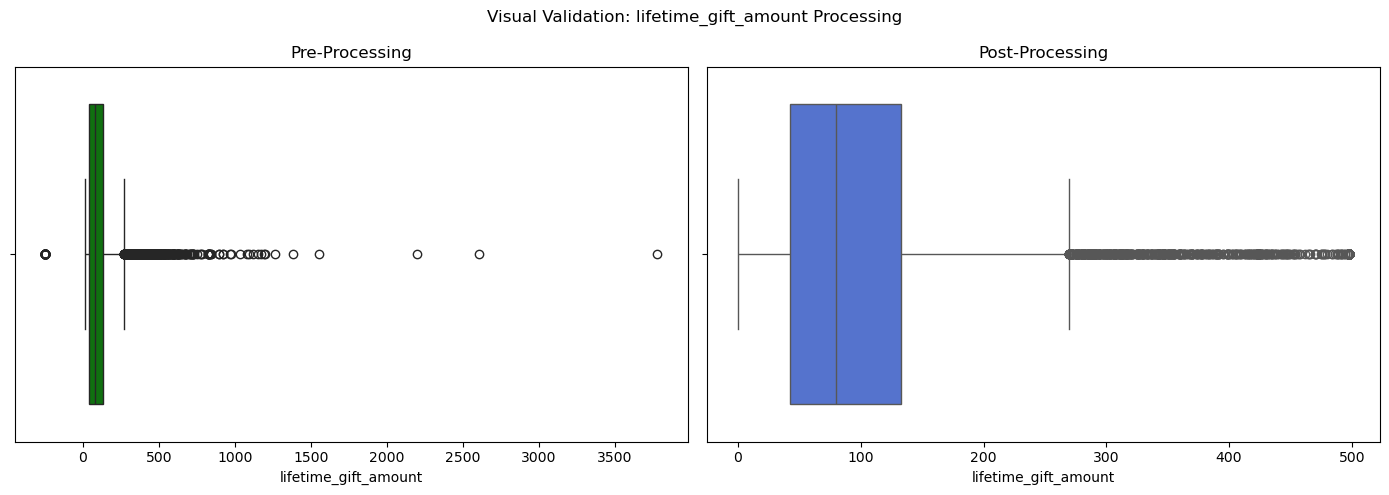

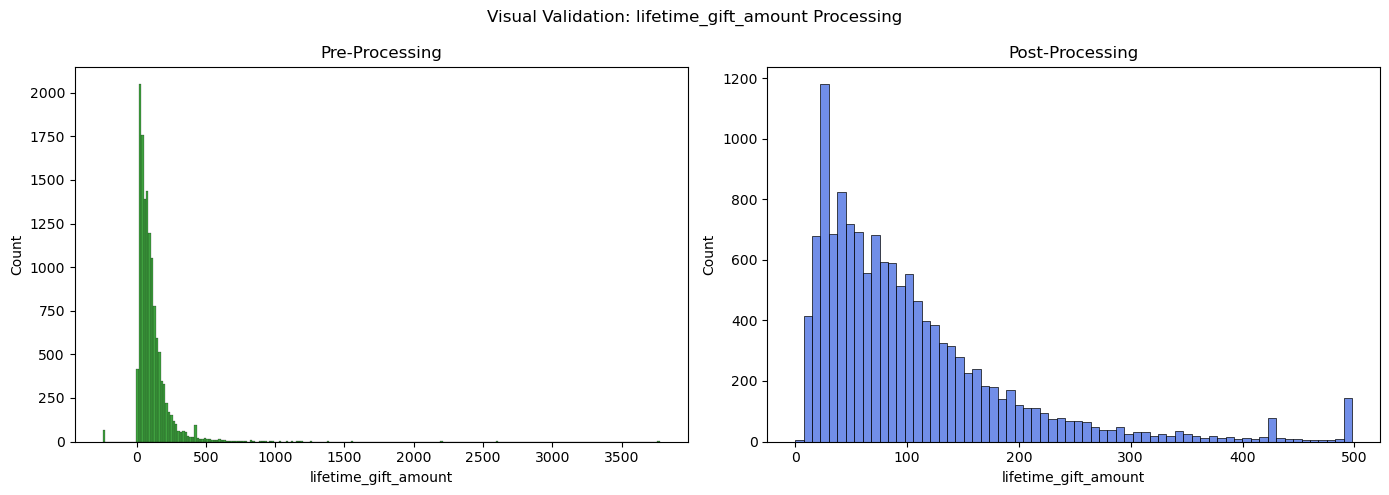

In [77]:
box_plot('lifetime_gift_amount')
hist_plot('lifetime_gift_amount')

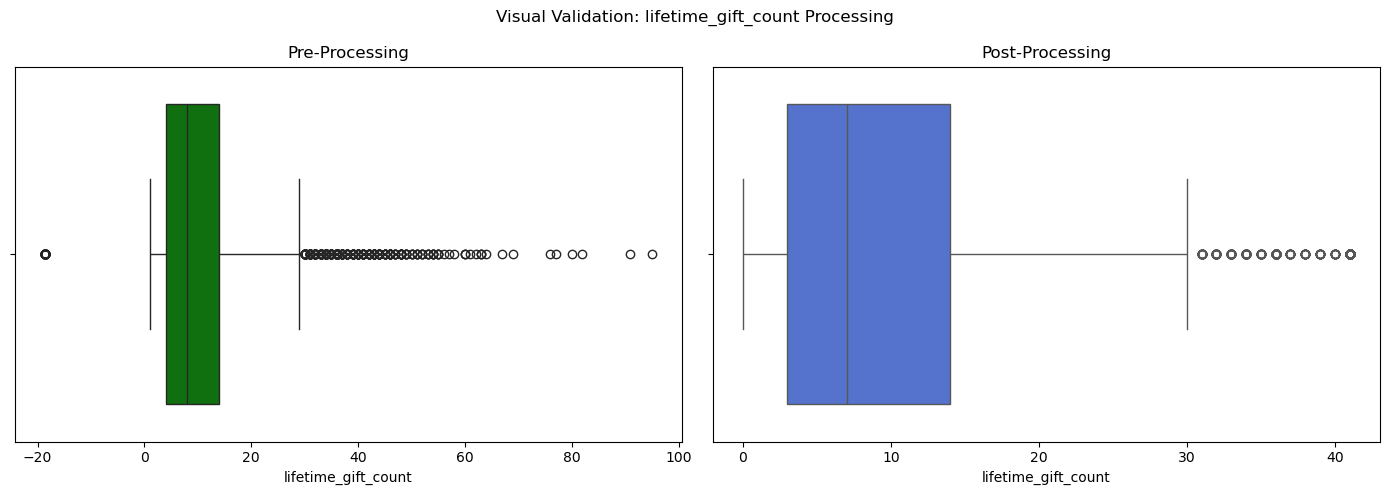

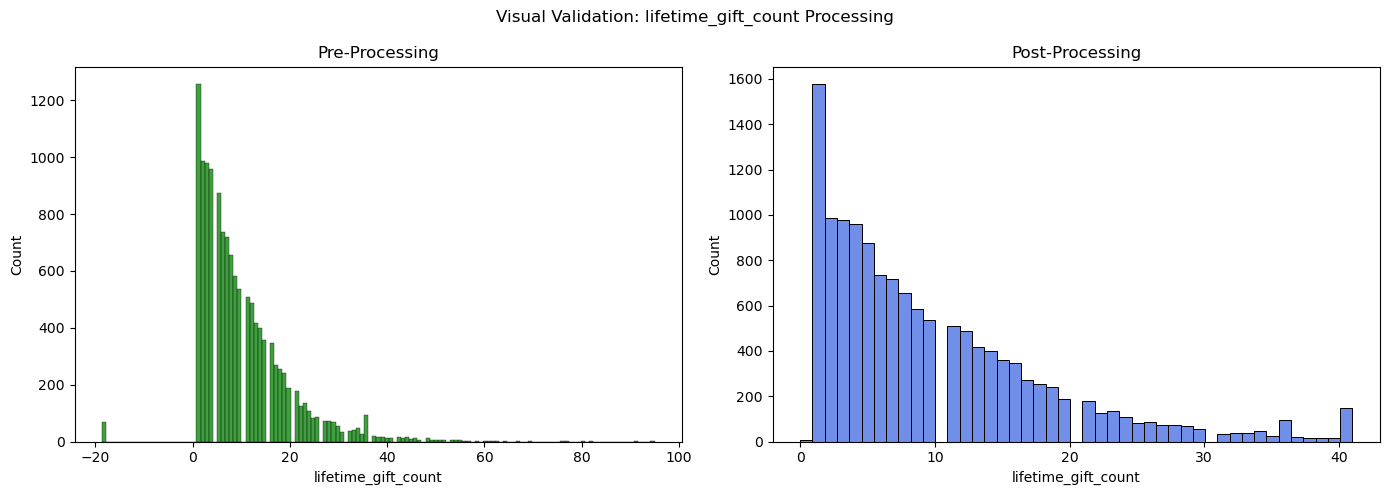

In [78]:
box_plot('lifetime_gift_count')
hist_plot('lifetime_gift_count')

<Axes: xlabel='lifetime_gift_amount', ylabel='lifetime_gift_count'>

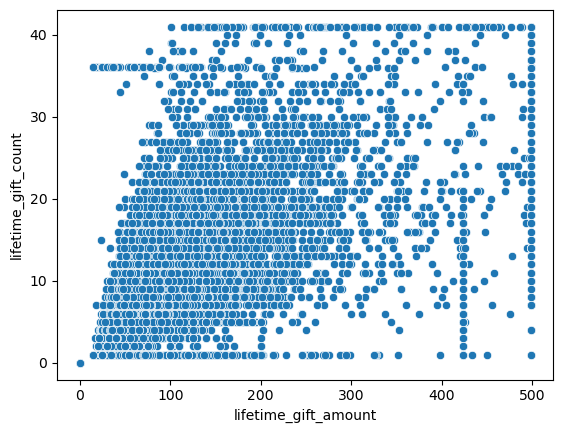

In [79]:
sns.scatterplot(x = 'lifetime_gift_amount', y = 'lifetime_gift_count', data = df_copy)
# This graph it is only used to make sure that any count/amount that is 0 it is met with the same amount/count from the other value

In [80]:
# lifetime_min_gift_amt, lifetime_max_gift_amt, Recent_avg_git_amt and Last_gift_amt
# These features must be >0
cols = ['lifetime_min_gift_amt','lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']
df_copy[cols] = df_copy[cols].mask(df_copy[cols]<0)
# To impute the nulls, we had into consideration the transformations made in the other 2 variables before these
# If we have an inative donor both count and amount are 0; all the other columns should follow this exception and have values subtituted with 0
df_copy.loc[df_copy['lifetime_gift_count'] == 0, cols] = 0
# If we have a fairly new donor - count=1 (only 1 donation was made); all the other columns should have the same value as lifetime_gift_amount
df_copy.loc[df_copy['lifetime_gift_count'] == 1, cols] = df_copy.loc[df_copy['lifetime_gift_count'] == 1, 'lifetime_gift_amount']
# For the values that were not treated in the previous conditions, we will impute with the median of each column when the donor is active (count>0)
median_value = df_copy.loc[df_copy['lifetime_gift_count'] > 0, cols].median()
df_copy[cols] = df_copy[cols].fillna(median_value)
# Now we need to make sure that the max amount is greater or equal to the max('lifetime_min_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt')
maximum_vals = df_copy[['lifetime_min_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']].max(axis=1)
df_copy['lifetime_max_gift_amt'] = np.maximum(df_copy['lifetime_max_gift_amt'], maximum_vals)
# and that the min amount is less or equal to the min('lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt')
minimum_vals = df_copy[['lifetime_max_gift_amt', 'recent_avg_gift_amt', 'last_gift_amt']].min(axis=1)
df_copy['lifetime_min_gift_amt'] = np.minimum(df_copy['lifetime_min_gift_amt'], minimum_vals)

In [81]:
# for col in cols:
#   print(df_copy[col].describe())
#   print(df_copy[col].isnull().sum())

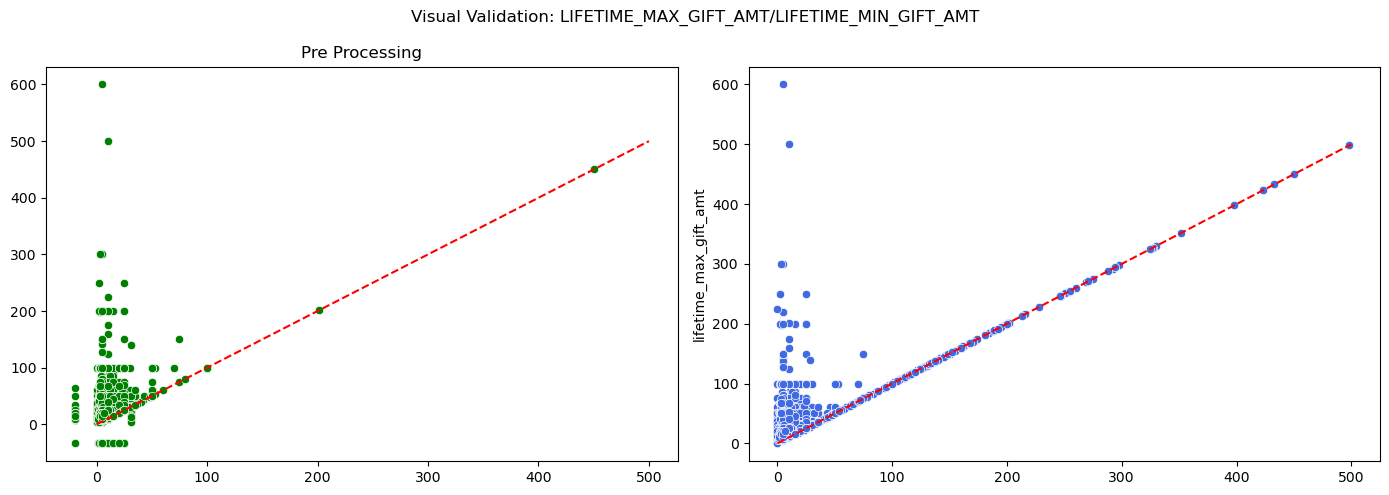

In [82]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.scatterplot(y=df['LIFETIME_MAX_GIFT_AMT'], x=df['LIFETIME_MIN_GIFT_AMT'], ax=axes[0], color='green')
axes[0].plot([0, 500], [0, 500], linestyle='--', color='red')
axes[0].set_title("Pre Processing")
axes[0].set_xlabel("")
axes[0].set_ylabel("")
sns.scatterplot(y=df_copy['lifetime_max_gift_amt'], x=df_copy['lifetime_min_gift_amt'], ax=axes[1], color='royalblue')
axes[1].plot([0, 500], [0, 500], linestyle='--', color='red')
axes[1].set_title("")
axes[1].set_xlabel("")
plt.suptitle("Visual Validation: LIFETIME_MAX_GIFT_AMT/LIFETIME_MIN_GIFT_AMT")
plt.tight_layout()
plt.show()
# This chart is used only to make sure that every max amount is greater than every min amount and vice-versa

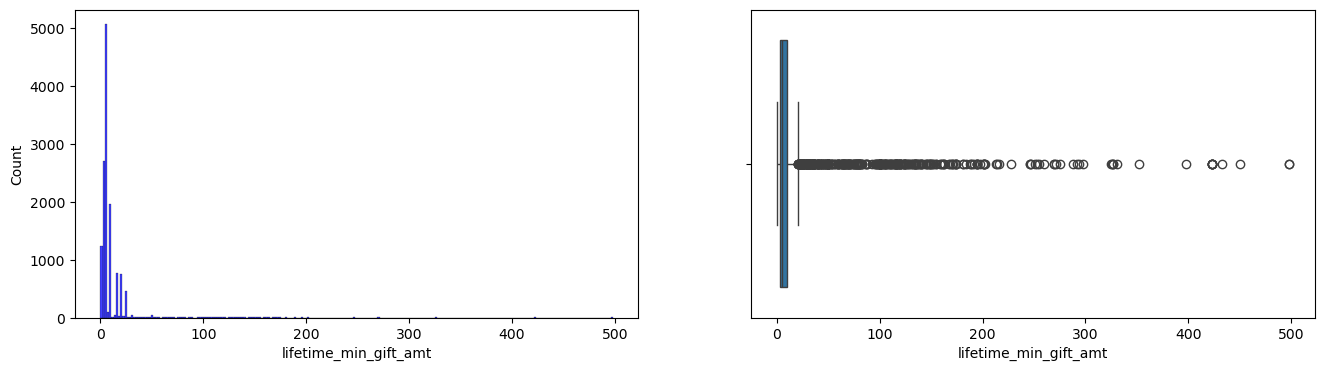

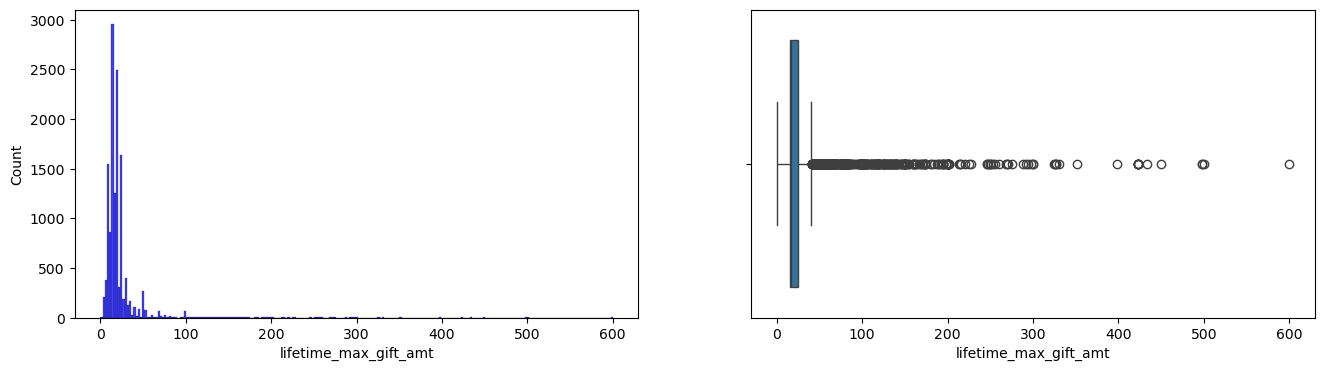

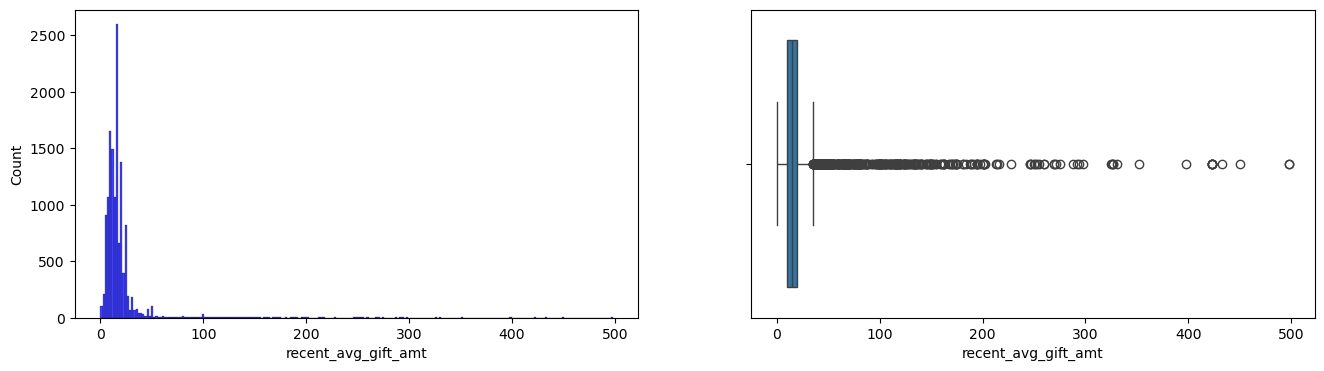

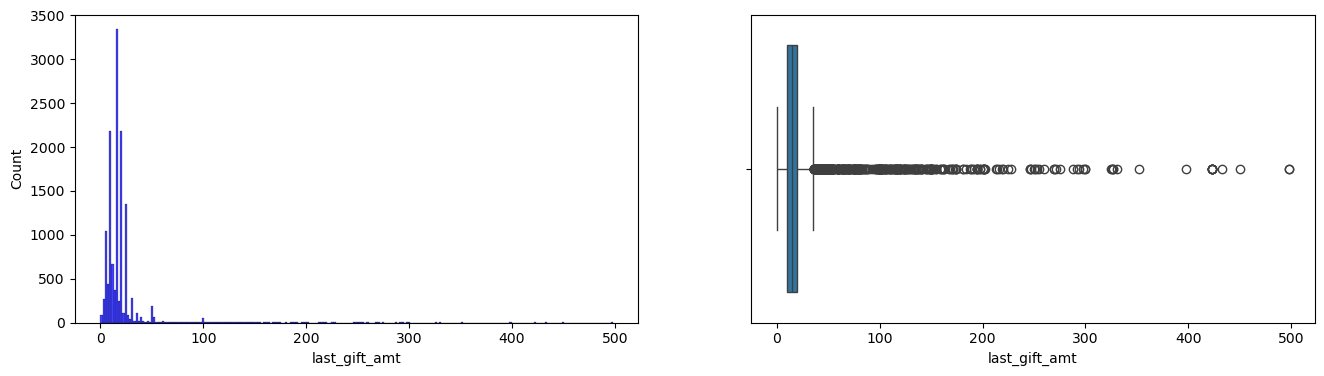

In [83]:
for col in cols:
  boxplot_hist(df_copy,col)

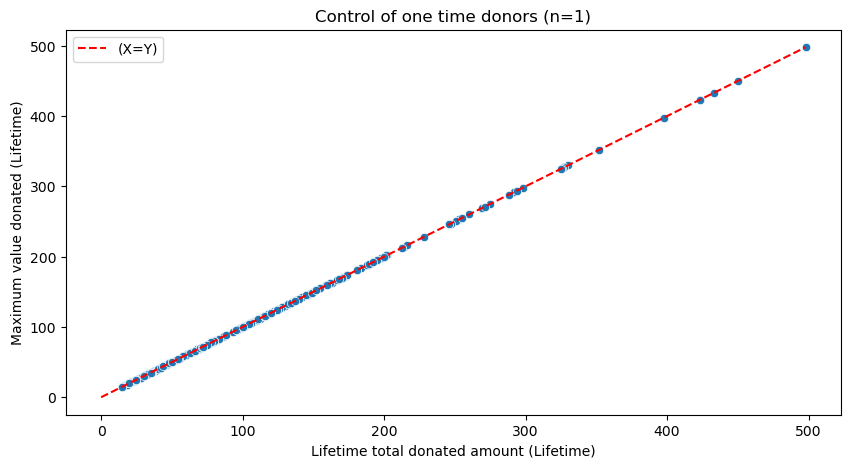

In [84]:
# lifetime_gift_count and lifetime_gift_amount
# Filtering for donors with only one dontaion made
df_1d = df_copy[df_copy['lifetime_gift_count'] == 1]
plt.figure(figsize=(10, 5))
sns.scatterplot(x='lifetime_gift_amount', y='lifetime_max_gift_amt', data=df_1d)
max_val = df_1d['lifetime_gift_amount'].max()
plt.plot([0, max_val], [0, max_val], color='red', linestyle='--', label='(X=Y)')
plt.title('Control of one time donors (n=1)')
plt.xlabel('Lifetime total donated amount (Lifetime)')
plt.ylabel('Maximum value donated (Lifetime)')
plt.legend()
plt.show()
# This chart is used to check ofr any one time donor wich the max amount and lifetime amount do not match

In [85]:
# Recent_avg_card_gift_amt
# This feature must be >0
df_copy.loc[df_copy['recent_avg_card_gift_amt'] < 0, 'recent_avg_card_gift_amt'] = np.nan
# Null values were filled by thinking of this variable as a "daughter" to recent_avg_gift_amt
# So we are going to calculate the ratio for the avg donation made in response to a card
ratio_card = np.where(df_copy['recent_avg_gift_amt']>0,df_copy['recent_avg_card_gift_amt'] / df_copy['recent_avg_gift_amt'],0).mean()
# And now the null values are going to be filled taking into consideration the ratio
df_copy['recent_avg_card_gift_amt'] = df_copy['recent_avg_card_gift_amt'].fillna(df_copy['recent_avg_gift_amt'] * ratio_card)
# Yet we still have to guarantee that when we do not have an active donor (count=0) that the corresponding value is 0
df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'recent_avg_card_gift_amt'] = 0

In [86]:
# file_card_gift
# This feature must be >0
df_copy.loc[df_copy['file_card_gift'] < 0, 'file_card_gift'] = np.nan
# To imput the nulls we will consider this variable as a "daughter" to lifetime_gift_amt
# So we are going to calculate the ratio for the lifetime avg donation amount that was done in response to all cards
ratio_amt = np.where(df_copy['lifetime_gift_amount']>0, df_copy['file_card_gift'] / df_copy['lifetime_gift_amount'],0).mean()
# And now the null values are going to be filled taking into consideration the ratio
df_copy['file_card_gift'] = df_copy['file_card_gift'].fillna(df_copy['lifetime_gift_amount'] * ratio_amt)
# Yet we still have to guarantee that when we do not have an active donor (count=0) that the corresponding value is 0
df_copy.loc[df_copy['lifetime_gift_count'] == 0, 'file_card_gift'] = 0

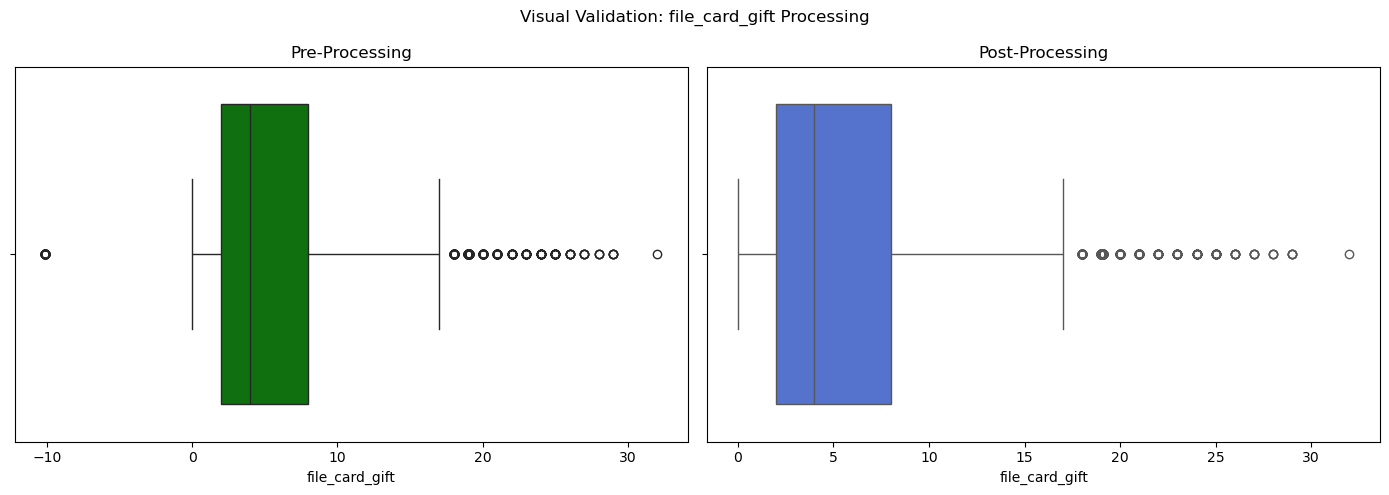

In [87]:
box_plot('file_card_gift')

In [88]:
# recency_status_96nk
# For this feature it was assumed as a screenshot taken the moment the dataset was extracted. This means that it can't just be imput with months_since_fisrt_gift(last_gift).
# print(df_copy['recency_status_96nk'].value_counts(dropna=False))
# Value input with mode - in this case A is very strong so it makes sense
df_copy['recency_status_96nk'] = df_copy['recency_status_96nk'].fillna(df_copy['recency_status_96nk'].mode()[0])
# df_copy['recency_status_96nk'].isnull().sum()

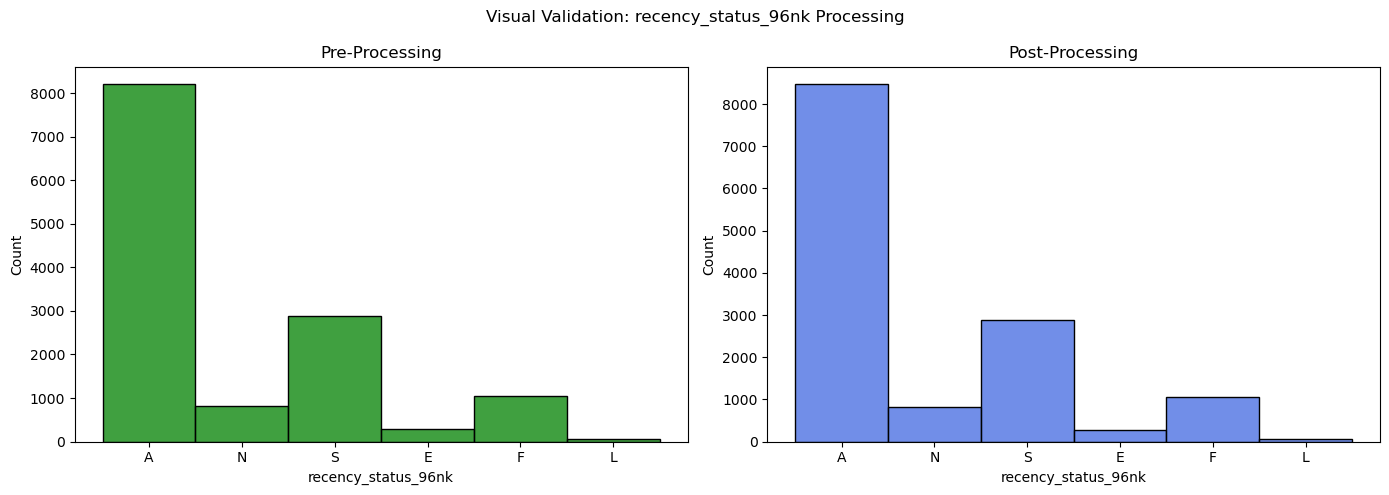

In [89]:
hist_plot('recency_status_96nk')

In [90]:
# frequency_status_97nk
# print(df_copy['frequency_status_97nk'].describe())
# This feature must be >0
df_copy.loc[df_copy['frequency_status_97nk']<0, 'frequency_status_97nk'] = np.nan
# value input with mode based on wich status from recency status 96 because donors with the same status will have similar number of status donated in last period
df_copy['frequency_status_97nk'] = df_copy.groupby(df_copy['recency_status_96nk'])['frequency_status_97nk'].transform(lambda x: x.fillna(x.mode()[0]))
# Round decimal values to assure feature consistency
df_copy['frequency_status_97nk'] = df_copy['frequency_status_97nk'].abs().round().astype(int)
# print(df_copy['frequency_status_97nk'].value_counts(dropna=False))

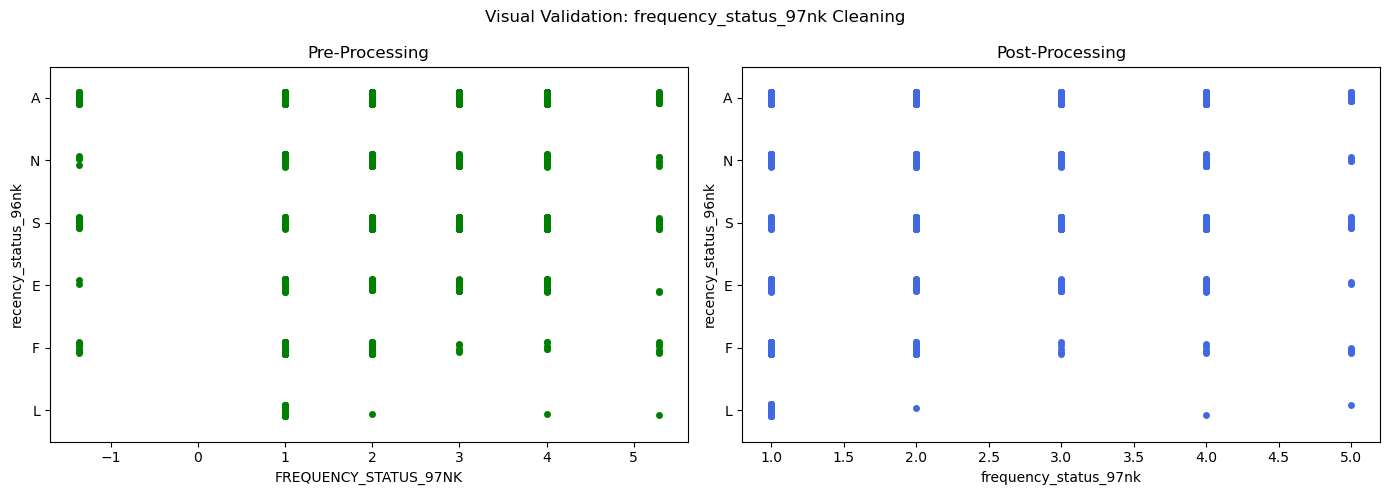

In [91]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))
sns.stripplot(x ='FREQUENCY_STATUS_97NK', y = 'RECENCY_STATUS_96NK', data = df, ax=axes[0], color='green')
axes[0].set_title("Pre-Processing")
axes[0].set_ylabel("recency_status_96nk")
sns.stripplot(x ='frequency_status_97nk', y = 'recency_status_96nk', data = df_copy, ax=axes[1], color='royalblue')
axes[1].set_title("Post-Processing")
axes[1].set_ylabel("recency_status_96nk")
plt.suptitle("Visual Validation: frequency_status_97nk Cleaning")
plt.tight_layout()
plt.show()
# With this plot we verify if frequency status will stay in the same range for all status before and after cleaning since they are dependent on each other

In [92]:
# months_since_first_gift & months_since_last_gift
cols = ['months_since_first_gift', 'months_since_last_gift']
# These features must be >0
df_copy.loc[df_copy['months_since_first_gift']<0, 'months_since_first_gift' ] = np.nan
df_copy.loc[df_copy['months_since_last_gift']<0, 'months_since_last_gift' ] = np.nan
# The moment the dataset was extracted all the status were calculated based on the months columns. This mean that we can imput the months columns with the mode for the specific donor status
# Since months_since_first_gift must be greater than months_since_last_gift than we imput months_since_first_gift with either the mode function or months_since_last_gift, wichever is greater
# This function finds the mode for every months_since_first_gift based on recency status (not just null values)
group_modes = df_copy.groupby('recency_status_96nk')['months_since_first_gift'].transform(lambda x: x.mode()[0] if not x.mode().empty else np.nan)
# Find the maximum between the mode for that status and months_since_last_gift
fill_values = np.maximum(group_modes, df_copy['months_since_last_gift'].fillna(0))
# Imputs the bigger value
df_copy['months_since_first_gift'] = df_copy['months_since_first_gift'].fillna(fill_values)
# If months_since_first_gift < months_since_last_gift then months_since_last_gift is imput with months_since_first_gift
df_copy.loc[df_copy['months_since_first_gift']<df_copy['months_since_last_gift'], 'months_since_first_gift'] = df_copy.loc[df_copy['months_since_first_gift']<df_copy['months_since_last_gift'], 'months_since_last_gift']
# Imputs the rest of the months since last gift nulls with the months since first
df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].fillna(df_copy['months_since_first_gift'])
df_copy['months_since_first_gift'] = df_copy['months_since_first_gift'].abs().round().astype(int)
df_copy['months_since_last_gift'] = df_copy['months_since_last_gift'].abs().round().astype(int)
# for col in cols:
#   print(df_copy[col].isnull().sum())
#   print(df_copy[col].describe())
df_copy.loc[df_copy['months_since_first_gift']<df_copy['months_since_first_gift'], ['months_since_first_gift','months_since_last_gift']]
# Since there are diferent outliers for both months since first and since last deending on wich recency_status, It is necessary to
# control them inside each status
for col in cols:
    # Calculate the 99th percentile per group
    upper_limits = df_copy.groupby('recency_status_96nk')[col].transform(lambda x: x.quantile(0.99))
    # Cap values that exceed their specific group's threshold
    df_copy[col] = np.where(df_copy[col] > upper_limits, upper_limits, df_copy[col])
# Since there are a few donors with the count =0 than these should have a months_since_last_gift(first_gift) so we imput these with the max. This is just to create a penalization system wich won't appear in the cluster because we exclude people with 0 gifts
df_copy.loc[df_copy['lifetime_gift_count']==0, 'months_since_first_gift'] = max(df_copy['months_since_first_gift'])
df_copy.loc[df_copy['lifetime_gift_count']==0, 'months_since_last_gift'] = max(df_copy['months_since_last_gift'])

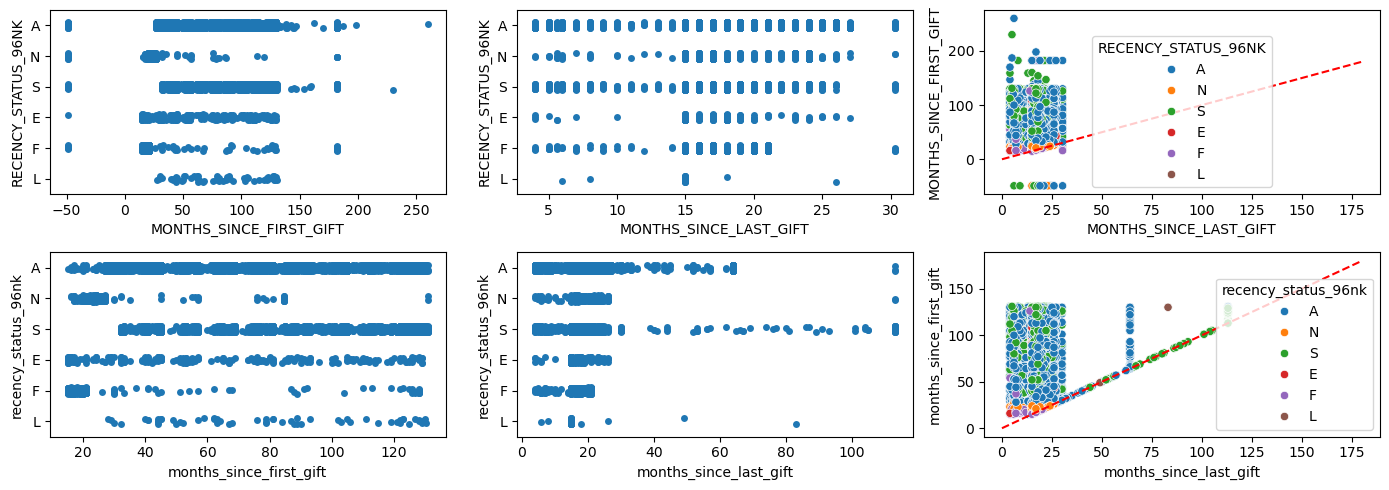

In [93]:
fig, axes = plt.subplots(2, 3, figsize=(14, 5))
sns.stripplot(x = 'MONTHS_SINCE_FIRST_GIFT', y = 'RECENCY_STATUS_96NK', data = df, ax = axes[0,0])
sns.stripplot(x = 'MONTHS_SINCE_LAST_GIFT', y = 'RECENCY_STATUS_96NK', data = df, ax = axes[0,1])
sns.scatterplot(x='MONTHS_SINCE_LAST_GIFT', y='MONTHS_SINCE_FIRST_GIFT',hue = 'RECENCY_STATUS_96NK', data=df, ax = axes[0,2])
axes[0, 2].plot([0, 180], [0, 180], color='red', linestyle='--')
sns.stripplot(x = 'months_since_first_gift', y = 'recency_status_96nk', data = df_copy, ax = axes[1,0])
sns.stripplot(x = 'months_since_last_gift', y = 'recency_status_96nk', data = df_copy, ax = axes[1,1])
sns.scatterplot(x='months_since_last_gift', y='months_since_first_gift',hue = 'recency_status_96nk', data=df_copy, ax = axes[1,2])
axes[1, 2].plot([0, 180], [0, 180], color='red', linestyle='--')
plt.tight_layout()
plt.show()
# When a scatterplot of recency_status and months_since_first_gift(last_gift) is made we can see that it does not follow the pattern it is descrbed in the guidelines. This happens because we assume that from the moment the dataset was extracted no one has made a change in the status,
# but the months continue to pass and because the months columns are calculated columns they continued to increase in value.

In [94]:
# Pep_star and Recent_star_status
# Both pep_star and recent_star_status should have only values of 0 or 1. Eventhought recent_star_status has values ranging to 22, does't make sense with the variable guidelines.
df_copy.loc[~df_copy['pep_star'].isin([0,1]), 'pep_star'] = np.nan
df_copy.loc[df_copy['recent_star_status'] < 0, 'recent_star_status'] = np.nan
df_copy.loc[df_copy['recent_star_status'] > 1, 'recent_star_status'] = 1

# If recent_star_status is at least 1 or recency_status_96nk is S status then pep_star should also be 1
mask = (df_copy['recent_star_status']==1) | (df_copy['recency_status_96nk']=='S')
df_copy.loc[mask, 'pep_star'] = df_copy.loc[mask, 'pep_star'].fillna(1)

# Whatever null is left we can only assume that probably there hasn't been a star status
df_copy['recent_star_status'].fillna(0, inplace=True)
df_copy['pep_star'].fillna(0,inplace = True)
# print(df_copy['recent_star_status'].value_counts(dropna=False))
# print(df_copy['pep_star'].value_counts(dropna=False))

C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\3537599956.py:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df_copy['recent_star_status'].fillna(0, inplace=True)
C:\Users\beatr\AppData\Local\Temp\ipykernel_17948\3537599956.py:13: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.



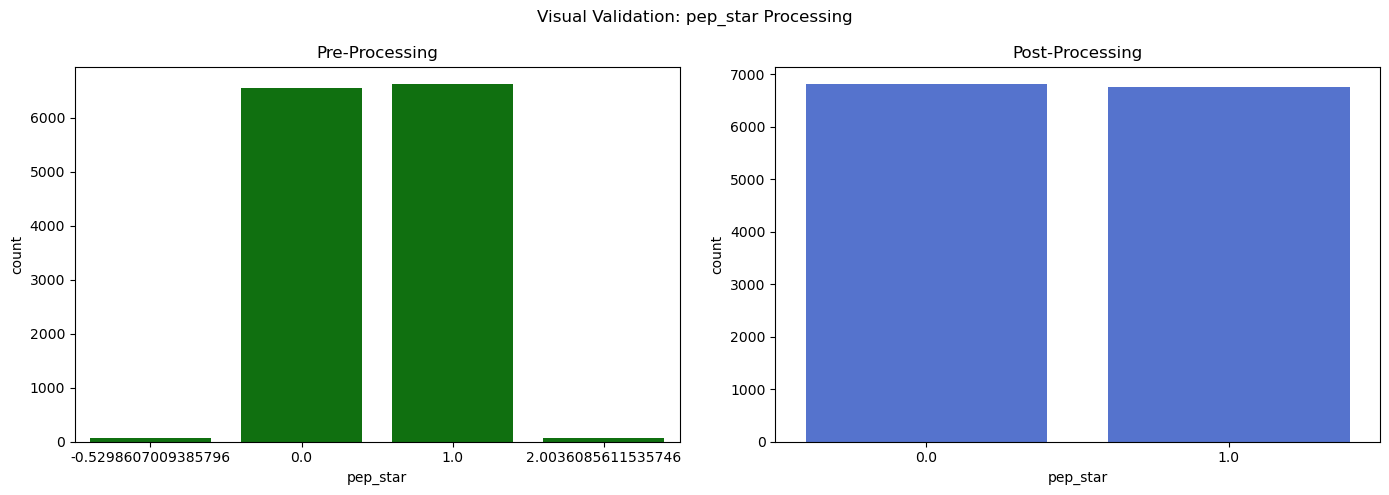

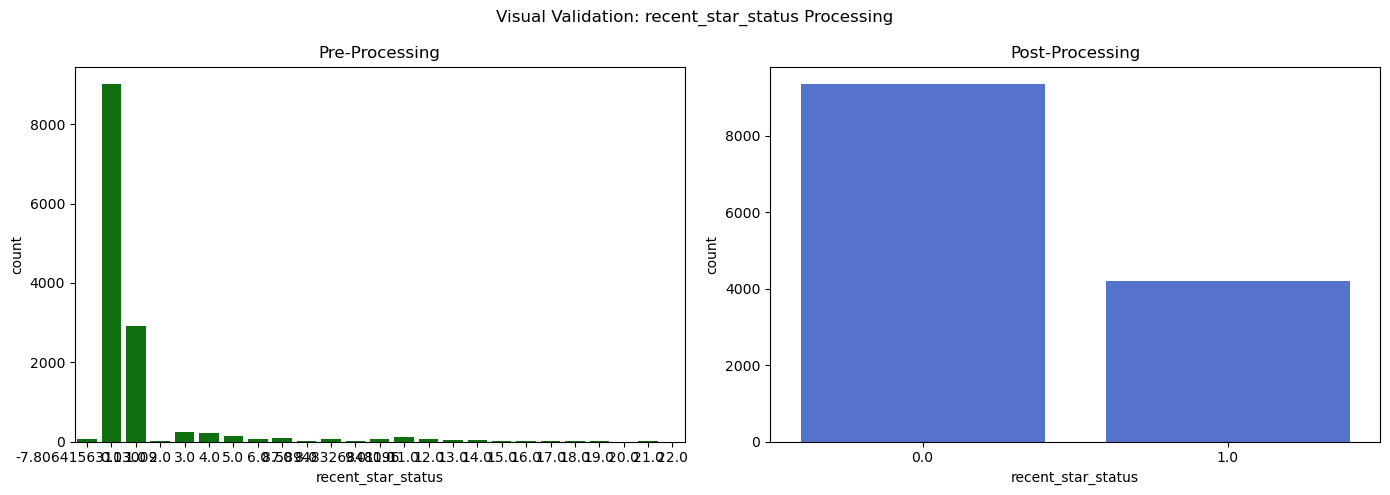

In [95]:
count_plot('pep_star')
count_plot('recent_star_status')

In [96]:
nulls = df_copy.isnull().sum()
nulls[nulls>0]

file_card_gift              332
recent_avg_card_gift_amt    319
dtype: int64

In [97]:
df_copy.info()

<class 'pandas.core.frame.DataFrame'>
Index: 13560 entries, 61745 to 45722
Data columns (total 40 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   card_prom_12                 13560 non-null  int64  
 1   children                     13560 non-null  int64  
 2   donor_age                    13560 non-null  int64  
 3   donor_gender                 13560 non-null  object 
 4   file_card_gift               13228 non-null  float64
 5   frequency_status_97nk        13560 non-null  int64  
 6   home_owner                   13560 non-null  object 
 7   income_group                 13560 non-null  int64  
 8   last_gift_amt                13560 non-null  float64
 9   lifetime_card_prom           13560 non-null  int64  
 10  lifetime_gift_amount         13560 non-null  float64
 11  lifetime_gift_count          13560 non-null  float64
 12  lifetime_max_gift_amt        13560 non-null  float64
 13  lifetime_min_gift

---
## 4.3. Feature Engineering <a name="feature-engineering"></a>


Being one of the goals of this assignement to identify and analyze reasonable segments for this set of donors we decided on 2 prespectives:
 - Donation Behaviour - We explore te donors behaviour in terms of donation frequency, variability, and activity;
 - Donation Engagement - We explore the donors engagement to promotions, more specifically focused on the card ones if they prefer cards or are more eficient to respond if a card is envolved.
 We use feature engineering in both clusters since we thought that better insights would be taken with the relationshipc that can be created

---
### 4.3.1. Donation_Behaviour <a name="donation-behavior"></a>


In [98]:
df_behaviour = df_copy.copy()

In [99]:
df_behaviour = df_behaviour[df_behaviour['lifetime_gift_count']>1].copy()

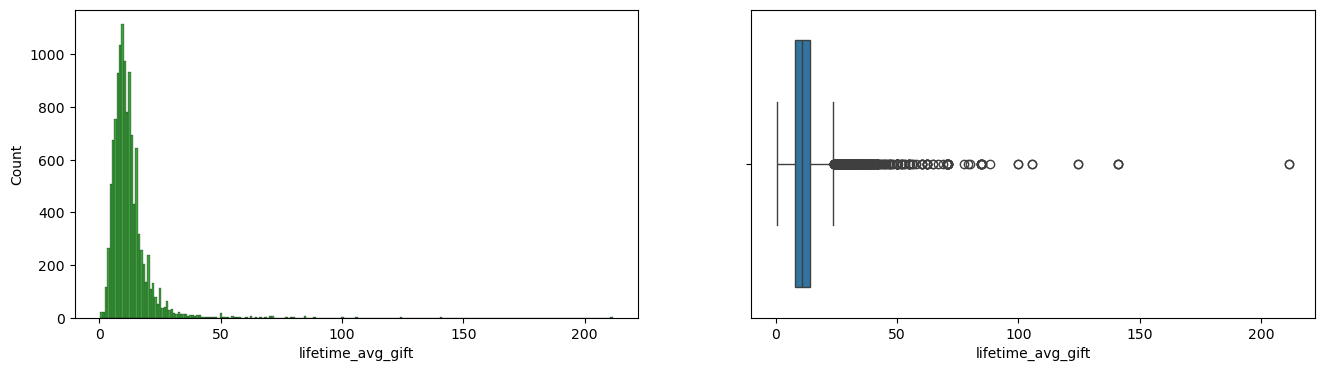

In [100]:
# Meaning: Represents the average donation of a donor
# Relevance: Allows us to distinguish between donors who give a large amount at a time from donors who give small amounts
df_behaviour['lifetime_avg_gift'] = np.where(df_behaviour['lifetime_gift_count'] > 0, df_behaviour['lifetime_gift_amount']/df_behaviour['lifetime_gift_count'],0)
boxplot_hist(df_behaviour, 'lifetime_avg_gift', color_name = 'green')

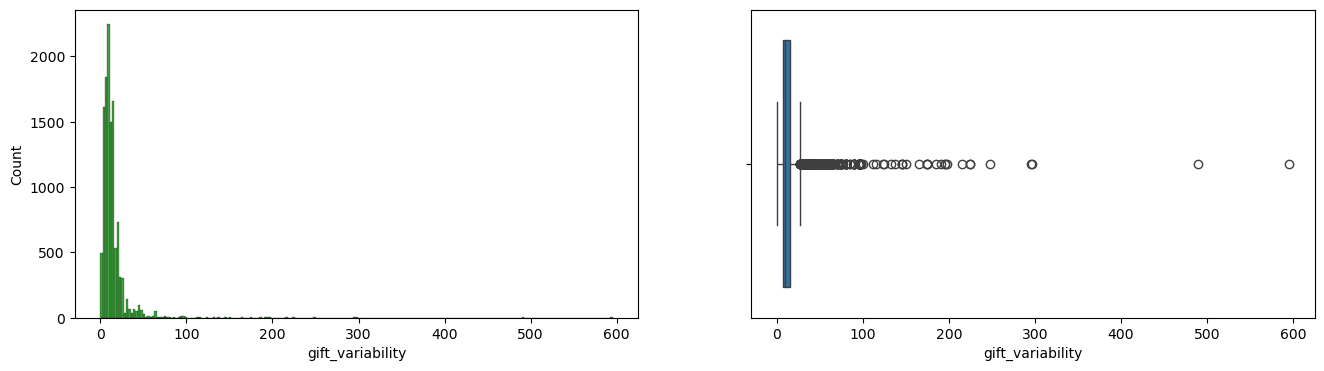

In [101]:
# Meaning: Measures the behaviour of donations
# Relevance: A low variability indicates a stable/predictable donor, whilst a high variability  suggests that the donor  can be highly influenced by the campaigns
df_behaviour['gift_variability'] = df_behaviour['lifetime_max_gift_amt'] - df_behaviour['lifetime_min_gift_amt']
boxplot_hist(df_behaviour, 'gift_variability', color_name = 'green')

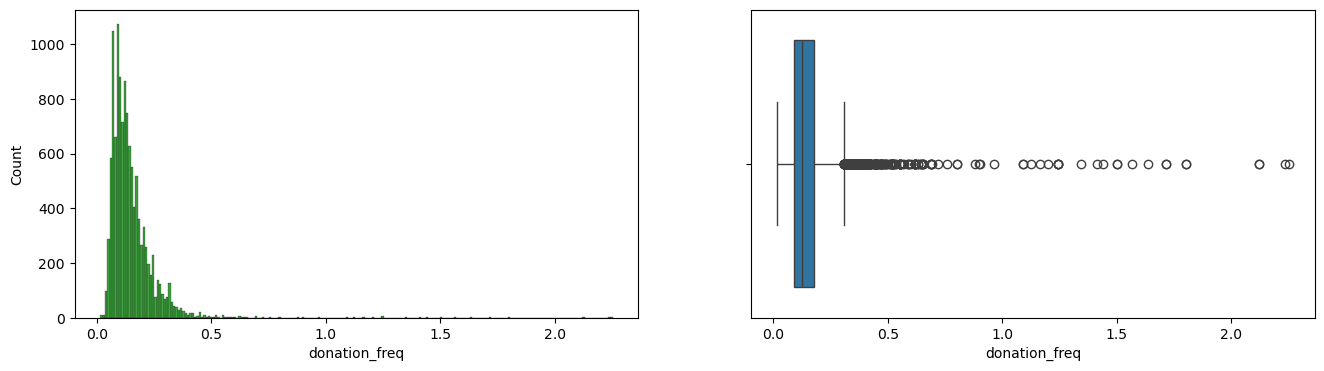

In [102]:
# Meaning: Measures the level of commitment and loyalty through the time
# Relevance: A donor with a high frequency is a faithfull donors independently of the donation amount
df_behaviour['donation_freq'] = np.where(df_behaviour['months_since_first_gift'] > 0, df_behaviour['lifetime_gift_count']/(df_behaviour['months_since_first_gift']),0)
boxplot_hist(df_behaviour, 'donation_freq', color_name = 'green')

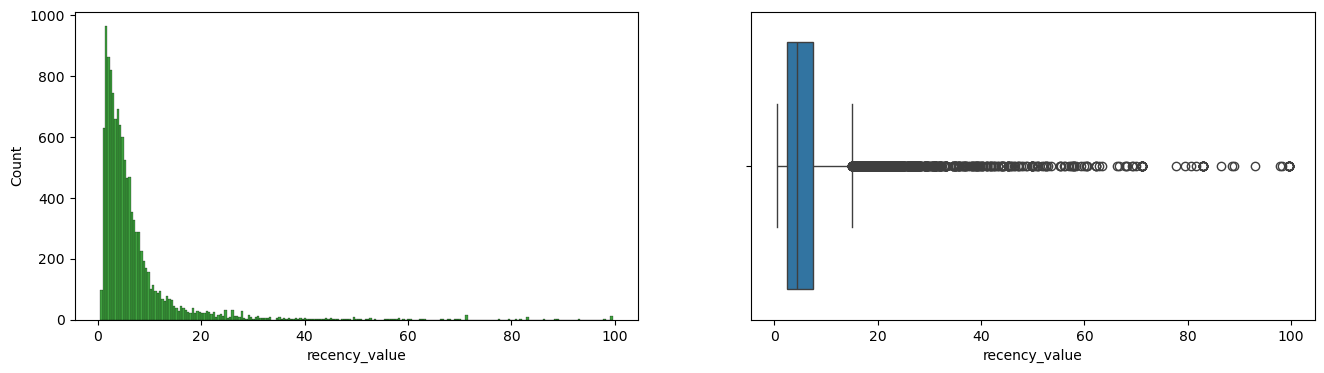

In [103]:
# Meaning: Evaluates the "current value" of the donor for the organization
# Relevance: Donors with a low value used to be frequent donors in the past, whilst a high value means that the donors are active in the current days. This feature is crucial in identifying donors at risk of churn and thos who are active and generous in the present
# recency_value tells us if donors have donated more recently or are lacking
df_behaviour['recency_value'] = df_behaviour['lifetime_gift_amount'] / (1 + df_behaviour['months_since_last_gift'])
boxplot_hist(df_behaviour, 'recency_value', color_name = 'green')

In [104]:
features_to_use_behaviour = ['lifetime_avg_gift','recency_value', 'donation_freq','gift_variability']
for col in features_to_use_behaviour:
  # Here we are capping the features on the 99th percentile
    upper_limit = df_behaviour[col].quantile(0.99)
    df_behaviour[col] = np.where(df_behaviour[col] > upper_limit, upper_limit, df_behaviour[col])
  # Here we compute the
    df_behaviour[col] = np.log1p(df_behaviour[col])
donation_behaviour = df_behaviour[features_to_use_behaviour].copy()

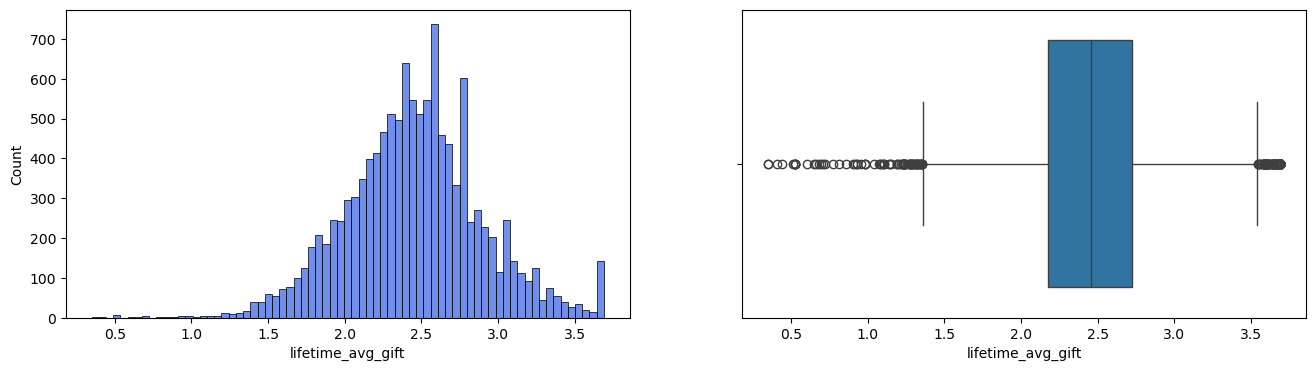

In [105]:
boxplot_hist(donation_behaviour, 'lifetime_avg_gift', color_name = 'royalblue')

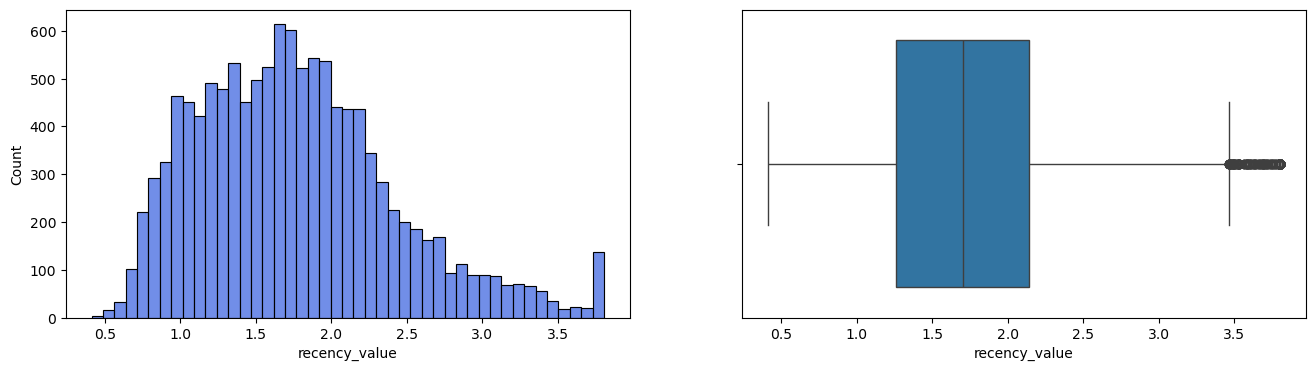

In [106]:
boxplot_hist(df_behaviour, 'recency_value', color_name = 'royalblue')

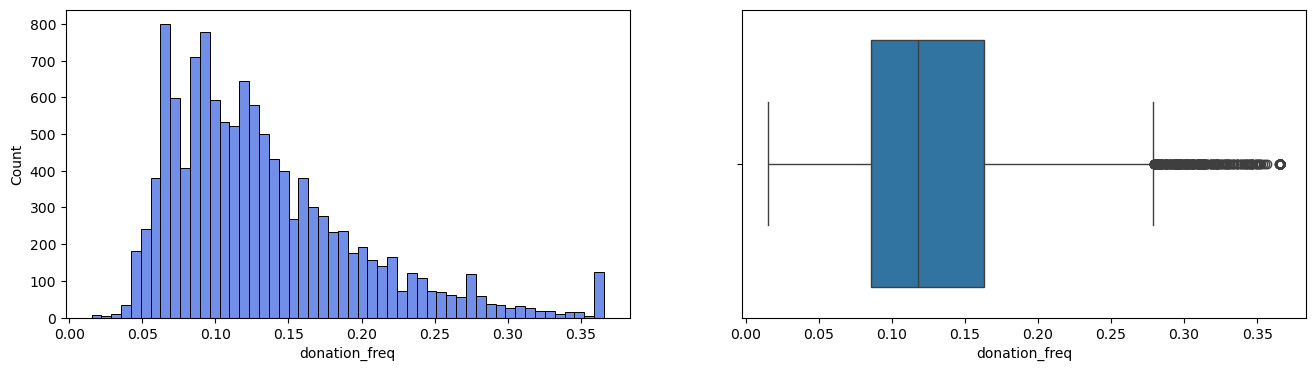

In [107]:
boxplot_hist(df_behaviour, 'donation_freq', color_name = 'royalblue')

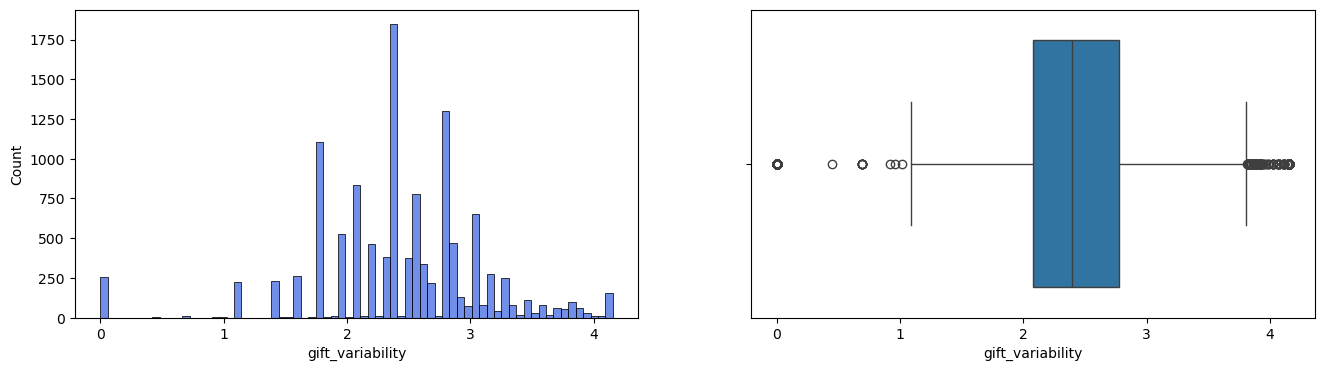

In [108]:
boxplot_hist(df_behaviour, 'gift_variability', color_name = 'royalblue')

---
### 4.3.2. Donation Engagement <a name="donation-engagement"></a>


In [109]:
df_engagement = df_copy.copy()

In [110]:
df_engagement = df_engagement[df_engagement['no_response_flag'] == 0]
# This is a study mainly about people's engagment to cards, so anyone that hasn't received a card or any other promotion should be excluded so we know, to those that are sent cards,
# wich ones respond more or less. Additionally, anyone that hasn't respond at all should also be excluded since we already know that they won't respond to any cards or promotions
# We remove number_prom_12 = 0 beacuase if we haven't sent any promotion than we can't conclude anything about that donor
# df_engagement = df_engagement[(df_engagement['number_prom_12']>0) & (df_engagement['card_prom_12']>0)]
df_engagement = df_engagement[(df_engagement['lifetime_prom']>0) & (df_engagement['lifetime_card_prom']>0) & (df_engagement['recent_response_count']>0)]

In [111]:
# sns.histplot(x='recent_response_count', data = df_copy)
# plt.show()
# sns.histplot(x='number_prom_12', data = df_copy, color = 'orange')

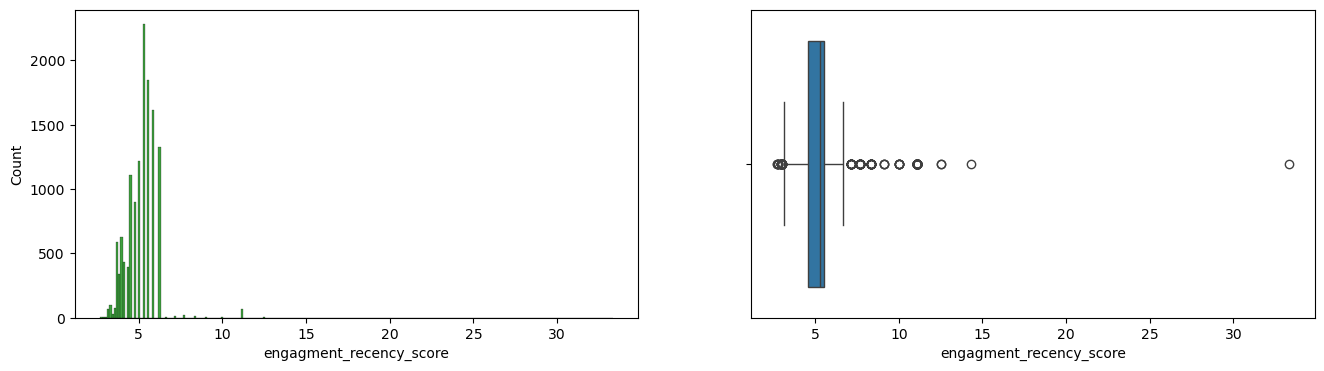

In [112]:
# Meaning: It is like a score and tells if a donor is active or inactive
# Relevance: The more recent the activity is for that donor the higher is the score
df_engagement['engagment_recency_score'] = 100/ (1+df_engagement['months_since_last_prom_resp']) # active or not
boxplot_hist(df_engagement, 'engagment_recency_score', 'green')

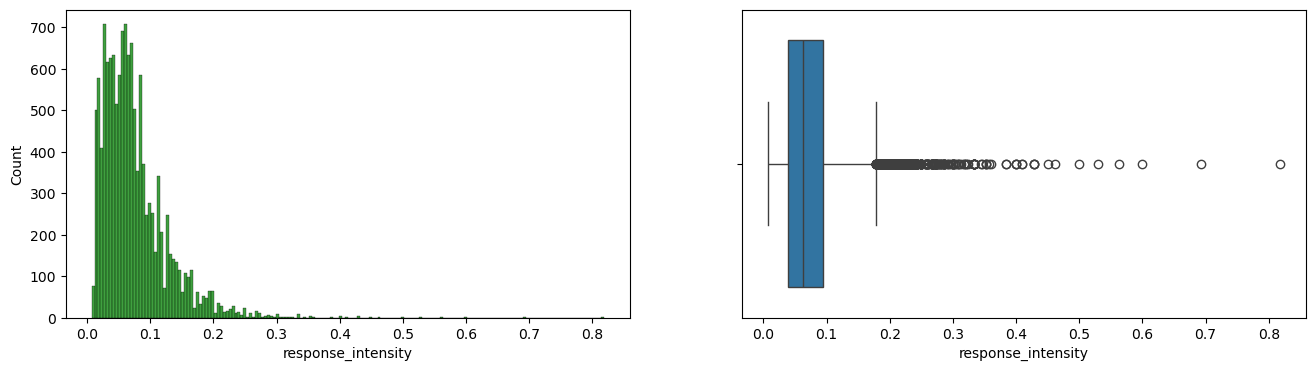

In [113]:
# Meaning: Proportion between the recent response count and the total amount of promotions sent to that individual. It tells us how much people respond to promotions.
# Relevance: It helps seperate the more passive donors from the more enthusiasts
df_engagement['response_intensity'] = (df_engagement['recent_response_count'].astype(float))/(1+df_engagement['lifetime_prom'].astype(float))
boxplot_hist(df_engagement, 'response_intensity', 'green')

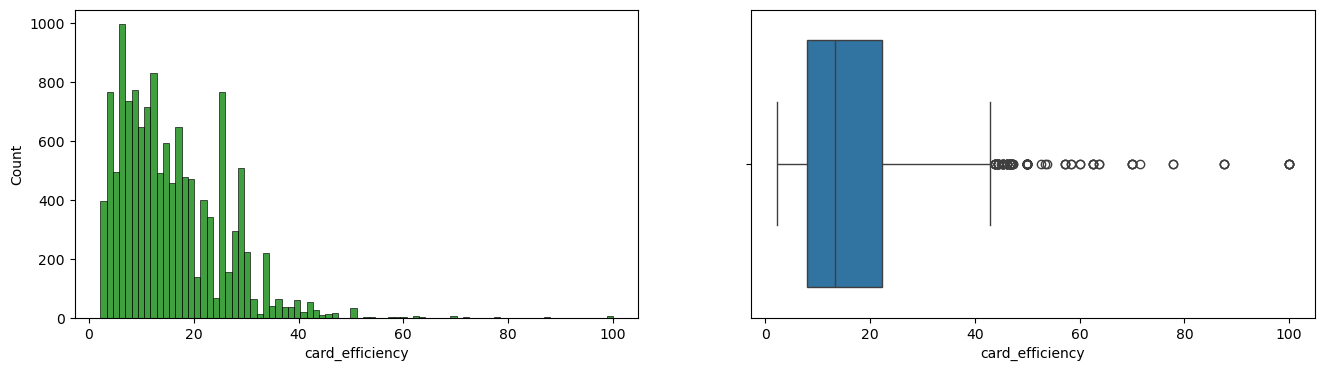

In [114]:
# Meaning: The efficiency of their response to card promotions.
# Relevance: If they have a high count with low card promotion amount this means that this group is very effective to respond to cards if they aren't given to many
df_engagement['card_efficiency'] = (df_engagement['recent_card_response_count']+1)*100/ (2+df_engagement['lifetime_card_prom'])
#The multiplication by 100 derives from the fact that these values are to small and kmeans will have a hard time seperating them. this way it's more like a percentage
boxplot_hist(df_engagement, 'card_efficiency', 'green')

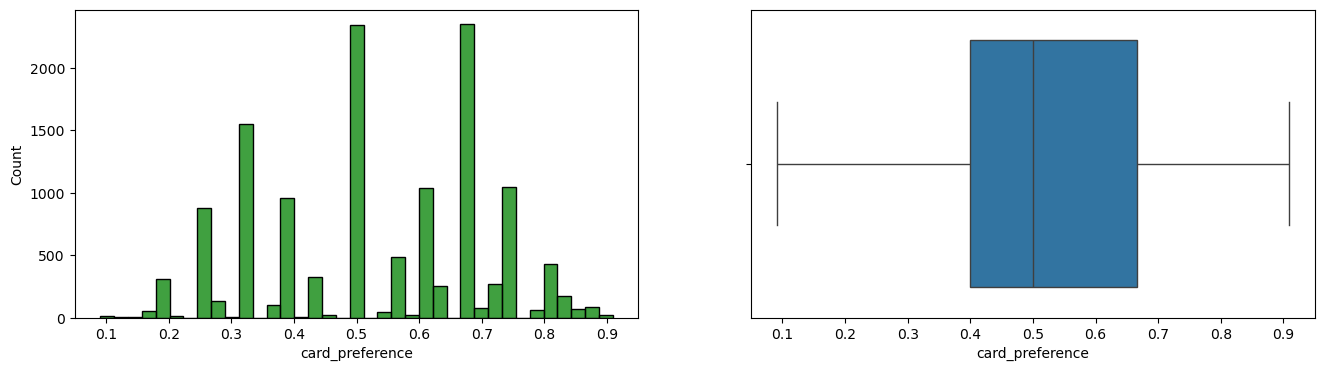

In [115]:
# Meaning: If they prefer cards or other promotions
# Relevance: If this value is closer to 1 than it means that the organization shuld only send cards to this donors
df_engagement['card_preference'] = ((df_engagement['recent_card_response_count']+1) / (2+df_engagement['recent_response_count']))
boxplot_hist(df_engagement, 'card_preference', 'green')

In [116]:
features_to_use_engagement = ['card_efficiency', 'response_intensity', 'engagment_recency_score', 'card_preference']
for col in features_to_use_engagement:
  # Here we are capping the features on the 99th percentile
    upper_limit = df_engagement[col].quantile(0.99)
    df_engagement[col] = np.where(df_engagement[col] > upper_limit, upper_limit, df_engagement[col])
  # Here we compute the
    df_engagement[col] = np.log1p(df_engagement[col])
donation_engagement = df_engagement[features_to_use_engagement].copy()

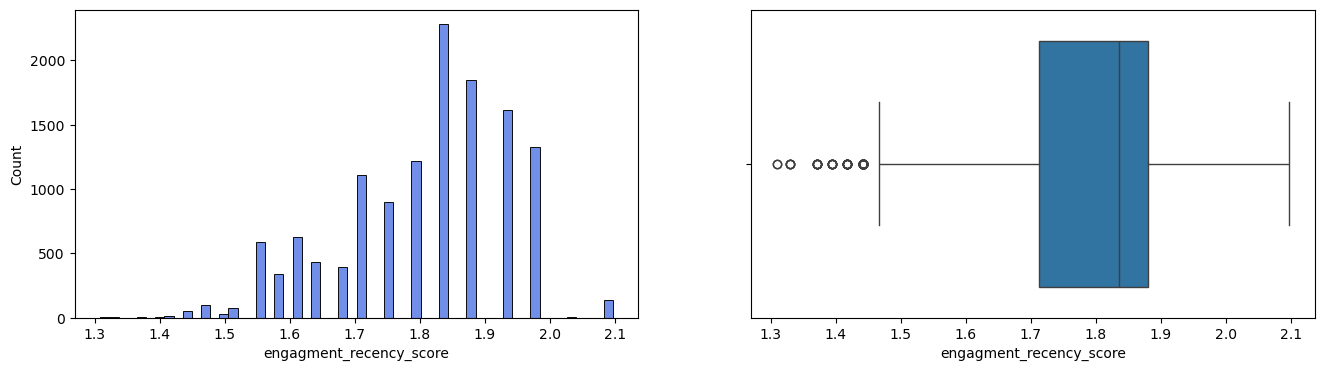

In [117]:
boxplot_hist(df_engagement, 'engagment_recency_score', color_name = 'royalblue')

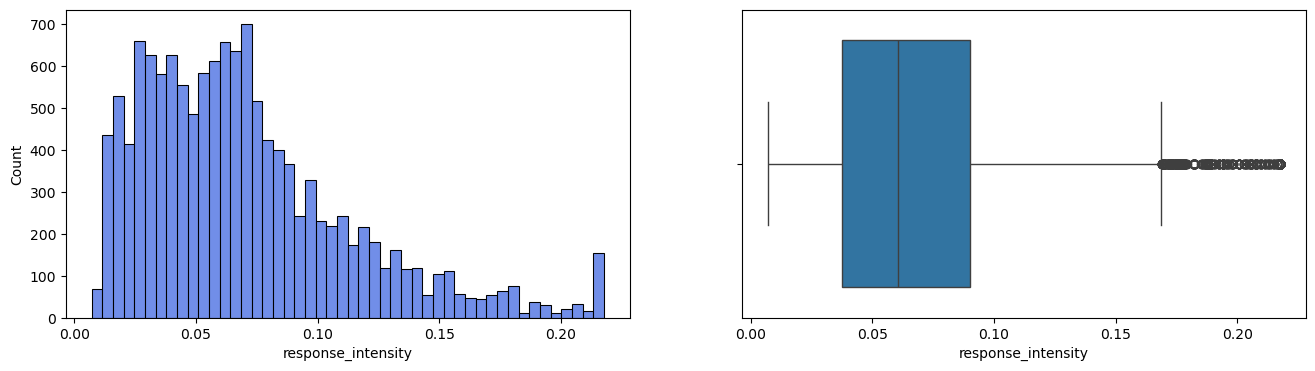

In [118]:
boxplot_hist(df_engagement, 'response_intensity', color_name = 'royalblue')

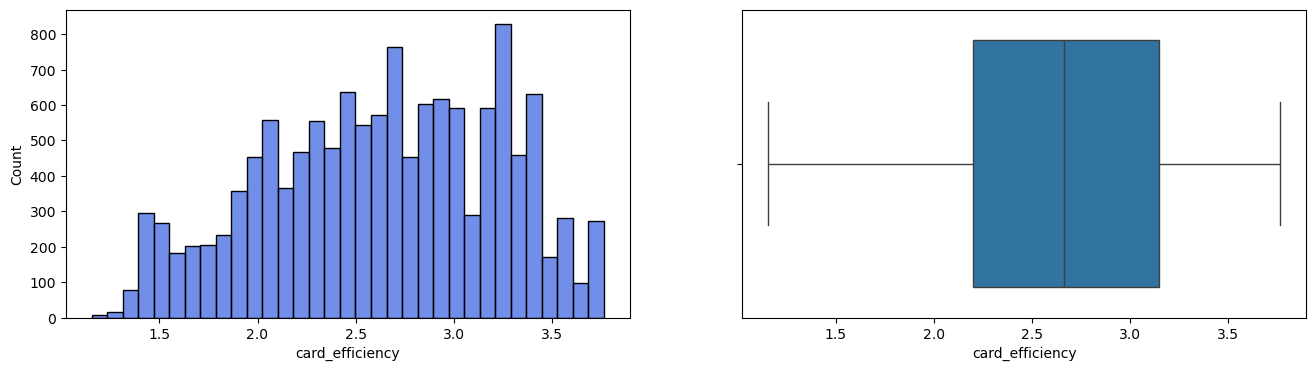

In [119]:
boxplot_hist(df_engagement, 'card_efficiency', color_name = 'royalblue')

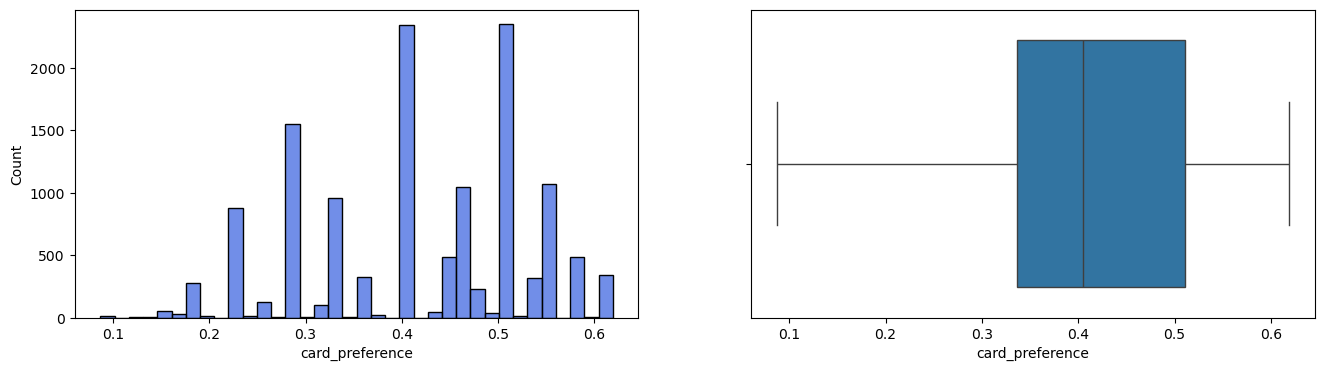

In [120]:
boxplot_hist(df_engagement, 'card_preference', color_name = 'royalblue')

---
# 5.&nbsp; Modelling <a name="modelling"></a>


---
### 5.1. Donation Behaviour <a name="donation-behavior-1"></a>


In [121]:
scaler = MinMaxScaler()
donation_behaviour_scaled = scaler.fit_transform(donation_behaviour)
features = donation_behaviour.columns
donation_behaviour_scaled = pd.DataFrame(donation_behaviour_scaled, columns=features)

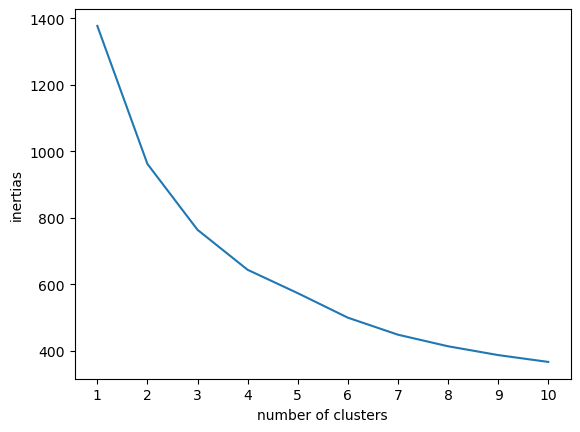

In [122]:
clusters_elbow_method(donation_behaviour_scaled, 10, KMeans, 5)

After running the elbow method we should check for 3 and 4 clusters.
We can also do the dendogram to doublecheck


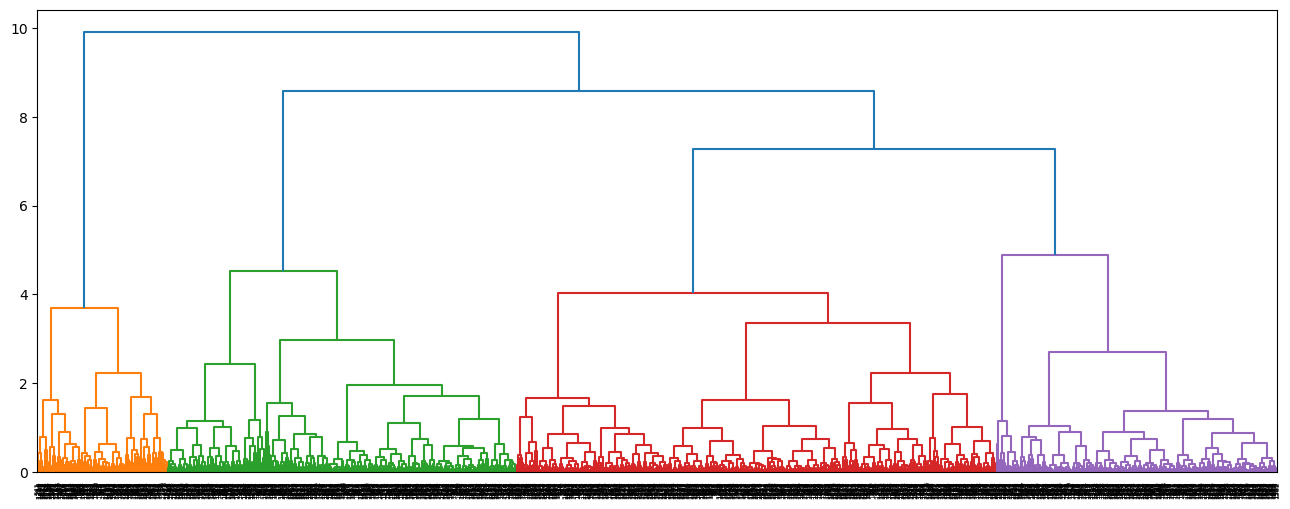

In [123]:
dendogram(donation_behaviour_scaled, 2000)

Based on both the elbow method and the dendogram we can see that we have about 3 to 4 clusters so that's where we are going to focus

k = 3

In [124]:
donation_behaviour_k3, donation_behaviour_model3  = model_criation(fam = donation_behaviour_scaled, n_clusters = 3, cluster_algorithm=KMeans, n_runs=10)
donation_behaviour_k3.groupby("label").mean().transpose()

label,0,1,2
lifetime_avg_gift,0.488866,0.661138,0.708589
recency_value,0.400173,0.283836,0.644703
donation_freq,0.509711,0.215153,0.406208
gift_variability,0.480945,0.576267,0.717623


In [125]:
cluster0 = donation_behaviour_k3[donation_behaviour_k3.label == 0]
cluster1 = donation_behaviour_k3[donation_behaviour_k3.label == 1]
cluster2 = donation_behaviour_k3[donation_behaviour_k3.label == 2]

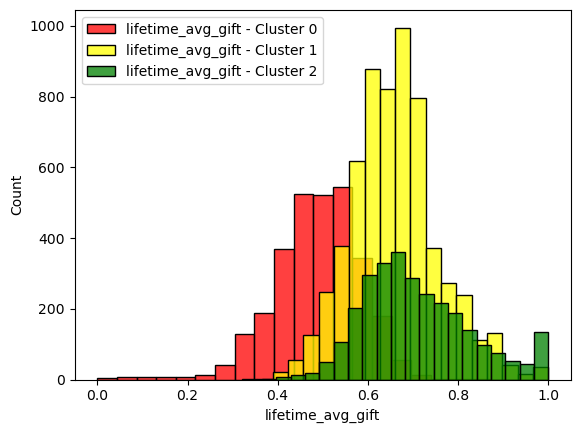

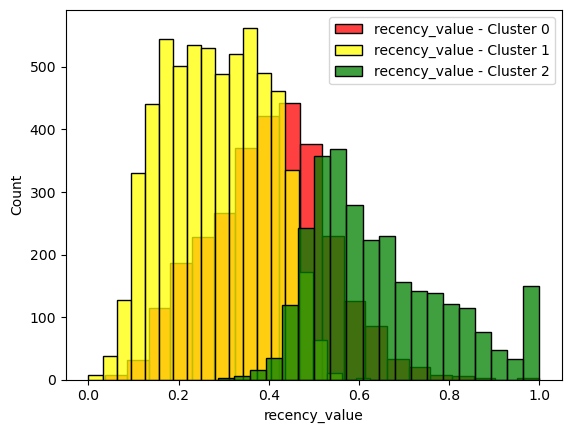

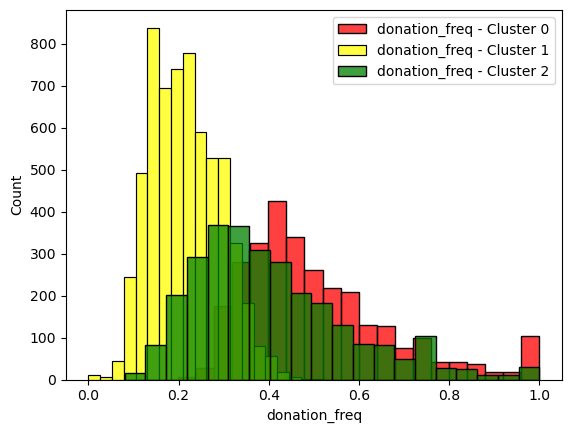

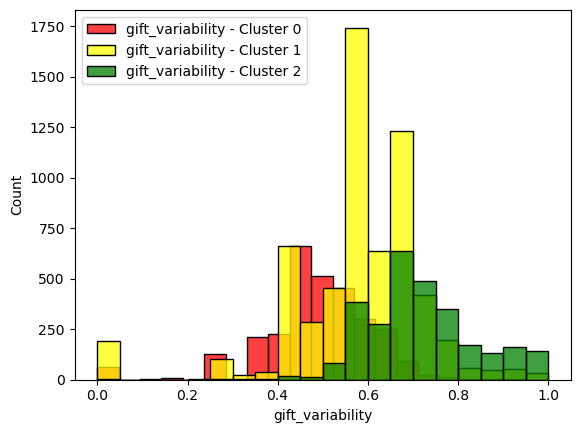

In [126]:
for label in features_to_use_behaviour:
  sns.histplot(cluster0[label],color='red',label=f'{label} - Cluster 0', bins = 20)
  sns.histplot(cluster1[label],color='yellow',label=f'{label} - Cluster 1', bins = 20)
  sns.histplot(cluster2[label],color='green',label=f'{label} - Cluster 2', bins = 20)
  plt.legend()
  plt.show()

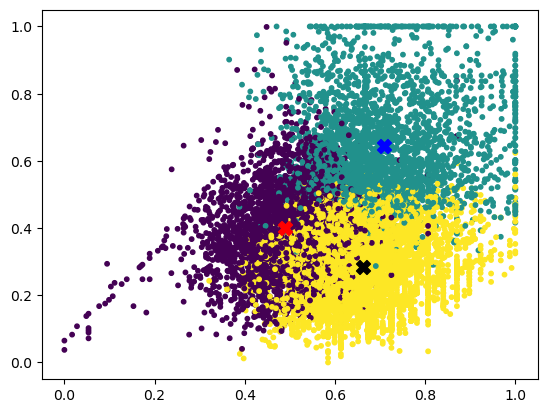

In [127]:
centroids = donation_behaviour_model3.cluster_centers_
c0_x, c0_y = centroids[0, 0], centroids[0, 1]
c1_x, c1_y = centroids[1, 0], centroids[1, 1]
c2_x, c2_y = centroids[2, 0], centroids[2, 1]
plt.scatter(donation_behaviour_k3.iloc[:, 0],
            donation_behaviour_k3.iloc[:, 1],
            c=donation_behaviour_model3.labels_, s=10)

plt.scatter(c0_x, c0_y, marker='X', s=100, color='red')
plt.scatter(c1_x, c1_y, marker='X', s=100, color='blue')
plt.scatter(c2_x, c2_y, marker='X', s=100, color='black')
plt.show()

k = 4

In [128]:
donation_behaviour_k4, donation_behaviour_model4  = model_criation(fam = donation_behaviour_scaled, n_clusters = 4, cluster_algorithm=KMeans, n_runs=10)
donation_behaviour_k4.groupby("label").mean().transpose()

label,0,1,2,3
lifetime_avg_gift,0.491727,0.612960,0.660173,0.718218
recency_value,0.366241,0.700553,0.236722,0.507775
donation_freq,0.447027,0.638829,0.200586,0.275927
gift_variability,0.472957,0.647313,0.545900,0.711992


In [129]:
cluster0 = donation_behaviour_k4[donation_behaviour_k4.label == 0]
cluster1 = donation_behaviour_k4[donation_behaviour_k4.label == 1]
cluster2 = donation_behaviour_k4[donation_behaviour_k4.label == 2]
cluster3 = donation_behaviour_k4[donation_behaviour_k4.label == 3]

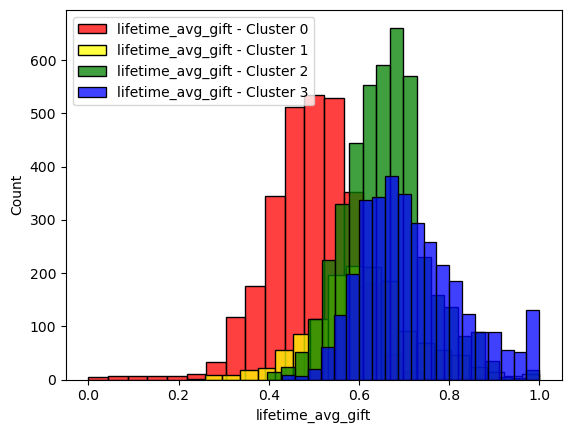

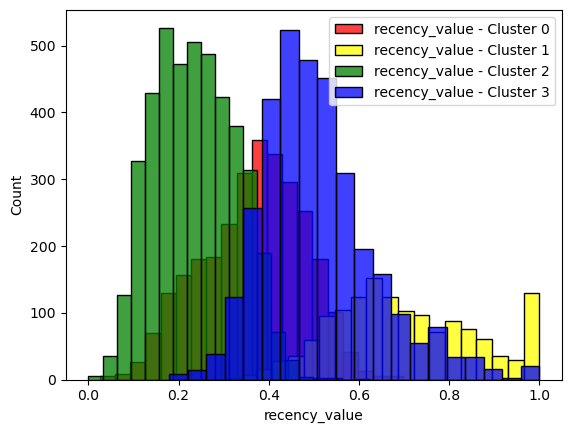

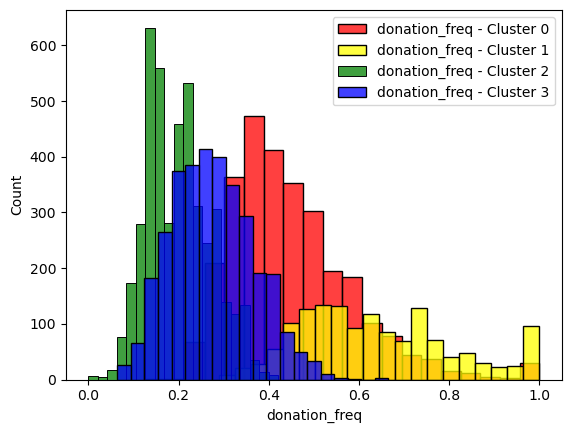

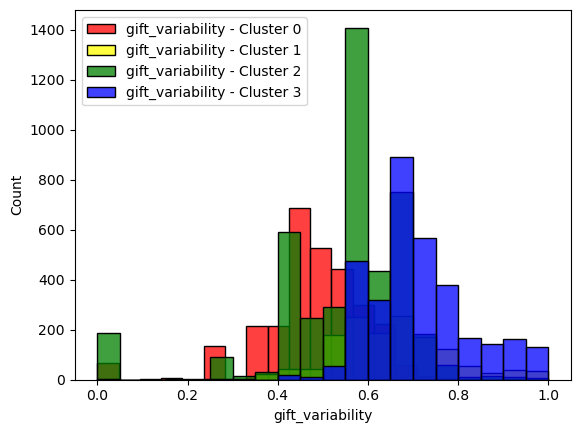

In [130]:
for label in list(donation_behaviour.columns):
  sns.histplot(cluster0[label],color='red',label=f'{label} - Cluster 0', bins = 20)
  sns.histplot(cluster1[label],color='yellow',label=f'{label} - Cluster 1', bins = 20)
  sns.histplot(cluster2[label],color='green',label=f'{label} - Cluster 2', bins = 20)
  sns.histplot(cluster3[label],color='blue',label=f'{label} - Cluster 3', bins = 20)
  plt.legend()
  plt.show()

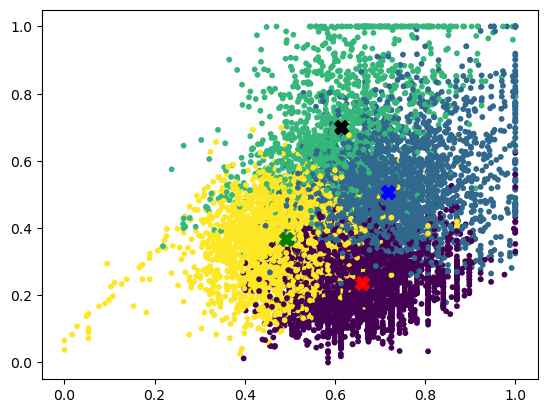

In [131]:
centroids = donation_behaviour_model4.cluster_centers_
c0_x, c0_y = centroids[0, 0], centroids[0, 1]
c1_x, c1_y = centroids[1, 0], centroids[1, 1]
c2_x, c2_y = centroids[2, 0], centroids[2, 1]
c3_x, c3_y = centroids[3, 0], centroids[3, 1]
plt.scatter(donation_behaviour_k4.iloc[:, 0],
            donation_behaviour_k4.iloc[:, 1],
            c=donation_behaviour_model4.labels_, s=10)

plt.scatter(c0_x, c0_y, marker='X', s=100, color='red')
plt.scatter(c1_x, c1_y, marker='X', s=100, color='blue')
plt.scatter(c2_x, c2_y, marker='X', s=100, color='black')
plt.scatter(c3_x, c3_y, marker='X', s=100, color='green')
plt.show()

In [132]:
donation_behaviour_silhouette = clusters_silhouette_method(donation_behaviour_scaled, 6, KMeans, silhouette_score)

For n_clusters = 2 The average silhouette_score is : 0.31051457369228913
For n_clusters = 3 The average silhouette_score is : 0.28540756841601744
For n_clusters = 4 The average silhouette_score is : 0.25629241166117633
For n_clusters = 5 The average silhouette_score is : 0.24766098763067362
For n_clusters = 6 The average silhouette_score is : 0.24069523169098422


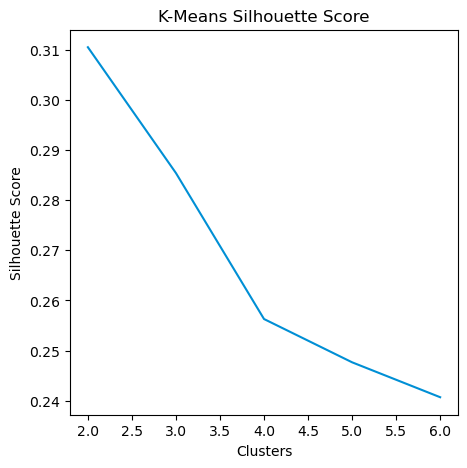

In [133]:
draw_scores(donation_behaviour_silhouette)

### 5.2. Donation Engagement <a name="donation-engagement-1"></a>


In [134]:
scaler = StandardScaler()
donation_engagement_scaled = scaler.fit_transform(donation_engagement)
features = donation_engagement.columns
donation_engagement_scaled = pd.DataFrame(donation_engagement_scaled, columns=features)

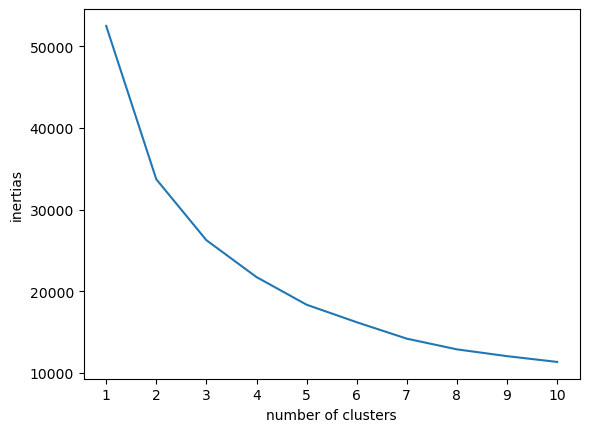

In [135]:
clusters_elbow_method(donation_engagement_scaled, 10, KMeans, n_runs = 20)

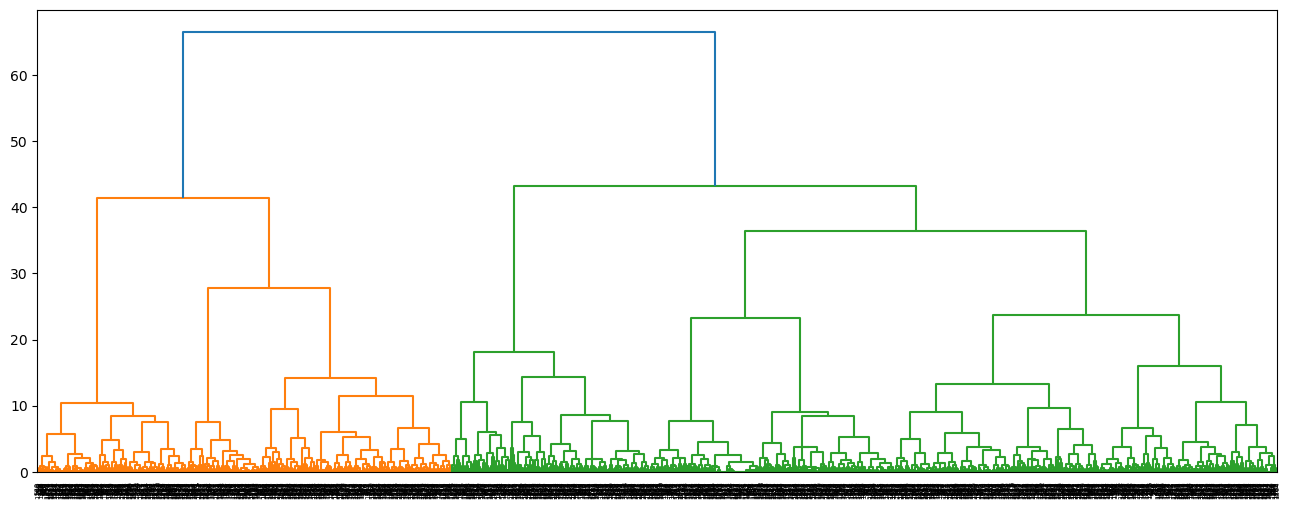

In [136]:
dendogram(donation_engagement_scaled, 2000)

In [137]:
donation_engagement_k2, donation_engagement_model2 = model_criation(fam=donation_engagement_scaled, n_clusters=2, cluster_algorithm=KMeans)
donation_engagement_k2.groupby("label").mean().transpose()

label,0,1
card_efficiency,-0.867796,0.770666
response_intensity,-0.614938,0.546110
engagment_recency_score,-0.222392,0.197501
card_preference,-0.656241,0.582791


In [138]:
cluster0 = donation_engagement_k2[donation_engagement_k2.label == 0]
cluster1 = donation_engagement_k2[donation_engagement_k2.label == 1]

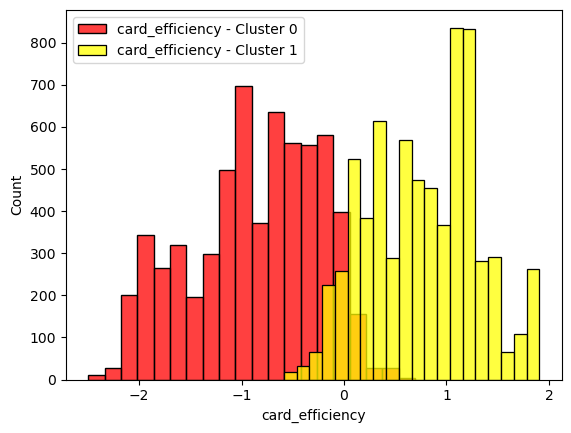

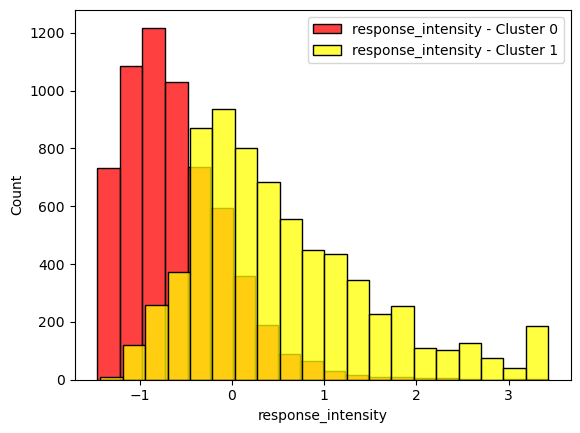

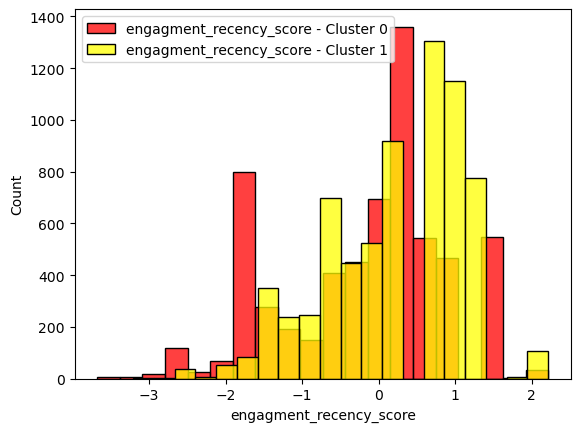

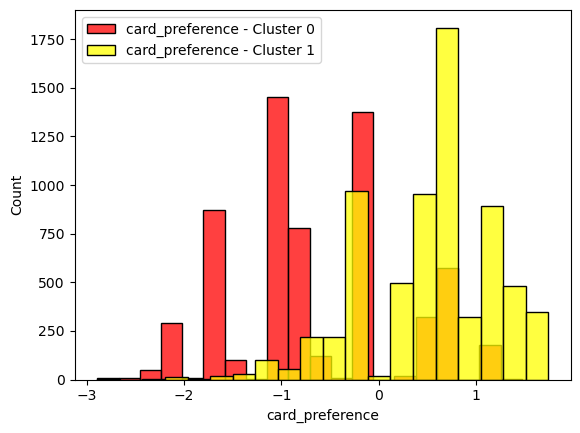

In [139]:
for label in list(donation_engagement.columns):
  sns.histplot(cluster0[label],color='red',label=f'{label} - Cluster 0', bins = 20)
  sns.histplot(cluster1[label],color='yellow',label=f'{label} - Cluster 1', bins = 20)
  plt.legend()
  plt.show()

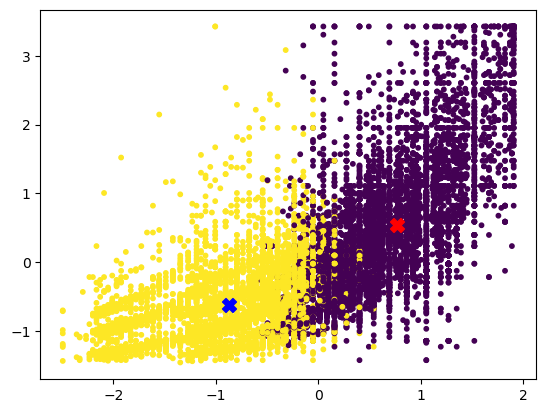

In [140]:
centroids = donation_engagement_model2.cluster_centers_
c0_x, c0_y = centroids[0, 0], centroids[0, 1]
c1_x, c1_y = centroids[1, 0], centroids[1, 1]
plt.scatter(donation_engagement_k2.iloc[:, 0],
            donation_engagement_k2.iloc[:, 1],
            c=donation_engagement_model2.labels_, s=10)

plt.scatter(c0_x, c0_y, marker='X', s=100, color='red')
plt.scatter(c1_x, c1_y, marker='X', s=100, color='blue')
plt.show()

K=3

In [141]:
donation_engagement_k3, donation_engagement_model3  = model_criation(fam = donation_engagement_scaled, n_clusters = 3, cluster_algorithm=KMeans)
donation_engagement_k3.groupby("label").mean().transpose()

label,0,1,2
card_efficiency,-1.044563,0.105852,0.914108
response_intensity,-0.555443,-0.451489,0.962014
engagment_recency_score,0.032899,-0.667459,0.593698
card_preference,-1.078660,0.664952,0.423137


Using 3 clusters, we can conclude:
- cluster 1 - These are the people thaat aren't the most active or inactive. They are in the midle, but they are not the ones to send cards. These people should receive more of other promotions.
- cluster 2 - These are the ones that haven't responded in a while. They are also the ones that prefer cards. This means that they respond more to cards than any other group of people so they should receive more cards than any other promotion.
- cluster 0 - These donors are more frequent to respond to promotions and have the most recent action. Most of their card promotions have been answered. Cards are not their preference wich could indicate that they also respond a lot to other promotions.

In [142]:
cluster0 = donation_engagement_k3[donation_engagement_k3.label == 0]
cluster1 = donation_engagement_k3[donation_engagement_k3.label == 1]
cluster2 = donation_engagement_k3[donation_engagement_k3.label == 2]

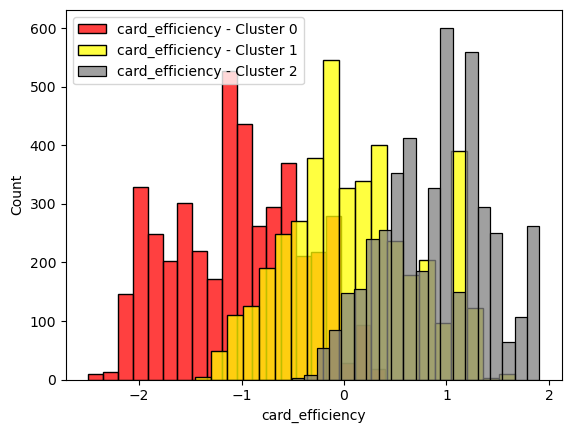

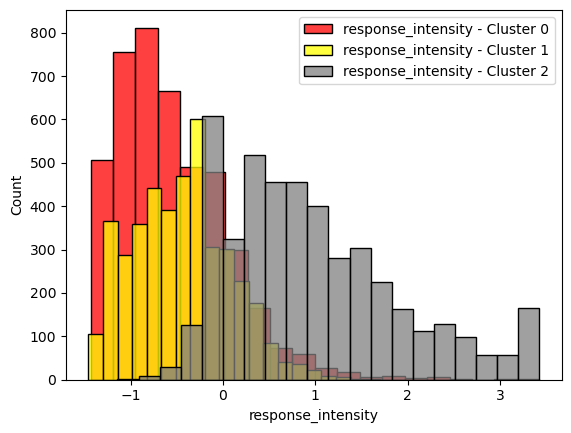

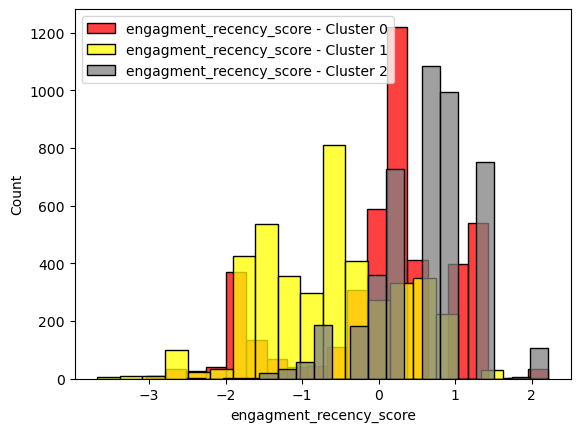

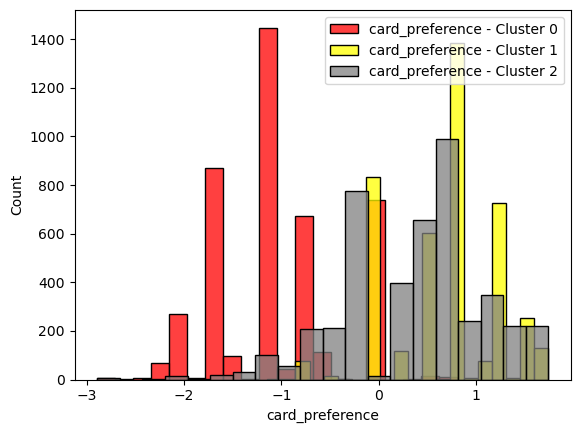

In [143]:
for label in list(donation_engagement.columns):
  sns.histplot(cluster0[label],color='red',label=f'{label} - Cluster 0', bins = 20)
  sns.histplot(cluster1[label],color='yellow',label=f'{label} - Cluster 1', bins = 20)
  sns.histplot(cluster2[label],color='grey',label=f'{label} - Cluster 2', bins = 20)
  plt.legend()
  plt.show()

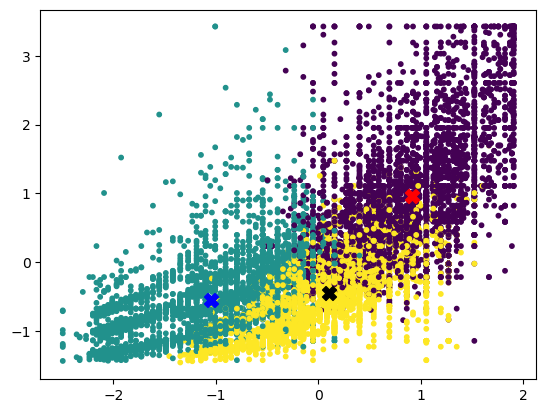

In [144]:
centroids = donation_engagement_model3.cluster_centers_
c0_x, c0_y = centroids[0, 0], centroids[0, 1]
c1_x, c1_y = centroids[1, 0], centroids[1, 1]
c2_x, c2_y = centroids[2, 0], centroids[2, 1]
plt.scatter(donation_engagement_k3.iloc[:, 0],
            donation_engagement_k3.iloc[:, 1],
            c=donation_engagement_model3.labels_, s=10)

plt.scatter(c0_x, c0_y, marker='X', s=100, color='red')
plt.scatter(c1_x, c1_y, marker='X', s=100, color='blue')
plt.scatter(c2_x, c2_y, marker='X', s=100, color='black')
plt.show()

k=4

In [145]:
donation_engagement_k4, donation_engagement_model4  = model_criation(fam = donation_engagement_scaled, n_clusters = 4, cluster_algorithm=KMeans)
donation_engagement_k4.groupby("label").mean().transpose()

label,0,1,2,3
card_efficiency,-0.938429,-0.766109,0.497708,1.077226
response_intensity,-0.465769,-0.733617,-0.147281,1.618043
engagment_recency_score,0.479309,-1.530494,0.033859,0.541888
card_preference,-1.034036,-0.283337,0.771411,0.262379


In [146]:
cluster0 = donation_engagement_k4[donation_engagement_k4.label == 0]
cluster1 = donation_engagement_k4[donation_engagement_k4.label == 1]
cluster2 = donation_engagement_k4[donation_engagement_k4.label == 2]
cluster3 = donation_engagement_k4[donation_engagement_k4.label == 3]

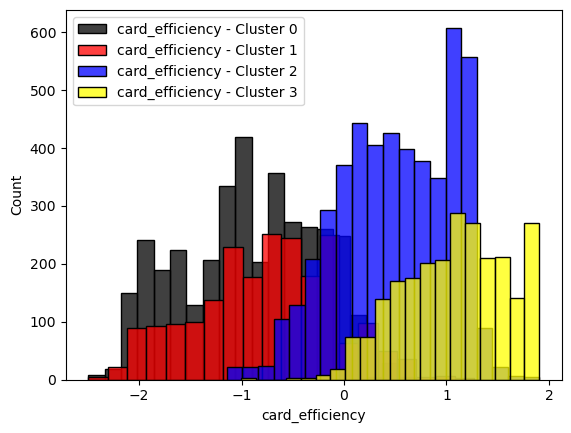

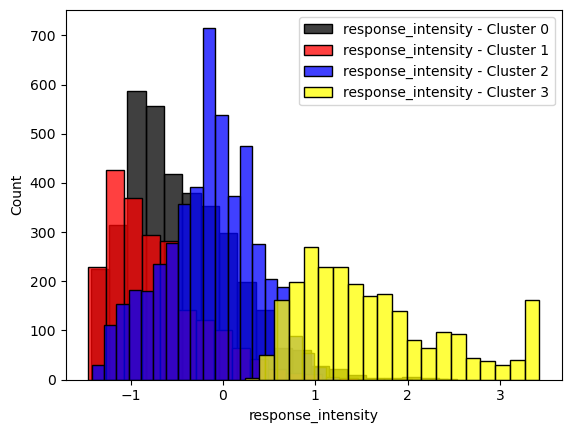

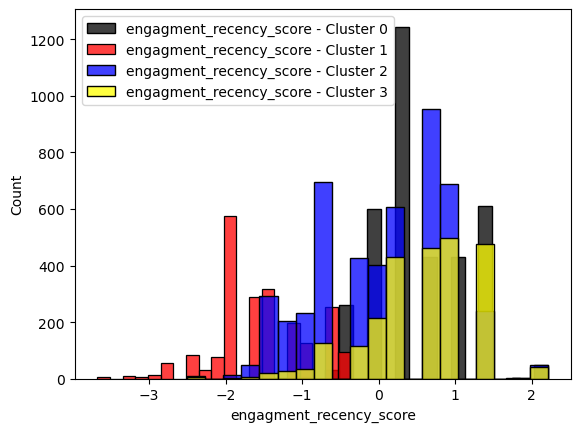

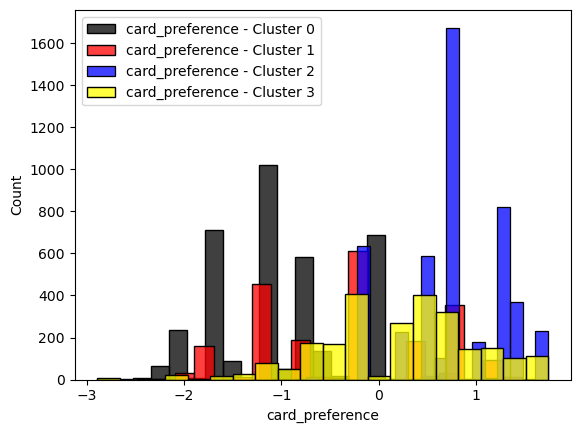

In [147]:
for label in list(donation_engagement.columns):
  sns.histplot(cluster0[label],color='black',label=f'{label} - Cluster 0', bins = 20)
  sns.histplot(cluster1[label],color='red',label=f'{label} - Cluster 1', bins = 20)
  sns.histplot(cluster2[label],color='blue',label=f'{label} - Cluster 2', bins = 20)
  sns.histplot(cluster3[label],color='yellow',label=f'{label} - Cluster 3', bins = 20)
  plt.legend()
  plt.show()

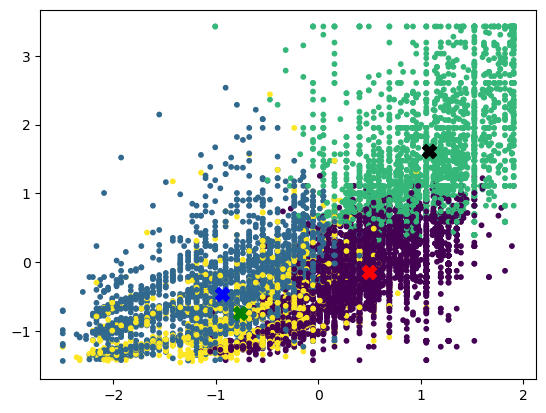

In [148]:
centroids = donation_engagement_model4.cluster_centers_
c0_x, c0_y = centroids[0, 0], centroids[0, 1]
c1_x, c1_y = centroids[1, 0], centroids[1, 1]
c2_x, c2_y = centroids[2, 0], centroids[2, 1]
c3_x, c3_y = centroids[3, 0], centroids[3, 1]
plt.scatter(donation_engagement_k4.iloc[:, 0],
            donation_engagement_k4.iloc[:, 1],
            c=donation_engagement_model4.labels_, s=10)

plt.scatter(c0_x, c0_y, marker='X', s=100, color='red')
plt.scatter(c1_x, c1_y, marker='X', s=100, color='blue')
plt.scatter(c2_x, c2_y, marker='X', s=100, color='black')
plt.scatter(c3_x, c3_y, marker='X', s=100, color='green')
plt.show()

In [149]:
donation_engagement_silhouette = clusters_silhouette_method(donation_engagement_scaled, 4, KMeans, silhouette_score)

For n_clusters = 2 The average silhouette_score is : 0.31261875603656264
For n_clusters = 3 The average silhouette_score is : 0.28166198123909314
For n_clusters = 4 The average silhouette_score is : 0.2804080139208706


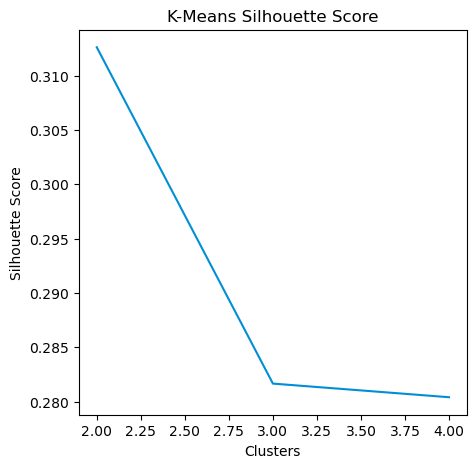

In [150]:
draw_scores(donation_engagement_silhouette)

# 6. Action Plan

In [151]:
donation_behaviour_k3.groupby("label").mean().transpose()

label,0,1,2
lifetime_avg_gift,0.488866,0.661138,0.708589
recency_value,0.400173,0.283836,0.644703
donation_freq,0.509711,0.215153,0.406208
gift_variability,0.480945,0.576267,0.717623


## Cluster 0 — FREQUENT SMALL DONORS (LOYAL)

These donors are the most reliable:
 - The most frequent to donate
 - Even though it's the lowest average amount they are consistent with it making them reliable and necessary

## Cluster 1 — LEAST RELIABLE DONORS

These donors are the least reliable:
 - They haven't donated in a while and are not very frequent donors
 - They are also not very fixed with the amount

## Cluster 2 — HIGH VALUE, HIGH VARIABILITY

These are our best donors:
 - Still active (most recent to donate)
 - average frequency donation
 - highest average amounts eventhough they may vary more

In [152]:
donation_behaviour_k4.groupby("label").mean().transpose()

label,0,1,2,3
lifetime_avg_gift,0.491727,0.612960,0.660173,0.718218
recency_value,0.366241,0.700553,0.236722,0.507775
donation_freq,0.447027,0.638829,0.200586,0.275927
gift_variability,0.472957,0.647313,0.545900,0.711992


## Cluster 0  — GETTING TO UNRELIABLE

 - Donation of small fixed amounts
 - they are the second to most inactive

## Cluster 1 — FREQUENT SMALL DONORS (LOYAL)

These donors are the most loyal:
 - The most frequent to donate and the most recent also
 - They donate mostly random lower amounts

## Cluster 2 — LEAST RELIABLE DONORS

These donors are the least reliable:
 - They haven't donated in a while and are not very frequent donors
 - They are also not very fixed with the amount

## Cluster 3 — HIGH VALUE, HIGH VARIABILITY

These are our best donors:
 - Still active
 - Highest average amounts eventhough they may vary more
 - Not the most frequent donators

In [153]:
X = donation_behaviour_scaled.values

print("=== Model comparison ===")
print(f"{'k':<6} {'Silhouette':>10} {'Davies-Bouldin':>17} {'Sizes'}")
for k, labs in [(3, donation_behaviour_model3.labels_),
                (4, donation_behaviour_model4.labels_)]:
    sil = silhouette_score(X, labs)
    db  = davies_bouldin_score(X, labs)
    sizes = dict(pd.Series(labs).value_counts().sort_index())
    print(f"k={k}    sil={sil:.4f}    DB={db:.4f}    {sizes}")

=== Model comparison ===
k      Silhouette    Davies-Bouldin Sizes
k=3    sil=0.2854    DB=1.1965    {0: np.int64(2957), 1: np.int64(2859), 2: np.int64(6162)}
k=4    sil=0.2564    DB=1.1649    {0: np.int64(4331), 1: np.int64(3320), 2: np.int64(1435), 3: np.int64(2892)}


 - Silhouette at k=3 is higher
 - Davies-Bouldin at k=4 is lower

 Decision: k=3 is chosen as the primary model.

 This decision derives from the fact that we have similar scores for both silhouette and Davies-Bouldin and so the decision comes down to what prespective we want to approach. In this case with 3 clusters we have clear groups of people that we can focus.
 Even though the results are not perfect and the scores are considered below to what a good cluster should have, this was expected from the beggining. We are dealing with people's data and they don't necessary fit 100% into a specified group and so there will always be gray areas.



---


## Recommendations


---



For frequent small donors:
- Suggest slightly higher donation amounts (very small increase)
- Recognition (badges, emails, thank-you messages for the loyalty)
- Take advantage of the frequency and encorage monthly givings

For high value, high variability donors:
 - Highlight impact of their donations
 - Exclusive campaigns and prices
 - Special events including joining these donors to the benefiters


For the least reliable donors:
- Don't spend too much effort/resources
- Small suggested donations
- Big reduction of promotions sent to these donors to relieve the pressure to try and make them want to come back
